In [1]:
import pandas as pd

file_path = r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171213_week.csv"

df = pd.read_csv(file_path)

print("Rows, Columns:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()



Rows, Columns: (670084, 22)

Columns:
['DayNum', 'VehId', 'Trip', 'Timestamp(ms)', 'Latitude[deg]', 'Longitude[deg]', 'Vehicle Speed[km/h]', 'MAF[g/sec]', 'Engine RPM[RPM]', 'Absolute Load[%]', 'OAT[DegC]', 'Fuel Rate[L/hr]', 'Air Conditioning Power[kW]', 'Air Conditioning Power[Watts]', 'Heater Power[Watts]', 'HV Battery Current[A]', 'HV Battery SOC[%]', 'HV Battery Voltage[V]', 'Short Term Fuel Trim Bank 1[%]', 'Short Term Fuel Trim Bank 2[%]', 'Long Term Fuel Trim Bank 1[%]', 'Long Term Fuel Trim Bank 2[%]']


,DayNum,VehId,Trip,Timestamp(ms),Latitude[deg],Longitude[deg],Vehicle Speed[km/h],MAF[g/sec],Engine RPM[RPM],Absolute Load[%],...,Air Conditioning Power[kW],Air Conditioning Power[Watts],Heater Power[Watts],HV Battery Current[A],HV Battery SOC[%],HV Battery Voltage[V],Short Term Fuel Trim Bank 1[%],Short Term Fuel Trim Bank 2[%],Long Term Fuel Trim Bank 1[%],Long Term Fuel Trim Bank 2[%]
0,43.927708,8,854,0,42.302558,-83.704247,17.0,4.25,932.0,16.470589,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,5.46875,NaN
1,43.927708,8,854,1000,42.302558,-83.704247,15.0,4.25,932.0,16.470589,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,5.46875,NaN
2,43.927708,8,854,2100,42.302558,-83.704247,11.0,3.76,1214.0,16.470589,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,5.46875,NaN
3,43.927708,8,854,2500,42.302609,-83.704217,11.0,3.76,1214.0,16.470589,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,5.46875,NaN
4,43.927708,8,854,3100,42.302609,-83.704217,8.0,3.76,1214.0,16.470589,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,5.46875,NaN


In [2]:
df.shape

(670084, 22)

In [3]:
print(df.columns.tolist())


['DayNum', 'VehId', 'Trip', 'Timestamp(ms)', 'Latitude[deg]', 'Longitude[deg]', 'Vehicle Speed[km/h]', 'MAF[g/sec]', 'Engine RPM[RPM]', 'Absolute Load[%]', 'OAT[DegC]', 'Fuel Rate[L/hr]', 'Air Conditioning Power[kW]', 'Air Conditioning Power[Watts]', 'Heater Power[Watts]', 'HV Battery Current[A]', 'HV Battery SOC[%]', 'HV Battery Voltage[V]', 'Short Term Fuel Trim Bank 1[%]', 'Short Term Fuel Trim Bank 2[%]', 'Long Term Fuel Trim Bank 1[%]', 'Long Term Fuel Trim Bank 2[%]']


In [4]:
print("Vehicles:", df["VehId"].nunique())
print("Trips:", df["Trip"].nunique())

Vehicles: 255
Trips: 637


In [5]:
df[["VehId","Trip"]].describe()

,VehId,Trip
count,670084.000000,670084.000000
mean,383.122770,935.898104
std,143.670254,455.838153
min,5.000000,110.000000
25%,267.000000,639.000000
50%,409.000000,954.000000
75%,488.000000,1248.000000
max,609.000000,2118.000000


In [6]:
missing = df.isnull().sum()

missing.sort_values(ascending=False)

Heater Power[Watts]               662260
Air Conditioning Power[kW]        653898
Fuel Rate[L/hr]                   653898
Air Conditioning Power[Watts]     613519
HV Battery SOC[%]                 597333
HV Battery Voltage[V]             597333
HV Battery Current[A]             597333
OAT[DegC]                         597333
Long Term Fuel Trim Bank 2[%]     483133
Short Term Fuel Trim Bank 2[%]    482947
Absolute Load[%]                  149014
MAF[g/sec]                        114393
Short Term Fuel Trim Bank 1[%]     83844
Long Term Fuel Trim Bank 1[%]      83844
Engine RPM[RPM]                     7824
Latitude[deg]                          0
Longitude[deg]                         0
Trip                                   0
VehId                                  0
DayNum                                 0
Timestamp(ms)                          0
Vehicle Speed[km/h]                    0
dtype: int64

In [7]:
df[[
    'Vehicle Speed[km/h]',
    'HV Battery SOC[%]',
    'OAT[DegC]'
]].describe()

,Vehicle Speed[km/h],HV Battery SOC[%],OAT[DegC]
count,670084.000000,72751.000000,72751.000000
mean,33.534019,31.353109,-5.656702
std,24.704279,35.305300,3.369587
min,0.000000,0.000000,-14.000000
25%,12.000000,0.000000,-7.750000
50%,34.000000,10.000000,-6.750000
75%,51.000000,71.764732,-4.000000
max,132.000000,98.321526,4.250000


In [8]:
ev_df = df[df["HV Battery SOC[%]"].notna()]

print("Rows:", ev_df.shape[0])
print("Vehicles:", ev_df["VehId"].nunique())
print("Trips:", ev_df["Trip"].nunique())

Rows: 72751
Vehicles: 16
Trips: 65


In [9]:
sorted(ev_df["VehId"].unique())

[np.int64(11),
 np.int64(371),
 np.int64(388),
 np.int64(398),
 np.int64(417),
 np.int64(443),
 np.int64(449),
 np.int64(453),
 np.int64(455),
 np.int64(457),
 np.int64(536),
 np.int64(537),
 np.int64(554),
 np.int64(560),
 np.int64(561),
 np.int64(569)]

In [10]:
ev_df = df[df["HV Battery SOC[%]"].notna()]

print("Rows:", ev_df.shape[0])
print("Vehicles:", ev_df["VehId"].nunique())
print("Trips:", ev_df["Trip"].nunique())

Rows: 72751
Vehicles: 16
Trips: 65


In [11]:
ev_df["Battery_Power_W"] = (
    ev_df["HV Battery Voltage[V]"] *
    ev_df["HV Battery Current[A]"]
)

ev_df["Battery_Power_kW"] = ev_df["Battery_Power_W"] / 1000

In [12]:
ev_df["Battery_Power_kW"].describe()


count    72751.000000
mean        -2.530009
std         10.325762
min        -62.342235
25%         -6.538307
50%         -1.362749
75%          2.904300
max         50.508000
Name: Battery_Power_kW, dtype: float64

In [13]:
ev_df[[
    "Vehicle Speed[km/h]",
    "HV Battery Current[A]",
    "HV Battery Voltage[V]",
    "Battery_Power_kW"
]].head(20)

,Vehicle Speed[km/h],HV Battery Current[A],HV Battery Voltage[V],Battery_Power_kW
1990,33.559998,-102.549988,294.5,-30.200971
1991,37.209999,-102.549988,294.5,-30.200971
1992,37.209999,-102.549988,287.0,-29.431846
1993,40.430000,-101.799988,287.0,-29.216596
1994,43.189999,-90.950012,287.0,-26.102654
1995,43.189999,-90.950012,287.0,-26.102654
1996,43.610001,-23.200012,287.0,-6.658404
1997,44.009998,-67.000000,287.0,-19.229000
1998,44.820000,-16.000000,287.0,-4.592000
1999,44.820000,-16.000000,299.0,-4.784000


In [14]:
ev_df["Vehicle Speed[km/h]"].describe()

count    72751.000000
mean        32.355301
std         21.475435
min          0.000000
25%         14.090000
50%         34.000000
75%         49.000000
max        102.234375
Name: Vehicle Speed[km/h], dtype: float64

In [15]:
ev_df["HV Battery SOC[%]"].describe()

count    72751.000000
mean        31.353109
std         35.305300
min          0.000000
25%          0.000000
50%         10.000000
75%         71.764732
max         98.321526
Name: HV Battery SOC[%], dtype: float64

In [16]:
ev_df["OAT[DegC]"].describe()

count    72751.000000
mean        -5.656702
std          3.369587
min        -14.000000
25%         -7.750000
50%         -6.750000
75%         -4.000000
max          4.250000
Name: OAT[DegC], dtype: float64

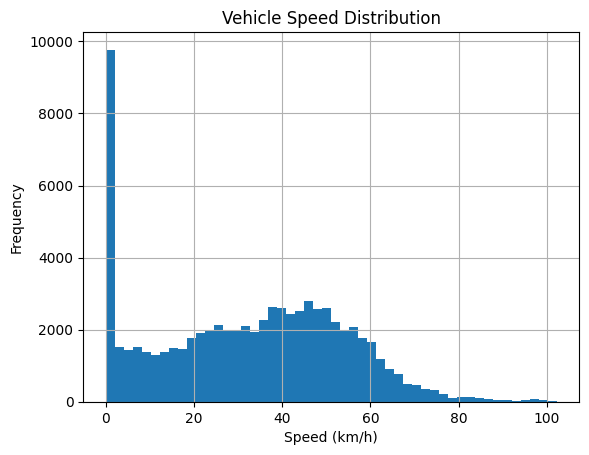

In [17]:
import matplotlib.pyplot as plt

ev_df["Vehicle Speed[km/h]"].hist(bins=50)

plt.title("Vehicle Speed Distribution")
plt.xlabel("Speed (km/h)")
plt.ylabel("Frequency")
plt.show()

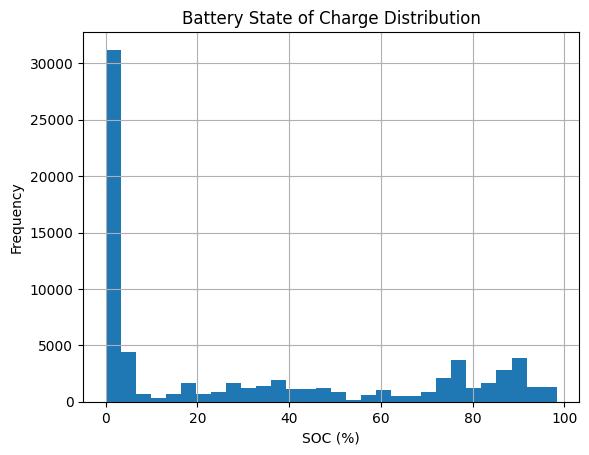

In [18]:
ev_df["HV Battery SOC[%]"].hist(bins=30)

plt.title("Battery State of Charge Distribution")
plt.xlabel("SOC (%)")
plt.ylabel("Frequency")
plt.show()

In [19]:
ev_df["Vehicle Speed[km/h]"].describe()

count    72751.000000
mean        32.355301
std         21.475435
min          0.000000
25%         14.090000
50%         34.000000
75%         49.000000
max        102.234375
Name: Vehicle Speed[km/h], dtype: float64

In [20]:
ev_df["HV Battery SOC[%]"].describe()

count    72751.000000
mean        31.353109
std         35.305300
min          0.000000
25%          0.000000
50%         10.000000
75%         71.764732
max         98.321526
Name: HV Battery SOC[%], dtype: float64

In [21]:
ev_df["OAT[DegC]"].describe()

count    72751.000000
mean        -5.656702
std          3.369587
min        -14.000000
25%         -7.750000
50%         -6.750000
75%         -4.000000
max          4.250000
Name: OAT[DegC], dtype: float64

In [22]:
import glob

files = glob.glob(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\**\*.csv",
    recursive=True
)

print("Number of CSV files:", len(files))

for f in files[:10]:
    print(f)

Number of CSV files: 54
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171101_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171108_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171115_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171122_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171129_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171206_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171213_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171220_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171227_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_180103_week.csv


In [23]:
import pandas as pd
import glob

files = glob.glob(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\**\*.csv",
    recursive=True
)

print("Files found:", len(files))

df_list = []

for i, file in enumerate(files):
    try:
        temp = pd.read_csv(file)
        df_list.append(temp)
        print(f"{i+1}/{len(files)} loaded")
    except Exception as e:
        print("Error:", file)
        print(e)

ved_all = pd.concat(df_list, ignore_index=True)

print("\nFinal shape:")
print(ved_all.shape)

Files found: 54
1/54 loaded
2/54 loaded
3/54 loaded
4/54 loaded
5/54 loaded
6/54 loaded
7/54 loaded
8/54 loaded
9/54 loaded
10/54 loaded
11/54 loaded
12/54 loaded
13/54 loaded
14/54 loaded
15/54 loaded
16/54 loaded
17/54 loaded
18/54 loaded
19/54 loaded
20/54 loaded
21/54 loaded
22/54 loaded
23/54 loaded
24/54 loaded
25/54 loaded
26/54 loaded
27/54 loaded
28/54 loaded
29/54 loaded
30/54 loaded
31/54 loaded
32/54 loaded
33/54 loaded
34/54 loaded
35/54 loaded
36/54 loaded
37/54 loaded
38/54 loaded
39/54 loaded
40/54 loaded
41/54 loaded
42/54 loaded
43/54 loaded
44/54 loaded
45/54 loaded
46/54 loaded
47/54 loaded
48/54 loaded
49/54 loaded
50/54 loaded
51/54 loaded
52/54 loaded
53/54 loaded
54/54 loaded

Final shape:
(22436808, 22)


In [24]:
ved_all.to_csv(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\VED_ALL.csv",
    index=False
)

In [25]:
print(ved_all.shape)

print("\nVehicles:")
print(ved_all["VehId"].nunique())

print("\nTrips:")
print(ved_all["Trip"].nunique())

(22436808, 22)

Vehicles:
384

Trips:
4153


In [26]:
ved_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 22436808 entries, 0 to 22436807
Data columns (total 22 columns):
 #   Column                          Dtype  
---  ------                          -----  
 0   DayNum                          float64
 1   VehId                           int64  
 2   Trip                            int64  
 3   Timestamp(ms)                   int64  
 4   Latitude[deg]                   float64
 5   Longitude[deg]                  float64
 6   Vehicle Speed[km/h]             float64
 7   MAF[g/sec]                      float64
 8   Engine RPM[RPM]                 float64
 9   Absolute Load[%]                float64
 10  OAT[DegC]                       float64
 11  Fuel Rate[L/hr]                 float64
 12  Air Conditioning Power[kW]      float64
 13  Air Conditioning Power[Watts]   float64
 14  Heater Power[Watts]             float64
 15  HV Battery Current[A]           float64
 16  HV Battery SOC[%]               float64
 17  HV Battery Voltage[V]           floa

In [27]:
ev_all = ved_all[ved_all["HV Battery SOC[%]"].notna()]

print("Rows:", ev_all.shape[0])
print("Vehicles:", ev_all["VehId"].nunique())
print("Trips:", ev_all["Trip"].nunique())

Rows: 3728652
Vehicles: 28
Trips: 2560


In [28]:
sample_df = ev_all.sample(
    n=200000,
    random_state=42
)

print(sample_df.shape)

(200000, 22)


In [29]:
ev_all.to_csv(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\VED_EV_ONLY.csv",
    index=False
)

In [30]:
sample_df = ev_all.sample(
    n=200000,
    random_state=42
)

In [31]:
sample_df["Battery_Power_W"] = (
    sample_df["HV Battery Voltage[V]"] *
    sample_df["HV Battery Current[A]"]
)

sample_df["Battery_Power_kW"] = (
    sample_df["Battery_Power_W"] / 1000
)

In [32]:
sample_df.to_csv(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\VED_EV_SAMPLE_200K.csv",
    index=False
)

In [33]:
sample_df = sample_df.sort_values(
    ["VehId", "Trip", "Timestamp(ms)"]
)

sample_df["Acceleration"] = (
    sample_df.groupby(
        ["VehId", "Trip"]
    )["Vehicle Speed[km/h]"]
    .diff()
    /
    (
        sample_df.groupby(
            ["VehId", "Trip"]
        )["Timestamp(ms)"]
        .diff()
        / 1000
    )
)

sample_df["Acceleration"].describe()

count    195874.000000
mean          0.015331
std           2.423423
min         -81.875000
25%          -0.622367
50%           0.000000
75%           0.669049
max         102.199993
Name: Acceleration, dtype: float64

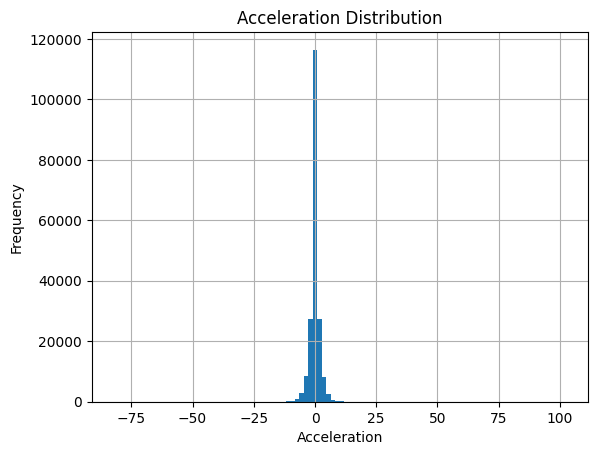

In [34]:
import matplotlib.pyplot as plt

sample_df["Acceleration"].hist(
    bins=100
)

plt.title(
    "Acceleration Distribution"
)

plt.xlabel(
    "Acceleration"
)

plt.ylabel(
    "Frequency"
)

plt.show()

In [35]:
sample_df["Acceleration"].describe()

count    195874.000000
mean          0.015331
std           2.423423
min         -81.875000
25%          -0.622367
50%           0.000000
75%           0.669049
max         102.199993
Name: Acceleration, dtype: float64

In [36]:
sample_df = sample_df[
    (sample_df["Acceleration"] >= -10) &
    (sample_df["Acceleration"] <= 10)
]

sample_df["Acceleration"].describe()

count    195066.000000
mean          0.002863
std           1.853587
min         -10.000000
25%          -0.618210
50%           0.000000
75%           0.665000
max          10.000000
Name: Acceleration, dtype: float64

In [37]:
sample_df["Positive_Acceleration"] = sample_df["Acceleration"].clip(lower=0)

sample_df["Positive_Acceleration"].describe()

count    195066.000000
mean          0.587139
std           1.153937
min           0.000000
25%           0.000000
50%           0.000000
75%           0.665000
max          10.000000
Name: Positive_Acceleration, dtype: float64

In [38]:
sample_df = sample_df[
    (sample_df["Acceleration"] >= -10) &
    (sample_df["Acceleration"] <= 10)
]

sample_df["Acceleration"].describe()

count    195066.000000
mean          0.002863
std           1.853587
min         -10.000000
25%          -0.618210
50%           0.000000
75%           0.665000
max          10.000000
Name: Acceleration, dtype: float64

## Stage 2 — Vehicle Type Audit and Final BEV Selection

In [39]:
import os
import glob

static_files = glob.glob(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\**\*",
    recursive=True
)

for f in static_files:
    if "static" in os.path.basename(f).lower():
        print(f)

C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_Static_Data_ICE&HEV.xlsx
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_Static_Data_PHEV&EV.xlsx


In [40]:
import pandas as pd

phev_ev_static_path = r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_Static_Data_PHEV&EV.xlsx"

static_ev = pd.read_excel(phev_ev_static_path)

print(static_ev.shape)
print(static_ev.columns.tolist())

static_ev.head()


(27, 7)
['VehId', 'EngineType', 'Vehicle Class', 'Engine Configuration & Displacement', 'Transmission', 'Drive Wheels', 'Generalized_Weight']


,VehId,EngineType,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight
0,9,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000
1,10,EV,Car,ELECTRIC,NO DATA,FWD,3500
2,11,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
3,371,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
4,379,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000


In [41]:
import pandas as pd

phev_ev_static_path = r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_Static_Data_PHEV&EV.xlsx"

static_ev = pd.read_excel(phev_ev_static_path)

print(static_ev.shape)
print(static_ev.columns.tolist())

static_ev.head()

(27, 7)
['VehId', 'EngineType', 'Vehicle Class', 'Engine Configuration & Displacement', 'Transmission', 'Drive Wheels', 'Generalized_Weight']


,VehId,EngineType,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight
0,9,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000
1,10,EV,Car,ELECTRIC,NO DATA,FWD,3500
2,11,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
3,371,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
4,379,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000


In [42]:
import pandas as pd
import openpyxl

print("Ready")

Ready


In [43]:
phev_ev_static_path = r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_Static_Data_PHEV&EV.xlsx"

static_ev = pd.read_excel(phev_ev_static_path)

print("Shape:", static_ev.shape)
print("\nColumns:")
print(static_ev.columns.tolist())

static_ev.head()

Shape: (27, 7)

Columns:
['VehId', 'EngineType', 'Vehicle Class', 'Engine Configuration & Displacement', 'Transmission', 'Drive Wheels', 'Generalized_Weight']


,VehId,EngineType,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight
0,9,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000
1,10,EV,Car,ELECTRIC,NO DATA,FWD,3500
2,11,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
3,371,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
4,379,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000


In [44]:
print(static_ev["EngineType"].value_counts())

bev_static = static_ev[
    static_ev["EngineType"].astype(str).str.strip().str.upper() == "EV"
]

print("\nTrue BEV vehicles:")
display(bev_static)

print("\nBEV VehIds:")
print(bev_static["VehId"].tolist())

EngineType
PHEV    24
EV       3
Name: count, dtype: int64

True BEV vehicles:


,VehId,EngineType,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight
1,10,EV,Car,ELECTRIC,NO DATA,FWD,3500
12,455,EV,Car,ELECTRIC,NO DATA,FWD,3500
18,541,EV,Car,ELECTRIC,NO DATA,FWD,3500



BEV VehIds:
[10, 455, 541]


In [45]:
bev_ids = [10, 455, 541]

ved_ev_path = r"C:\Projects\DS7010_Dissertation\01-Datasets\VED_EV_ONLY.csv"

ved_electrified = pd.read_csv(ved_ev_path)

ved_bev = ved_electrified[
    ved_electrified["VehId"].isin(bev_ids)
].copy()

print("BEV rows:", len(ved_bev))
print("BEV vehicles:", ved_bev["VehId"].nunique())
print("BEV trips:", ved_bev["Trip"].nunique())

print("\nRows by vehicle:")
print(ved_bev["VehId"].value_counts())

BEV rows: 476308
BEV vehicles: 3
BEV trips: 491

Rows by vehicle:
VehId
455    303824
10     167257
541      5227
Name: count, dtype: int64


### BEV Subset Validation and Temporal Audit

In [46]:
# Count unique vehicle-trip combinations
trip_count = (
    ved_bev[["VehId", "Trip"]]
    .drop_duplicates()
    .shape[0]
)

print("Unique vehicle-trip combinations:", trip_count)

print("\nTrips by vehicle:")
print(
    ved_bev.groupby("VehId")["Trip"].nunique()
)

print("\nMissing values in key variables:")
key_columns = [
    "VehId",
    "Trip",
    "Timestamp(ms)",
    "Vehicle Speed[km/h]",
    "HV Battery Current[A]",
    "HV Battery Voltage[V]",
    "HV Battery SOC[%]"
]

print(ved_bev[key_columns].isnull().sum())

Unique vehicle-trip combinations: 504

Trips by vehicle:
VehId
10     201
455    293
541     10
Name: Trip, dtype: int64

Missing values in key variables:
VehId                    0
Trip                     0
Timestamp(ms)            0
Vehicle Speed[km/h]      0
HV Battery Current[A]    0
HV Battery Voltage[V]    0
HV Battery SOC[%]        0
dtype: int64


In [47]:
bev_save_path = r"C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_ONLY.csv"

ved_bev.to_csv(
    bev_save_path,
    index=False
)

print("Saved:", bev_save_path)
print("Shape:", ved_bev.shape)

Saved: C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_ONLY.csv
Shape: (476308, 22)


### Temporal Audit of Complete BEV Trips

In [48]:
# Sort observations into correct time order
ved_bev = ved_bev.sort_values(
    ["VehId", "Trip", "Timestamp(ms)"]
).copy()

# Calculate time difference between consecutive observations
ved_bev["Time_Diff_ms"] = (
    ved_bev.groupby(["VehId", "Trip"])["Timestamp(ms)"]
    .diff()
)

print("Time interval statistics (milliseconds):")
print(ved_bev["Time_Diff_ms"].describe())

print("\nMost common time intervals:")
print(ved_bev["Time_Diff_ms"].value_counts().head(15))

Time interval statistics (milliseconds):
count    4.758040e+05
mean     6.037108e+02
std      2.821576e+03
min      1.000000e+02
25%      2.000000e+02
50%      4.000000e+02
75%      8.000000e+02
max      1.318200e+06
Name: Time_Diff_ms, dtype: float64

Most common time intervals:
Time_Diff_ms
100.0     95999
200.0     89756
800.0     52859
900.0     47497
300.0     39675
1000.0    36861
400.0     23597
500.0     19101
600.0     18482
700.0     17478
1100.0    14989
2100.0     5389
3100.0     2015
2000.0     1454
3200.0      693
Name: count, dtype: int64


### Investigation of Large Temporal Gaps

In [49]:
# Convert time difference to seconds
ved_bev["Time_Diff_s"] = ved_bev["Time_Diff_ms"] / 1000

print("Intervals greater than 5 seconds:")
print((ved_bev["Time_Diff_s"] > 5).sum())

print("\nIntervals greater than 30 seconds:")
print((ved_bev["Time_Diff_s"] > 30).sum())

print("\nIntervals greater than 5 minutes:")
print((ved_bev["Time_Diff_s"] > 300).sum())

print("\nLargest 20 gaps:")
display(
    ved_bev.loc[
        ved_bev["Time_Diff_s"] > 5,
        ["VehId", "Trip", "Timestamp(ms)", "Time_Diff_s"]
    ]
    .sort_values("Time_Diff_s", ascending=False)
    .head(20)
)

Intervals greater than 5 seconds:
2748

Intervals greater than 30 seconds:
4

Intervals greater than 5 minutes:
4

Largest 20 gaps:


,VehId,Trip,Timestamp(ms),Time_Diff_s
2125369,455,1682,2255100,1318.2
2333890,455,1795,1312900,916.0
1673182,455,1418,1180200,681.2
1802185,455,1509,1077600,650.5
3574652,455,2323,759000,30.0
426992,10,1674,553900,30.0
1736691,10,2338,362600,30.0
2150231,10,2533,1977000,29.9
2672213,10,2790,910900,29.9
1764508,10,2350,186400,29.9


In [50]:
gap_bins = [5, 10, 15, 20, 25, 30, 60, 300, float("inf")]

for lower, upper in zip(gap_bins[:-1], gap_bins[1:]):
    count = (
        (ved_bev["Time_Diff_s"] > lower) &
        (ved_bev["Time_Diff_s"] <= upper)
    ).sum()

    print(f"{lower}–{upper} seconds: {count}")

5–10 seconds: 2167
10–15 seconds: 407
15–20 seconds: 108
20–25 seconds: 36
25–30 seconds: 26
30–60 seconds: 0
60–300 seconds: 0
300–inf seconds: 4


### Segmentation of Interrupted Trips

In [51]:
# Flag the start of a new continuous segment
ved_bev["New_Segment"] = (
    ved_bev["Time_Diff_s"].isna() |
    (ved_bev["Time_Diff_s"] > 30)
).astype(int)

# Number segments separately within each vehicle-trip
ved_bev["Segment_Number"] = (
    ved_bev.groupby(["VehId", "Trip"])["New_Segment"]
    .cumsum()
)

# Create a unique segment identifier
ved_bev["Segment_ID"] = (
    ved_bev["VehId"].astype(str) + "_" +
    ved_bev["Trip"].astype(str) + "_" +
    ved_bev["Segment_Number"].astype(str)
)

print("Original vehicle-trip combinations:", 504)
print("Continuous segments:", ved_bev["Segment_ID"].nunique())

print("\nSegments created by vehicle:")
print(
    ved_bev.groupby("VehId")["Segment_ID"].nunique()
)

Original vehicle-trip combinations: 504
Continuous segments: 508

Segments created by vehicle:
VehId
10     201
455    297
541     10
Name: Segment_ID, dtype: int64


### Continuous Segment Quality Audit

In [52]:
segment_audit = (
    ved_bev.groupby("Segment_ID")
    .agg(
        VehId=("VehId", "first"),
        Trip=("Trip", "first"),
        Rows=("Timestamp(ms)", "size"),
        Start_ms=("Timestamp(ms)", "min"),
        End_ms=("Timestamp(ms)", "max")
    )
    .reset_index()
)

segment_audit["Duration_s"] = (
    segment_audit["End_ms"] - segment_audit["Start_ms"]
) / 1000

print("Segment rows:")
print(segment_audit["Rows"].describe())

print("\nSegment duration (seconds):")
print(segment_audit["Duration_s"].describe())

print("\nSegments shorter than 60 seconds:")
print((segment_audit["Duration_s"] < 60).sum())

print("\nSegments shorter than 5 minutes:")
print((segment_audit["Duration_s"] < 300).sum())

print("\n10 shortest segments:")
display(
    segment_audit.sort_values("Duration_s").head(10)
)

Segment rows:
count     508.000000
mean      937.614173
std       748.548065
min       103.000000
25%       399.500000
50%       753.500000
75%      1198.250000
max      4729.000000
Name: Rows, dtype: float64

Segment duration (seconds):
count     508.000000
mean      558.429331
std       516.428416
min        48.400000
25%       217.925000
50%       426.650000
75%       700.825000
max      4723.200000
Name: Duration_s, dtype: float64

Segments shorter than 60 seconds:
4

Segments shorter than 5 minutes:
176

10 shortest segments:


,Segment_ID,VehId,Trip,Rows,Start_ms,End_ms,Duration_s
357,455_1954_1,455,1954,105,0,48400,48.4
127,10_2610_1,10,2610,104,0,49600,49.6
6,10_1582_1,10,1582,122,0,53300,53.3
231,455_1198_1,455,1198,126,0,56700,56.7
439,455_601_1,455,601,131,0,60400,60.4
507,541_845_1,541,845,131,0,60900,60.9
414,455_2289_1,455,2289,103,0,64200,64.2
285,455_1531_1,455,1531,139,0,64800,64.8
132,10_2663_1,10,2663,138,0,65700,65.7
381,455_2105_1,455,2105,141,0,66700,66.7


### Provisional Segment Duration Filtering

In [53]:
# Keep segments lasting at least 60 seconds
valid_segment_ids = segment_audit.loc[
    segment_audit["Duration_s"] >= 60,
    "Segment_ID"
]

ved_bev_valid = ved_bev[
    ved_bev["Segment_ID"].isin(valid_segment_ids)
].copy()

print("Segments before filtering:", ved_bev["Segment_ID"].nunique())
print("Segments after filtering:", ved_bev_valid["Segment_ID"].nunique())
print("Rows retained:", len(ved_bev_valid))
print("Rows removed:", len(ved_bev) - len(ved_bev_valid))

Segments before filtering: 508
Segments after filtering: 504
Rows retained: 475851
Rows removed: 457


### Battery Current Sign Convention Audit

In [54]:
sign_audit = (
    ved_bev_valid
    .assign(
        Speed_Group=pd.cut(
            ved_bev_valid["Vehicle Speed[km/h]"],
            bins=[-0.1, 1, 30, 60, float("inf")],
            labels=["0–1", "1–30", "30–60", ">60"]
        )
    )
    .groupby("Speed_Group", observed=True)
    .agg(
        Rows=("HV Battery Current[A]", "size"),
        Mean_Current_A=("HV Battery Current[A]", "mean"),
        Median_Current_A=("HV Battery Current[A]", "median")
    )
)

display(sign_audit)

print("\nBattery current statistics:")
print(ved_bev_valid["HV Battery Current[A]"].describe())

,Rows,Mean_Current_A,Median_Current_A
Speed_Group,,,
0–1,54465,-3.454934,-2.5
1–30,117632,-8.148493,-4.0
30–60,206561,-17.369286,-18.0
>60,97193,-26.449569,-27.5



Battery current statistics:
count    475851.000000
mean        -15.351920
std          29.980281
min        -290.500000
25%         -34.000000
50%         -11.500000
75%           1.500000
max         118.500000
Name: HV Battery Current[A], dtype: float64


### Calculation of Battery Energy and Distance

In [55]:
# Discharge power is made positive for easier interpretation
ved_bev_valid["Battery_Power_kW"] = (
    -ved_bev_valid["HV Battery Voltage[V]"] *
    ved_bev_valid["HV Battery Current[A]"]
) / 1000

# Prevent integration across the first row of each segment
ved_bev_valid["Delta_t_s"] = (
    ved_bev_valid.groupby("Segment_ID")["Timestamp(ms)"]
    .diff() / 1000
)

# Energy contribution of each observation interval
ved_bev_valid["Energy_kWh_step"] = (
    ved_bev_valid["Battery_Power_kW"] *
    ved_bev_valid["Delta_t_s"] / 3600
)

# Distance contribution using speed and actual time interval
ved_bev_valid["Distance_km_step"] = (
    ved_bev_valid["Vehicle Speed[km/h]"] *
    ved_bev_valid["Delta_t_s"] / 3600
)

segment_energy_distance = (
    ved_bev_valid.groupby("Segment_ID")
    .agg(
        VehId=("VehId", "first"),
        Trip=("Trip", "first"),
        Rows=("Timestamp(ms)", "size"),
        Energy_kWh=("Energy_kWh_step", "sum"),
        Distance_km=("Distance_km_step", "sum")
    )
    .reset_index()
)

print(segment_energy_distance[["Energy_kWh", "Distance_km"]].describe())

       Energy_kWh  Distance_km
count  504.000000   504.000000
mean     0.731291     4.640891
std      0.617109     3.551315
min     -0.007619     0.084790
25%      0.284230     2.043076
50%      0.568805     3.653794
75%      0.985441     5.964973
max      3.714446    21.478755


### Energy and Distance Quality Audit

In [56]:
print("Segments with Energy <= 0 kWh:")
print((segment_energy_distance["Energy_kWh"] <= 0).sum())

print("\nSegments with Distance < 0.5 km:")
print((segment_energy_distance["Distance_km"] < 0.5).sum())

print("\nSegments with Distance < 1.0 km:")
print((segment_energy_distance["Distance_km"] < 1.0).sum())

print("\nLowest-energy segments:")
display(
    segment_energy_distance
    .sort_values("Energy_kWh")
    .head(10)
)

print("\nShortest-distance segments:")
display(
    segment_energy_distance
    .sort_values("Distance_km")
    .head(10)
)

Segments with Energy <= 0 kWh:
1

Segments with Distance < 0.5 km:
15

Segments with Distance < 1.0 km:
40

Lowest-energy segments:


,Segment_ID,VehId,Trip,Rows,Energy_kWh,Distance_km
428,455_554_1,455,554,160,-0.007619,1.352427
395,455_2202_1,455,2202,128,0.014739,0.535775
429,455_565_1,455,565,111,0.029050,1.081723
398,455_2214_1,455,2214,155,0.035494,0.831816
220,455_1143_1,455,1143,176,0.036151,1.223149
345,455_1879_1,455,1879,191,0.038774,0.885558
282,455_1531_1,455,1531,139,0.046587,0.390350
410,455_2289_1,455,2289,103,0.049910,0.492454
162,10_2956_1,10,2956,130,0.050031,0.364433
417,455_2316_1,455,2316,143,0.053303,0.550527



Shortest-distance segments:


,Segment_ID,VehId,Trip,Rows,Energy_kWh,Distance_km
145,10_2820_1,10,2820,107,0.089652,0.084790
45,10_1878_1,10,1878,147,0.201143,0.113046
225,455_1175_1,455,1175,498,0.203846,0.222431
484,455_936_1,455,936,200,0.131916,0.327311
162,10_2956_1,10,2956,130,0.050031,0.364433
188,10_3149_1,10,3149,163,0.111954,0.370288
195,10_3229_1,10,3229,372,0.209971,0.373372
282,455_1531_1,455,1531,139,0.046587,0.390350
363,455_1998_1,455,1998,111,0.082636,0.414340
143,10_2806_1,10,2806,161,0.162733,0.423753


In [57]:
print("Energy <= 0:", (segment_energy_distance["Energy_kWh"] <= 0).sum())
print("Distance < 0.5 km:", (segment_energy_distance["Distance_km"] < 0.5).sum())
print("Distance < 1.0 km:", (segment_energy_distance["Distance_km"] < 1.0).sum())

Energy <= 0: 1
Distance < 0.5 km: 15
Distance < 1.0 km: 40


### Validation of Energy Integration Method

In [58]:
import numpy as np

# Previous battery power within each continuous segment
ved_bev_valid["Previous_Power_kW"] = (
    ved_bev_valid.groupby("Segment_ID")["Battery_Power_kW"].shift(1)
)

# Trapezoidal integration of battery power
ved_bev_valid["Energy_kWh_trap_step"] = (
    (
        ved_bev_valid["Previous_Power_kW"] +
        ved_bev_valid["Battery_Power_kW"]
    ) / 2
    * ved_bev_valid["Delta_t_s"]
    / 3600
)

# Previous speed within each segment
ved_bev_valid["Previous_Speed_kmh"] = (
    ved_bev_valid.groupby("Segment_ID")["Vehicle Speed[km/h]"].shift(1)
)

# Trapezoidal integration of distance
ved_bev_valid["Distance_km_trap_step"] = (
    (
        ved_bev_valid["Previous_Speed_kmh"] +
        ved_bev_valid["Vehicle Speed[km/h]"]
    ) / 2
    * ved_bev_valid["Delta_t_s"]
    / 3600
)

segment_trap = (
    ved_bev_valid.groupby("Segment_ID")
    .agg(
        VehId=("VehId", "first"),
        Trip=("Trip", "first"),
        Energy_kWh_trap=("Energy_kWh_trap_step", "sum"),
        Distance_km_trap=("Distance_km_trap_step", "sum")
    )
    .reset_index()
)

comparison = segment_energy_distance.merge(
    segment_trap,
    on=["Segment_ID", "VehId", "Trip"]
)

comparison["Energy_Difference_pct"] = (
    100 *
    (comparison["Energy_kWh_trap"] - comparison["Energy_kWh"]) /
    comparison["Energy_kWh"].abs()
)

comparison["Distance_Difference_pct"] = (
    100 *
    (comparison["Distance_km_trap"] - comparison["Distance_km"]) /
    comparison["Distance_km"]
)

print("Trapezoidal results:")
print(
    comparison[
        ["Energy_kWh_trap", "Distance_km_trap"]
    ].describe()
)

print("\nMedian absolute percentage difference:")
print(
    comparison[
        ["Energy_Difference_pct", "Distance_Difference_pct"]
    ].abs().median()
)


Trapezoidal results:
       Energy_kWh_trap  Distance_km_trap
count       504.000000        504.000000
mean          0.731191          4.642549
std           0.616738          3.551927
min          -0.005072          0.083568
25%           0.283880          2.046007
50%           0.569162          3.653107
75%           0.985100          5.964193
max           3.713543         21.477135

Median absolute percentage difference:
Energy_Difference_pct      0.275002
Distance_Difference_pct    0.067366
dtype: float64


### Investigation of Negative Net-Energy Segment

In [59]:
negative_segments = comparison[
    comparison["Energy_kWh_trap"] <= 0
]

display(negative_segments)

negative_ids = negative_segments["Segment_ID"].tolist()

negative_data = ved_bev_valid[
    ved_bev_valid["Segment_ID"].isin(negative_ids)
]

print("\nNegative segment battery statistics:")
print(
    negative_data[
        [
            "Vehicle Speed[km/h]",
            "HV Battery Current[A]",
            "HV Battery Voltage[V]",
            "HV Battery SOC[%]",
            "Battery_Power_kW"
        ]
    ].describe()
)

print("\nSOC start and end:")
display(
    negative_data.groupby("Segment_ID").agg(
        Start_SOC=("HV Battery SOC[%]", "first"),
        End_SOC=("HV Battery SOC[%]", "last"),
        Min_SOC=("HV Battery SOC[%]", "min"),
        Max_SOC=("HV Battery SOC[%]", "max")
    )
)

,Segment_ID,VehId,Trip,Rows,Energy_kWh,Distance_km,Energy_kWh_trap,Distance_km_trap,Energy_Difference_pct,Distance_Difference_pct
428,455_554_1,455,554,160,-0.007619,1.352427,-0.005072,1.358971,33.431386,0.483924



Negative segment battery statistics:
       Vehicle Speed[km/h]  HV Battery Current[A]  HV Battery Voltage[V]  \
count           160.000000             160.000000             160.000000   
mean             46.201749              -0.006250             372.068750   
std              20.271198              32.652063               3.518812   
min               0.000000             -67.000000             365.000000   
25%              39.877499             -25.000000             370.000000   
50%              53.174997              -1.000000             372.000000   
75%              60.937499              28.000000             374.875000   
max              65.540001              64.500000             379.500000   

       HV Battery SOC[%]  Battery_Power_kW  
count         160.000000        160.000000  
mean           48.342989         -0.073836  
std             0.317358         12.116455  
min            47.682930        -24.284250  
25%            48.414635        -10.528000  
50%    

,Start_SOC,End_SOC,Min_SOC,Max_SOC
Segment_ID,,,,
455_554_1,48.902443,47.92683,47.68293,48.902443


### Final Target Eligibility Criteria

In [60]:
# Apply provisional target eligibility criteria
target_data = comparison[
    (comparison["Distance_km_trap"] >= 0.5) &
    (comparison["Energy_kWh_trap"] > 0)
].copy()

# Create normalised energy-consumption target
target_data["Energy_Consumption_kWh_100km"] = (
    target_data["Energy_kWh_trap"] /
    target_data["Distance_km_trap"]
) * 100

print("Segments before target filtering:", len(comparison))
print("Segments after target filtering:", len(target_data))
print("Segments removed:", len(comparison) - len(target_data))

print("\nTarget distribution:")
print(
    target_data["Energy_Consumption_kWh_100km"].describe()
)


Segments before target filtering: 504
Segments after target filtering: 488
Segments removed: 16

Target distribution:
count    488.000000
mean      16.058173
std        7.479036
min        2.846425
25%       11.655858
50%       14.579965
75%       18.570516
max       79.163078
Name: Energy_Consumption_kWh_100km, dtype: float64


### Target Variable Distribution and Extreme-Value Audit

In [61]:
print("Highest 15 target values:")

display(
    target_data[
        [
            "Segment_ID",
            "VehId",
            "Trip",
            "Energy_kWh_trap",
            "Distance_km_trap",
            "Energy_Consumption_kWh_100km"
        ]
    ]
    .sort_values(
        "Energy_Consumption_kWh_100km",
        ascending=False
    )
    .head(15)
)

print("\nSegments above 30 kWh/100 km:")
print(
    (
        target_data["Energy_Consumption_kWh_100km"] > 30
    ).sum()
)

print("\nSegments above 40 kWh/100 km:")
print(
    (
        target_data["Energy_Consumption_kWh_100km"] > 40
    ).sum()
)

print("\nTarget distribution by vehicle:")
display(
    target_data.groupby("VehId")[
        "Energy_Consumption_kWh_100km"
    ].describe()
)

Highest 15 target values:


,Segment_ID,VehId,Trip,Energy_kWh_trap,Distance_km_trap,Energy_Consumption_kWh_100km
29,10_1781_1,10,1781,0.972235,1.228142,79.163078
30,10_1793_1,10,1793,2.820246,4.331530,65.109691
23,10_1756_1,10,1756,0.661134,1.217375,54.308139
15,10_1674_1,10,1674,2.599497,5.902575,44.040044
49,10_1928_1,10,1928,2.178695,5.242102,41.561471
22,10_1737_1,10,1737,1.954659,4.952381,39.469066
463,455_775_1,455,775,0.483352,1.245993,38.792530
48,10_1920_1,10,1920,2.011243,5.390035,37.314101
477,455_887_1,455,887,2.220304,5.959142,37.258791
2,10_1567_1,10,1567,0.509101,1.415280,35.971756



Segments above 30 kWh/100 km:
19

Segments above 40 kWh/100 km:
5

Target distribution by vehicle:


,count,mean,std,min,25%,50%,75%,max
VehId,,,,,,,,
10,189.0,19.575725,8.924528,4.837667,14.620073,17.362748,22.521029,79.163078
455,289.0,13.793216,5.367640,2.846425,10.363675,12.913124,16.292976,38.792530
541,10.0,15.033686,3.913132,10.346230,12.159372,15.016565,17.041619,23.367496


### Investigation of High-Consumption Segments

In [62]:
high_ids = target_data.loc[
    target_data["Energy_Consumption_kWh_100km"] > 40,
    "Segment_ID"
]

high_data = ved_bev_valid[
    ved_bev_valid["Segment_ID"].isin(high_ids)
]

high_audit = (
    high_data.groupby("Segment_ID")
    .agg(
        VehId=("VehId", "first"),
        Trip=("Trip", "first"),
        Mean_Speed_kmh=("Vehicle Speed[km/h]", "mean"),
        Max_Speed_kmh=("Vehicle Speed[km/h]", "max"),
        Mean_Temp_C=("OAT[DegC]", "mean"),
        Start_SOC=("HV Battery SOC[%]", "first"),
        End_SOC=("HV Battery SOC[%]", "last"),
        Mean_AC_kW=("Air Conditioning Power[kW]", "mean"),
        Mean_Heater_W=("Heater Power[Watts]", "mean")
    )
    .reset_index()
)

high_audit = high_audit.merge(
    target_data[
        [
            "Segment_ID",
            "Energy_kWh_trap",
            "Distance_km_trap",
            "Energy_Consumption_kWh_100km"
        ]
    ],
    on="Segment_ID"
)

display(
    high_audit.sort_values(
        "Energy_Consumption_kWh_100km",
        ascending=False
    )
)

,Segment_ID,VehId,Trip,Mean_Speed_kmh,Max_Speed_kmh,Mean_Temp_C,Start_SOC,End_SOC,Mean_AC_kW,Mean_Heater_W,Energy_kWh_trap,Distance_km_trap,Energy_Consumption_kWh_100km
2,10_1781_1,10,1781,11.625928,29.969999,-7.500000,98.658539,92.073174,NaN,3911.581569,0.972235,1.228142,79.163078
3,10_1793_1,10,1793,12.185868,71.049995,-6.510276,40.121956,22.560976,NaN,2349.840539,2.820246,4.331530,65.109691
1,10_1756_1,10,1756,16.471678,50.360001,-4.027966,99.024399,95.243904,NaN,1492.796610,0.661134,1.217375,54.308139
0,10_1674_1,10,1674,36.466653,67.299995,1.240812,100.000000,100.000000,NaN,554.642166,2.599497,5.902575,44.040044
4,10_1928_1,10,1928,23.384991,58.989998,-6.791185,99.634155,87.439034,NaN,2507.438017,2.178695,5.242102,41.561471


### Validation of Integrated Energy Against SOC Change

In [63]:
# Calculate SOC start, end, and change for every eligible segment
soc_validation = (
    ved_bev_valid.groupby("Segment_ID")
    .agg(
        Start_SOC=("HV Battery SOC[%]", "first"),
        End_SOC=("HV Battery SOC[%]", "last")
    )
    .reset_index()
)

soc_validation["SOC_Drop_pct"] = (
    soc_validation["Start_SOC"] -
    soc_validation["End_SOC"]
)

# Add SOC information to the 488 eligible target segments
target_validated = target_data.merge(
    soc_validation,
    on="Segment_ID",
    how="left"
)

print("SOC drop statistics:")
print(target_validated["SOC_Drop_pct"].describe())

print("\nCorrelation between integrated energy and SOC drop:")
print(
    target_validated[
        ["Energy_kWh_trap", "SOC_Drop_pct"]
    ].corr()
)

print("\nSegments where SOC increased:")
print((target_validated["SOC_Drop_pct"] < 0).sum())

print("\nLargest SOC drops:")
display(
    target_validated[
        [
            "Segment_ID",
            "VehId",
            "Energy_kWh_trap",
            "Distance_km_trap",
            "SOC_Drop_pct",
            "Energy_Consumption_kWh_100km"
        ]
    ]
    .sort_values("SOC_Drop_pct", ascending=False)
    .head(10)
)

SOC drop statistics:
count    488.000000
mean       4.329268
std        3.920420
min        0.000000
25%        1.585365
50%        3.170729
75%        6.219513
max       22.804878
Name: SOC_Drop_pct, dtype: float64

Correlation between integrated energy and SOC drop:
                 Energy_kWh_trap  SOC_Drop_pct
Energy_kWh_trap         1.000000      0.873998
SOC_Drop_pct            0.873998      1.000000

Segments where SOC increased:
0

Largest SOC drops:


,Segment_ID,VehId,Energy_kWh_trap,Distance_km_trap,SOC_Drop_pct,Energy_Consumption_kWh_100km
447,455_772_1,455,3.527140,14.494040,22.804878,24.335108
122,10_2612_1,10,3.385429,13.586825,20.731705,24.917001
217,455_1197_1,455,2.951609,14.939911,20.365852,19.756533
193,455_1034_1,455,3.469912,14.294955,19.756088,24.273684
189,455_1001_1,455,3.713543,16.757958,19.146332,22.159878
30,10_1793_1,10,2.820246,4.331530,17.560980,65.109691
306,455_1720_1,455,2.865498,21.477135,17.317078,13.342085
425,455_630_1,455,2.400366,12.524567,16.341461,19.165262
462,455_887_1,455,2.220304,5.959142,16.097561,37.258791
222,455_1243_1,455,1.984230,11.596571,15.609756,17.110486


## Stage 3 — Behaviour-First Feature Engineering

### Acceleration and Deceleration

In [64]:
# Convert speed from km/h to m/s
ved_bev_valid["Speed_mps"] = (
    ved_bev_valid["Vehicle Speed[km/h]"] / 3.6
)

# Calculate acceleration within each continuous segment
ved_bev_valid["Acceleration_mps2"] = (
    ved_bev_valid.groupby("Segment_ID")["Speed_mps"].diff()
    / ved_bev_valid["Delta_t_s"]
)

print("Raw acceleration statistics:")
print(ved_bev_valid["Acceleration_mps2"].describe())

print("\nAcceleration values below -10 m/s²:")
print((ved_bev_valid["Acceleration_mps2"] < -10).sum())

print("\nAcceleration values above +10 m/s²:")
print((ved_bev_valid["Acceleration_mps2"] > 10).sum())

Raw acceleration statistics:
count    475347.000000
mean          0.022124
std           1.611177
min         -53.972218
25%           0.000000
50%           0.000000
75%           0.000000
max          47.972216
Name: Acceleration_mps2, dtype: float64

Acceleration values below -10 m/s²:
1083

Acceleration values above +10 m/s²:
1676


### Acceleration Quality Audit

In [65]:
print("Acceleration percentiles:")

print(
    ved_bev_valid["Acceleration_mps2"]
    .quantile([
        0.001,
        0.005,
        0.01,
        0.025,
        0.05,
        0.95,
        0.975,
        0.99,
        0.995,
        0.999
    ])
)

print("\nAbsolute acceleration thresholds:")

for threshold in [3, 5, 7, 10, 15, 20]:
    count = (
        ved_bev_valid["Acceleration_mps2"].abs() > threshold
    ).sum()

    percentage = (
        count /
        ved_bev_valid["Acceleration_mps2"].notna().sum()
        * 100
    )

    print(
        f"|a| > {threshold} m/s²: "
        f"{count} rows ({percentage:.3f}%)"
    )

Acceleration percentiles:
0.001   -15.194443
0.005    -6.569444
0.010    -4.138890
0.025    -2.277777
0.050    -1.348765
0.950     1.402781
0.975     2.361111
0.990     4.805554
0.995     8.027777
0.999    15.184830
Name: Acceleration_mps2, dtype: float64

Absolute acceleration thresholds:
|a| > 3 m/s²: 16448 rows (3.460%)
|a| > 5 m/s²: 8133 rows (1.711%)
|a| > 7 m/s²: 5011 rows (1.054%)
|a| > 10 m/s²: 2759 rows (0.580%)
|a| > 15 m/s²: 999 rows (0.210%)
|a| > 20 m/s²: 324 rows (0.068%)


In [66]:
extreme_accel_audit = (
    ved_bev_valid[
        ved_bev_valid["Acceleration_mps2"].abs() > 10
    ]
    .groupby("Delta_t_s")
    .size()
    .sort_values(ascending=False)
)

print("Most common time intervals for |acceleration| > 10 m/s²:")
print(extreme_accel_audit.head(15))

print("\nDelta-t statistics for extreme acceleration:")
print(
    ved_bev_valid.loc[
        ved_bev_valid["Acceleration_mps2"].abs() > 10,
        "Delta_t_s"
    ].describe()
)

print("\nDelta-t statistics for all acceleration observations:")
print(
    ved_bev_valid.loc[
        ved_bev_valid["Acceleration_mps2"].notna(),
        "Delta_t_s"
    ].describe()
)

Most common time intervals for |acceleration| > 10 m/s²:
Delta_t_s
0.1    2409
0.2     313
0.3      33
0.4       2
0.5       1
0.7       1
dtype: int64

Delta-t statistics for extreme acceleration:
count    2759.000000
mean        0.114317
std         0.040771
min         0.100000
25%         0.100000
50%         0.100000
75%         0.100000
max         0.700000
Name: Delta_t_s, dtype: float64

Delta-t statistics for all acceleration observations:
count    475347.000000
mean          0.596352
std           0.831101
min           0.100000
25%           0.200000
50%           0.400000
75%           0.800000
max          30.000000
Name: Delta_t_s, dtype: float64


### Cleaning of Acceleration-Derived Features

In [67]:
# Keep the original raw acceleration for auditability
ved_bev_valid["Acceleration_raw_mps2"] = (
    ved_bev_valid["Acceleration_mps2"]
)

# Mark implausible acceleration values as missing
ved_bev_valid["Acceleration_clean_mps2"] = (
    ved_bev_valid["Acceleration_raw_mps2"]
    .where(
        ved_bev_valid["Acceleration_raw_mps2"].between(-10, 10)
    )
)

print("Valid raw acceleration values:")
print(
    ved_bev_valid["Acceleration_raw_mps2"]
    .notna()
    .sum()
)

print("\nValid cleaned acceleration values:")
print(
    ved_bev_valid["Acceleration_clean_mps2"]
    .notna()
    .sum()
)

print("\nValues marked missing:")
print(
    ved_bev_valid["Acceleration_raw_mps2"].notna().sum()
    -
    ved_bev_valid["Acceleration_clean_mps2"].notna().sum()
)

print("\nClean acceleration statistics:")
print(
    ved_bev_valid["Acceleration_clean_mps2"]
    .describe()
)

Valid raw acceleration values:
475347

Valid cleaned acceleration values:
472588

Values marked missing:
2759

Clean acceleration statistics:
count    472588.000000
mean          0.008534
std           1.096372
min         -10.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          10.000000
Name: Acceleration_clean_mps2, dtype: float64


### Positive Acceleration and Relative Positive Acceleration

In [68]:
# Keep only positive acceleration values
ved_bev_valid["Positive_Acceleration_mps2"] = (
    ved_bev_valid["Acceleration_clean_mps2"]
    .clip(lower=0)
)

# RPA numerator contribution:
# speed × positive acceleration × time
ved_bev_valid["RPA_Numerator_step"] = (
    ved_bev_valid["Speed_mps"] *
    ved_bev_valid["Positive_Acceleration_mps2"] *
    ved_bev_valid["Delta_t_s"]
)

print("Positive acceleration statistics:")
print(
    ved_bev_valid["Positive_Acceleration_mps2"].describe()
)

print("\nRPA numerator step statistics:")
print(
    ved_bev_valid["RPA_Numerator_step"].describe()
)

Positive acceleration statistics:
count    472588.000000
mean          0.212352
std           0.757800
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          10.000000
Name: Positive_Acceleration_mps2, dtype: float64

RPA numerator step statistics:
count    472588.000000
mean          1.083289
std           3.047091
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          83.896940
Name: RPA_Numerator_step, dtype: float64


### Segment-Level Relative Positive Acceleration

In [69]:
# Aggregate the RPA numerator for each continuous segment
segment_rpa = (
    ved_bev_valid.groupby("Segment_ID")
    .agg(
        RPA_Numerator=("RPA_Numerator_step", "sum")
    )
    .reset_index()
)

# Add the validated segment distance
segment_rpa = segment_rpa.merge(
    target_validated[
        ["Segment_ID", "Distance_km_trap"]
    ],
    on="Segment_ID",
    how="inner"
)

# Convert distance from km to metres
segment_rpa["Distance_m"] = (
    segment_rpa["Distance_km_trap"] * 1000
)

# Calculate segment-level RPA
segment_rpa["RPA_mps2"] = (
    segment_rpa["RPA_Numerator"] /
    segment_rpa["Distance_m"]
)

print("Segments with RPA:", len(segment_rpa))

print("\nRPA statistics:")
print(segment_rpa["RPA_mps2"].describe())

print("\nHighest 10 RPA segments:")
display(
    segment_rpa
    .sort_values("RPA_mps2", ascending=False)
    .head(10)
)

Segments with RPA: 488

RPA statistics:
count    488.000000
mean       0.228152
std        0.059875
min        0.052718
25%        0.186299
50%        0.223377
75%        0.265934
max        0.526866
Name: RPA_mps2, dtype: float64

Highest 10 RPA segments:


,Segment_ID,RPA_Numerator,Distance_km_trap,Distance_m,RPA_mps2
49,10_1936_1,680.791121,1.292152,1292.151917,0.526866
487,541_845_1,457.416371,0.959092,959.091502,0.476927
4,10_1572_1,925.412087,2.068540,2068.539673,0.447375
441,455_735_1,376.779611,0.866726,866.725954,0.434716
179,10_3145_1,400.379813,0.945875,945.874977,0.423290
184,10_3215_1,546.954708,1.303818,1303.817884,0.419502
293,455_1634_1,581.323154,1.452355,1452.355109,0.400262
403,455_2316_1,206.355952,0.551877,551.876791,0.373917
1,10_1561_1,867.947722,2.378166,2378.166337,0.364965
154,10_2949_1,3101.240847,8.530335,8530.335487,0.363554


### Acceleration Feature Coverage Audit


In [70]:
acceleration_coverage = (
    ved_bev_valid.groupby("Segment_ID")
    .agg(
        Total_Rows=("Acceleration_raw_mps2", "size"),
        Raw_Acceleration_Values=("Acceleration_raw_mps2", "count"),
        Valid_Acceleration_Values=("Acceleration_clean_mps2", "count")
    )
    .reset_index()
)

acceleration_coverage["Valid_Acceleration_Coverage_pct"] = (
    acceleration_coverage["Valid_Acceleration_Values"] /
    acceleration_coverage["Raw_Acceleration_Values"] * 100
)

# Keep only the 488 target-eligible segments
acceleration_coverage = acceleration_coverage[
    acceleration_coverage["Segment_ID"].isin(
        target_validated["Segment_ID"]
    )
]

print("Acceleration coverage statistics:")
print(
    acceleration_coverage[
        "Valid_Acceleration_Coverage_pct"
    ].describe()
)

print("\nSegments below 95% valid acceleration coverage:")
print(
    (
        acceleration_coverage[
            "Valid_Acceleration_Coverage_pct"
        ] < 95
    ).sum()
)

print("\nLowest 10 coverage segments:")
display(
    acceleration_coverage
    .sort_values("Valid_Acceleration_Coverage_pct")
    .head(10)
)

Acceleration coverage statistics:
count    488.000000
mean      99.377659
std        0.400178
min       97.734628
25%       99.157685
50%       99.460601
75%       99.633361
max      100.000000
Name: Valid_Acceleration_Coverage_pct, dtype: float64

Segments below 95% valid acceleration coverage:
0

Lowest 10 coverage segments:


,Segment_ID,Total_Rows,Raw_Acceleration_Values,Valid_Acceleration_Values,Valid_Acceleration_Coverage_pct
79,10_2180_1,310,309,302,97.734628
417,455_2316_1,143,142,139,97.887324
222,455_1154_1,209,208,204,98.076923
158,10_2919_1,1043,1042,1023,98.176583
294,455_1591_1,166,165,162,98.181818
11,10_1625_1,719,718,705,98.189415
140,10_2780_1,454,453,445,98.233996
416,455_2314_1,405,404,397,98.267327
319,455_1722_1,353,352,346,98.295455
269,455_1469_1,472,471,463,98.301486


### Segment-Level Feature Table Construction

In [71]:
segment_features = (
    ved_bev_valid.groupby("Segment_ID")
    .agg(
        VehId=("VehId", "first"),
        Trip=("Trip", "first"),
        Rows=("Timestamp(ms)", "size"),
        Duration_s=("Delta_t_s", "sum"),

        Mean_Speed_kmh=("Vehicle Speed[km/h]", "mean"),
        Max_Speed_kmh=("Vehicle Speed[km/h]", "max"),
        Std_Speed_kmh=("Vehicle Speed[km/h]", "std"),

        Mean_Acceleration_mps2=("Acceleration_clean_mps2", "mean"),
        Mean_Positive_Acceleration_mps2=("Positive_Acceleration_mps2", "mean"),
        Max_Acceleration_mps2=("Acceleration_clean_mps2", "max"),
        Min_Acceleration_mps2=("Acceleration_clean_mps2", "min"),

        Mean_Temp_C=("OAT[DegC]", "mean"),
        Start_SOC=("HV Battery SOC[%]", "first"),
        End_SOC=("HV Battery SOC[%]", "last"),

        Mean_Heater_W=("Heater Power[Watts]", "mean"),
        Mean_AC_kW=("Air Conditioning Power[kW]", "mean")
    )
    .reset_index()
)

segment_features["SOC_Drop_pct"] = (
    segment_features["Start_SOC"] - segment_features["End_SOC"]
)

segment_features["Idling_Proportion"] = (
    ved_bev_valid
    .assign(Is_Idling=ved_bev_valid["Vehicle Speed[km/h]"] < 2)
    .groupby("Segment_ID")["Is_Idling"]
    .mean()
    .values
)

segment_features = segment_features.merge(
    segment_rpa[["Segment_ID", "RPA_mps2"]],
    on="Segment_ID",
    how="left"
)

ved_model_table = target_validated.merge(
    segment_features,
    on=["Segment_ID", "VehId", "Trip"],
    how="left"
)

print("Model table shape:", ved_model_table.shape)
print("\nColumns:")
print(ved_model_table.columns.tolist())

display(ved_model_table.head())

Model table shape: (488, 31)

Columns:
['Segment_ID', 'VehId', 'Trip', 'Rows_x', 'Energy_kWh', 'Distance_km', 'Energy_kWh_trap', 'Distance_km_trap', 'Energy_Difference_pct', 'Distance_Difference_pct', 'Energy_Consumption_kWh_100km', 'Start_SOC_x', 'End_SOC_x', 'SOC_Drop_pct_x', 'Rows_y', 'Duration_s', 'Mean_Speed_kmh', 'Max_Speed_kmh', 'Std_Speed_kmh', 'Mean_Acceleration_mps2', 'Mean_Positive_Acceleration_mps2', 'Max_Acceleration_mps2', 'Min_Acceleration_mps2', 'Mean_Temp_C', 'Start_SOC_y', 'End_SOC_y', 'Mean_Heater_W', 'Mean_AC_kW', 'SOC_Drop_pct_y', 'Idling_Proportion', 'RPA_mps2']


,Segment_ID,VehId,Trip,Rows_x,Energy_kWh,Distance_km,Energy_kWh_trap,Distance_km_trap,Energy_Difference_pct,Distance_Difference_pct,...,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Temp_C,Start_SOC_y,End_SOC_y,Mean_Heater_W,Mean_AC_kW,SOC_Drop_pct_y,Idling_Proportion,RPA_mps2
0,10_1558_1,10,1558,129,0.121510,0.891228,0.123019,0.894000,1.241887,0.311025,...,9.333333,-5.874999,5.000000,96.341469,95.853661,2096.899225,NaN,0.487808,0.062016,0.223394
1,10_1561_1,10,1561,534,0.681466,2.379850,0.682476,2.378166,0.148255,-0.070733,...,7.638889,-7.986111,4.753745,71.707321,66.463417,1293.071161,NaN,5.243904,0.099251,0.364965
2,10_1567_1,10,1567,367,0.512246,1.423569,0.509101,1.415280,-0.614029,-0.582252,...,8.611111,-9.638889,9.322888,71.097565,67.560982,1628.065395,NaN,3.536583,0.160763,0.298862
3,10_1568_1,10,1568,284,0.324378,1.439839,0.326542,1.430647,0.666896,-0.638439,...,6.425925,-7.152777,9.605634,64.634148,63.658539,693.661972,NaN,0.975609,0.151408,0.235044
4,10_1572_1,10,1572,448,0.571837,2.080000,0.570614,2.068540,-0.213999,-0.550962,...,9.333335,-6.750000,14.164062,48.780487,46.585369,275.669643,NaN,2.195118,0.111607,0.447375


### Modelling Table Cleanup and Missing-Value Audit

In [72]:
# Remove duplicated columns created during the merge
ved_model_table = ved_model_table.drop(
    columns=[
        "Rows_y",
        "Start_SOC_y",
        "End_SOC_y",
        "SOC_Drop_pct_y"
    ]
)

# Rename retained versions clearly
ved_model_table = ved_model_table.rename(
    columns={
        "Rows_x": "Rows",
        "Start_SOC_x": "Start_SOC",
        "End_SOC_x": "End_SOC",
        "SOC_Drop_pct_x": "SOC_Drop_pct"
    }
)

print("Clean model table shape:", ved_model_table.shape)

print("\nDuplicate column names:")
print(ved_model_table.columns[ved_model_table.columns.duplicated()].tolist())

print("\nMissing values by column:")
print(
    ved_model_table
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

Clean model table shape: (488, 27)

Duplicate column names:
[]

Missing values by column:
Mean_AC_kW                         488
VehId                                0
Segment_ID                           0
Rows                                 0
Energy_kWh                           0
Distance_km                          0
Energy_kWh_trap                      0
Distance_km_trap                     0
Energy_Difference_pct                0
Distance_Difference_pct              0
Trip                                 0
Energy_Consumption_kWh_100km         0
Start_SOC                            0
SOC_Drop_pct                         0
End_SOC                              0
Mean_Speed_kmh                       0
Max_Speed_kmh                        0
Std_Speed_kmh                        0
Duration_s                           0
Mean_Acceleration_mps2               0
Mean_Positive_Acceleration_mps2      0
Min_Acceleration_mps2                0
Max_Acceleration_mps2                0
Mean_Temp_C  

### Leakage-Safe Feature Classification

In [73]:
# Remove unusable AC feature
ved_model_table = ved_model_table.drop(columns=["Mean_AC_kW"])

# Identifiers: used for grouping and validation, not as ordinary predictors
identifier_columns = [
    "Segment_ID",
    "VehId",
    "Trip"
]

# Primary prediction target
target_column = "Energy_Consumption_kWh_100km"

# Audit-only variables:
# derived from the target or used to construct/validate it
audit_only_columns = [
    "Rows",
    "Energy_kWh",
    "Distance_km",
    "Energy_kWh_trap",
    "Distance_km_trap",
    "Energy_Difference_pct",
    "Distance_Difference_pct",
    "Start_SOC",
    "End_SOC",
    "SOC_Drop_pct"
]

# Current legitimate predictor candidates
predictor_columns = [
    "Duration_s",
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Max_Acceleration_mps2",
    "Min_Acceleration_mps2",
    "Mean_Temp_C",
    "Mean_Heater_W",
    "Idling_Proportion",
    "RPA_mps2"
]

print("Identifiers:", len(identifier_columns))
print("Predictors:", len(predictor_columns))
print("Audit-only:", len(audit_only_columns))
print("Target:", target_column)

print("\nMissing values in predictors:")
print(ved_model_table[predictor_columns].isnull().sum())

Identifiers: 3
Predictors: 12
Audit-only: 10
Target: Energy_Consumption_kWh_100km

Missing values in predictors:
Duration_s                         0
Mean_Speed_kmh                     0
Max_Speed_kmh                      0
Std_Speed_kmh                      0
Mean_Acceleration_mps2             0
Mean_Positive_Acceleration_mps2    0
Max_Acceleration_mps2              0
Min_Acceleration_mps2              0
Mean_Temp_C                        0
Mean_Heater_W                      0
Idling_Proportion                  0
RPA_mps2                           0
dtype: int64


### Saving Full Audit and Leakage-Safe Modelling Tables

In [74]:
# Full table for traceability and dissertation audit
ved_audit_table = ved_model_table.copy()

# Leakage-safe table for future modelling
ved_ml_table = ved_model_table[
    identifier_columns +
    predictor_columns +
    [target_column]
].copy()

print("Full audit table:", ved_audit_table.shape)
print("Leakage-safe modelling table:", ved_ml_table.shape)

print("\nML table columns:")
print(ved_ml_table.columns.tolist())

print("\nMissing values:")
print(ved_ml_table.isnull().sum().sum())

Full audit table: (488, 26)
Leakage-safe modelling table: (488, 16)

ML table columns:
['Segment_ID', 'VehId', 'Trip', 'Duration_s', 'Mean_Speed_kmh', 'Max_Speed_kmh', 'Std_Speed_kmh', 'Mean_Acceleration_mps2', 'Mean_Positive_Acceleration_mps2', 'Max_Acceleration_mps2', 'Min_Acceleration_mps2', 'Mean_Temp_C', 'Mean_Heater_W', 'Idling_Proportion', 'RPA_mps2', 'Energy_Consumption_kWh_100km']

Missing values:
0


### Export of Final VED Tables

In [75]:
audit_path = r"C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_AUDIT_TABLE.csv"

ml_path = r"C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_ML_TABLE.csv"

ved_audit_table.to_csv(audit_path, index=False)
ved_ml_table.to_csv(ml_path, index=False)

print("Saved audit table:")
print(audit_path)

print("\nSaved leakage-safe ML table:")
print(ml_path)

print("\nAudit shape:", ved_audit_table.shape)
print("ML shape:", ved_ml_table.shape)

Saved audit table:
C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_AUDIT_TABLE.csv

Saved leakage-safe ML table:
C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_ML_TABLE.csv

Audit shape: (488, 26)
ML shape: (488, 16)


## VED Methodology Record

### Dataset Selection
- Loaded 54 VED dynamic CSV files containing 22,436,088 observations.
- Used the official VED static vehicle metadata to distinguish BEVs from PHEVs.
- Identified three true BEVs: VehId 10, 455, and 541.
- Extracted 476,308 BEV observations representing 504 unique vehicle-trip combinations.

### Temporal Continuity
- Sorted observations by VehId, Trip, and Timestamp.
- Audited the irregular sampling intervals.
- Identified four major interruptions exceeding five minutes.
- Used a provisional 30-second gap threshold to separate interrupted sequences.
- Created 508 continuous segments from 504 original vehicle-trip combinations.

### Segment Eligibility
- Applied a provisional minimum duration of 60 seconds.
- Removed four very short segments containing 457 observations.
- Applied a provisional minimum distance of 0.5 km.
- Required positive net battery energy for the prediction target.
- Retained 488 eligible continuous segments.

### Target Variable
- Defined the primary target as net battery energy consumption normalised by distance travelled, expressed as kWh/100 km.
- Calculated battery power from battery voltage and current.
- Accounted for the VED battery-current sign convention.
- Integrated battery power and vehicle speed using actual irregular time intervals.
- Compared rectangular and trapezoidal integration.
- Selected trapezoidal integration for the working pipeline.
- Validated integrated energy against SOC depletion.
- Observed a strong positive correlation between integrated energy and SOC drop (r = 0.874).

### Behaviour and Context Features
- Calculated acceleration within complete continuous segments using actual time intervals.
- Audited extreme acceleration values and found they were concentrated at very short sampling intervals.
- Retained all observations but marked acceleration values outside the provisional ±10 m/s² range as missing for acceleration-derived features only.
- All eligible segments retained at least 97.7% valid acceleration coverage.
- Constructed segment-level RPA using positive acceleration, speed, elapsed time, and distance.
- Created speed, acceleration, temperature, heater, idling, duration, and RPA features.

### Leakage Control
- Separated identifiers, predictors, target variables, and audit-only variables.
- Excluded energy, distance, SOC drop, and other target-construction variables from the predictor set.
- Preserved VehId and Trip for grouped validation rather than treating them as ordinary numeric predictors.
- Created a leakage-safe modelling table with 488 rows, 12 predictor candidates, and one target.

### Saved Outputs
- VED_BEV_ONLY.csv
- VED_BEV_AUDIT_TABLE.csv
- VED_BEV_ML_TABLE.csv

### Decisions Requiring Final Justification
The following rules remain provisional and require literature support and/or sensitivity analysis before final submission:
- 30-second temporal segmentation threshold
- 60-second minimum segment duration
- 0.5-km minimum segment distance
- ±10 m/s² acceleration-quality threshold.

# Sensitivity analysis: temporal gap threshold

In [76]:
# Sensitivity analysis: temporal gap threshold

gap_thresholds = [10, 20, 30, 60, 120]

results = []

for threshold in gap_thresholds:
    
    new_segment = (
        ved_bev["Time_Diff_s"].isna() |
        (ved_bev["Time_Diff_s"] > threshold)
    ).astype(int)

    segment_number = (
        new_segment
        .groupby([ved_bev["VehId"], ved_bev["Trip"]])
        .cumsum()
    )

    temp_segment_id = (
        ved_bev["VehId"].astype(str) + "_" +
        ved_bev["Trip"].astype(str) + "_" +
        segment_number.astype(str)
    )

    results.append({
        "Gap_Threshold_s": threshold,
        "Number_of_Segments": temp_segment_id.nunique()
    })

gap_sensitivity = pd.DataFrame(results)

display(gap_sensitivity)


,Gap_Threshold_s,Number_of_Segments
0,10,1085
1,20,570
2,30,508
3,60,508
4,120,508


# Sensitivity analysis: minimum segment duration

In [77]:
# Sensitivity analysis: minimum segment duration

# Calculate duration for each existing Segment_ID
segment_duration_check = (
    ved_bev.groupby("Segment_ID")
    .agg(
        Duration_s=("Time_Diff_s", "sum")
    )
    .reset_index()
)

duration_thresholds = [30, 60, 120, 180, 300]

results = []

for threshold in duration_thresholds:
    
    retained = segment_duration_check[
        segment_duration_check["Duration_s"] >= threshold
    ]

    results.append({
        "Minimum_Duration_s": threshold,
        "Segments_Retained": len(retained),
        "Segments_Removed": len(segment_duration_check) - len(retained)
    })

duration_sensitivity = pd.DataFrame(results)

print("Total segments:", len(segment_duration_check))
display(duration_sensitivity)

Total segments: 508


,Minimum_Duration_s,Segments_Retained,Segments_Removed
0,30,508,0
1,60,504,4
2,120,457,51
3,180,412,96
4,300,333,175


# Sensitivity analysis: minimum segment distance

In [78]:
# Sensitivity analysis: minimum segment distance

distance_thresholds = [0.25, 0.5, 1.0, 2.0]

results = []

for threshold in distance_thresholds:

    retained = comparison[
        (comparison["Distance_km_trap"] >= threshold) &
        (comparison["Energy_kWh_trap"] > 0)
    ]

    results.append({
        "Minimum_Distance_km": threshold,
        "Segments_Retained": len(retained),
        "Segments_Removed": len(comparison) - len(retained)
    })

distance_sensitivity = pd.DataFrame(results)

print("Segments before distance/energy filtering:", len(comparison))
display(distance_sensitivity)

Segments before distance/energy filtering: 504


,Minimum_Distance_km,Segments_Retained,Segments_Removed
0,0.25,500,4
1,0.50,488,16
2,1.00,463,41
3,2.00,383,121


# Audit the 0.5 km distance and positive-energy filters separately

In [79]:
# Audit the 0.5 km distance and positive-energy filters separately

after_duration = comparison.copy()

print("Starting segments:", len(after_duration))

print(
    "Distance < 0.5 km:",
    (after_duration["Distance_km_trap"] < 0.5).sum()
)

print(
    "Energy <= 0 kWh:",
    (after_duration["Energy_kWh_trap"] <= 0).sum()
)

print(
    "Fail both conditions:",
    (
        (after_duration["Distance_km_trap"] < 0.5) &
        (after_duration["Energy_kWh_trap"] <= 0)
    ).sum()
)

print(
    "Pass both conditions:",
    (
        (after_duration["Distance_km_trap"] >= 0.5) &
        (after_duration["Energy_kWh_trap"] > 0)
    ).sum()
)

Starting segments: 504
Distance < 0.5 km: 15
Energy <= 0 kWh: 1
Fail both conditions: 0
Pass both conditions: 488


# Sensitivity analysis: acceleration quality threshold

In [80]:
# Sensitivity analysis: acceleration quality threshold

acceleration_thresholds = [6, 8, 10, 12, 15]

results = []

for threshold in acceleration_thresholds:

    valid_acc = ved_bev_valid["Acceleration_mps2"].abs() <= threshold

    results.append({
        "Acceleration_Threshold_mps2": threshold,
        "Valid_Observations": valid_acc.sum(),
        "Excluded_Observations": (~valid_acc).sum(),
        "Valid_Percentage": valid_acc.mean() * 100
    })

acceleration_sensitivity = pd.DataFrame(results)

display(acceleration_sensitivity)

,Acceleration_Threshold_mps2,Valid_Observations,Excluded_Observations,Valid_Percentage
0,6,469024,6827,98.565307
1,8,471279,4572,99.039195
2,10,472588,3263,99.314281
3,12,473448,2403,99.495010
4,15,474348,1503,99.684145


# Audit highest VED energy-consumption segments

In [81]:
# Find available VED dataframes

for name, obj in list(globals().items()):
    if hasattr(obj, "shape") and hasattr(obj, "columns"):
        if "ved" in name.lower() or "master" in name.lower():
            print(name, obj.shape)

ved_all (22436808, 22)
ved_electrified (3728652, 22)
ved_bev (476308, 27)
ved_bev_valid (475851, 41)
ved_model_table (488, 26)
ved_audit_table (488, 26)
ved_ml_table (488, 16)


In [82]:
# Audit highest VED energy-consumption segments

ved_extreme_audit = (
    ved_audit_table
    .sort_values(
        "Energy_Consumption_kWh_100km",
        ascending=False
    )
    .head(10)
)

print("TOP 10 VED ENERGY-CONSUMPTION SEGMENTS")
print("=" * 70)

display(
    ved_extreme_audit[
        [
            "Segment_ID",
            "VehId",
            "Trip",
            "Energy_kWh_trap",
            "Distance_km_trap",
            "Duration_s",
            "Mean_Speed_kmh",
            "Idling_Proportion",
            "Energy_Consumption_kWh_100km"
        ]
    ]
)

TOP 10 VED ENERGY-CONSUMPTION SEGMENTS


,Segment_ID,VehId,Trip,Energy_kWh_trap,Distance_km_trap,Duration_s,Mean_Speed_kmh,Idling_Proportion,Energy_Consumption_kWh_100km
29,10_1781_1,10,1781,0.972235,1.228142,522.4,11.625928,0.297634,79.163078
30,10_1793_1,10,1793,2.820246,4.331530,2192.2,12.185868,0.527640,65.109691
23,10_1756_1,10,1756,0.661134,1.217375,388.6,16.471678,0.383051,54.308139
15,10_1674_1,10,1674,2.599497,5.902575,578.9,36.466653,0.212766,44.040044
48,10_1928_1,10,1928,2.178695,5.242102,959.8,23.384991,0.154270,41.561471
22,10_1737_1,10,1737,1.954659,4.952381,682.4,30.221453,0.143841,39.469066
448,455_775_1,455,775,0.483352,1.245993,180.6,24.900694,0.000000,38.792530
47,10_1920_1,10,1920,2.011243,5.390035,713.9,31.193737,0.115440,37.314101
462,455_887_1,455,887,2.220304,5.959142,1029.5,24.205088,0.113739,37.258791
2,10_1567_1,10,1567,0.509101,1.415280,370.3,19.378746,0.160763,35.971756


# Stage 20.5 - Battery Power / Energy Sign Audit
# DIAGNOSTIC ONLY

In [83]:
# ============================================================
# Stage 20.5 - Battery Power / Energy Sign Audit
# DIAGNOSTIC ONLY
# ============================================================

print("=" * 80)
print("VED BATTERY POWER SIGN AUDIT")
print("=" * 80)

print("\nBattery Power kW:")
print(
    ved_bev_valid["Battery_Power_kW"]
    .describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    )
    .round(4)
)

print("\nEnergy step kWh:")
print(
    ved_bev_valid["Energy_kWh_step"]
    .describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    )
    .round(6)
)

print("\nSign counts:")

print(
    "Positive battery power:",
    (ved_bev_valid["Battery_Power_kW"] > 0).sum()
)

print(
    "Negative battery power:",
    (ved_bev_valid["Battery_Power_kW"] < 0).sum()
)

print(
    "Zero battery power:",
    (ved_bev_valid["Battery_Power_kW"] == 0).sum()
)

print("\nPositive energy steps:",
      (ved_bev_valid["Energy_kWh_step"] > 0).sum())

print("Negative energy steps:",
      (ved_bev_valid["Energy_kWh_step"] < 0).sum())

print("=" * 80)

VED BATTERY POWER SIGN AUDIT

Battery Power kW:
count    475851.0000
mean          5.7579
std          11.2956
min         -43.9635
1%          -19.6605
5%          -11.1862
50%           4.4102
95%          24.9882
99%          34.6500
max         109.6638
Name: Battery_Power_kW, dtype: float64

Energy step kWh:
count    475347.000000
mean          0.000775
std           0.001889
min          -0.014367
1%           -0.003362
5%           -0.001597
50%           0.000392
95%           0.004321
99%           0.006972
max           0.224700
Name: Energy_kWh_step, dtype: float64

Sign counts:
Positive battery power: 342443
Negative battery power: 126306
Zero battery power: 7102

Positive energy steps: 342033
Negative energy steps: 126217


# Stage 20.5A - Inspect Current VED Columns

In [84]:
# ============================================================
# Stage 20.5A - Inspect Current VED Columns
# ============================================================

print("=" * 80)
print("CURRENT ved_bev_valid COLUMNS")
print("=" * 80)

for col in ved_bev_valid.columns:
    print(col)

print("\nShape:", ved_bev_valid.shape)
print("=" * 80)

CURRENT ved_bev_valid COLUMNS
DayNum
VehId
Trip
Timestamp(ms)
Latitude[deg]
Longitude[deg]
Vehicle Speed[km/h]
MAF[g/sec]
Engine RPM[RPM]
Absolute Load[%]
OAT[DegC]
Fuel Rate[L/hr]
Air Conditioning Power[kW]
Air Conditioning Power[Watts]
Heater Power[Watts]
HV Battery Current[A]
HV Battery SOC[%]
HV Battery Voltage[V]
Short Term Fuel Trim Bank 1[%]
Short Term Fuel Trim Bank 2[%]
Long Term Fuel Trim Bank 1[%]
Long Term Fuel Trim Bank 2[%]
Time_Diff_ms
Time_Diff_s
New_Segment
Segment_Number
Segment_ID
Battery_Power_kW
Delta_t_s
Energy_kWh_step
Distance_km_step
Previous_Power_kW
Energy_kWh_trap_step
Previous_Speed_kmh
Distance_km_trap_step
Speed_mps
Acceleration_mps2
Acceleration_raw_mps2
Acceleration_clean_mps2
Positive_Acceleration_mps2
RPA_Numerator_step

Shape: (475851, 41)


# Stage 20.5B - VED Battery Energy Sign Audit

In [85]:
# ============================================================
# Stage 20.5B - VED Battery Energy Sign Audit
# DIAGNOSTIC ONLY
# ============================================================

print("=" * 80)
print("VED BATTERY POWER / ENERGY SIGN AUDIT")
print("=" * 80)

# ------------------------------------------------------------
# Battery power distribution
# ------------------------------------------------------------

print("\nBattery_Power_kW:")

print(
    ved_bev_valid["Battery_Power_kW"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99
        ]
    )
    .round(4)
)


# ------------------------------------------------------------
# Energy-step distribution
# ------------------------------------------------------------

print("\nEnergy_kWh_step:")

print(
    ved_bev_valid["Energy_kWh_step"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99
        ]
    )
    .round(6)
)


# ------------------------------------------------------------
# Sign counts
# ------------------------------------------------------------

positive_power = (
    ved_bev_valid["Battery_Power_kW"] > 0
).sum()

negative_power = (
    ved_bev_valid["Battery_Power_kW"] < 0
).sum()

zero_power = (
    ved_bev_valid["Battery_Power_kW"] == 0
).sum()


positive_energy = (
    ved_bev_valid["Energy_kWh_step"] > 0
).sum()

negative_energy = (
    ved_bev_valid["Energy_kWh_step"] < 0
).sum()

zero_energy = (
    ved_bev_valid["Energy_kWh_step"] == 0
).sum()


print("\nSIGN COUNTS")
print("-" * 80)

print(f"Positive battery power : {positive_power:,}")
print(f"Negative battery power : {negative_power:,}")
print(f"Zero battery power     : {zero_power:,}")

print()

print(f"Positive energy steps  : {positive_energy:,}")
print(f"Negative energy steps  : {negative_energy:,}")
print(f"Zero energy steps      : {zero_energy:,}")


# ------------------------------------------------------------
# Percentages
# ------------------------------------------------------------

valid_power_n = (
    ved_bev_valid["Battery_Power_kW"]
    .notna()
    .sum()
)

print("\nPOWER SIGN PERCENTAGES")
print("-" * 80)

print(
    f"Positive: "
    f"{positive_power / valid_power_n * 100:.2f}%"
)

print(
    f"Negative: "
    f"{negative_power / valid_power_n * 100:.2f}%"
)

print(
    f"Zero: "
    f"{zero_power / valid_power_n * 100:.2f}%"
)


# ------------------------------------------------------------
# Net energy
# ------------------------------------------------------------

net_energy = (
    ved_bev_valid["Energy_kWh_step"].sum()
)

positive_energy_total = (
    ved_bev_valid.loc[
        ved_bev_valid["Energy_kWh_step"] > 0,
        "Energy_kWh_step"
    ].sum()
)

negative_energy_total = (
    ved_bev_valid.loc[
        ved_bev_valid["Energy_kWh_step"] < 0,
        "Energy_kWh_step"
    ].sum()
)


print("\nENERGY TOTALS")
print("-" * 80)

print(
    f"Positive energy total : "
    f"{positive_energy_total:.3f} kWh"
)

print(
    f"Negative energy total : "
    f"{negative_energy_total:.3f} kWh"
)

print(
    f"Net energy total      : "
    f"{net_energy:.3f} kWh"
)

print("=" * 80)
print("AUDIT COMPLETE — NO DATA MODIFIED")
print("=" * 80)

VED BATTERY POWER / ENERGY SIGN AUDIT

Battery_Power_kW:
count    475851.0000
mean          5.7579
std          11.2956
min         -43.9635
1%          -19.6605
5%          -11.1862
50%           4.4102
95%          24.9882
99%          34.6500
max         109.6638
Name: Battery_Power_kW, dtype: float64

Energy_kWh_step:
count    475347.000000
mean          0.000775
std           0.001889
min          -0.014367
1%           -0.003362
5%           -0.001597
50%           0.000392
95%           0.004321
99%           0.006972
max           0.224700
Name: Energy_kWh_step, dtype: float64

SIGN COUNTS
--------------------------------------------------------------------------------
Positive battery power : 342,443
Negative battery power : 126,306
Zero battery power     : 7,102

Positive energy steps  : 342,033
Negative energy steps  : 126,217
Zero energy steps      : 7,097

POWER SIGN PERCENTAGES
--------------------------------------------------------------------------------
Positive: 71.9

# Stage 20.6 - SOC Saturation Audit for Extreme VED Segments
# DIAGNOSTIC ONLY

In [86]:
# ============================================================
# Stage 20.6 - SOC Saturation Audit for Extreme VED Segments
# DIAGNOSTIC ONLY
# ============================================================

extreme_segment_ids = (
    ved_extreme_audit["Segment_ID"]
    .astype(str)
    .tolist()
)

soc_audit_data = ved_bev_valid[
    ved_bev_valid["Segment_ID"].astype(str).isin(extreme_segment_ids)
].copy()

soc_summary = (
    soc_audit_data
    .groupby("Segment_ID")
    .agg(
        N=("HV Battery SOC[%]", "size"),
        SOC_Start=("HV Battery SOC[%]", "first"),
        SOC_End=("HV Battery SOC[%]", "last"),
        SOC_Min=("HV Battery SOC[%]", "min"),
        SOC_Max=("HV Battery SOC[%]", "max"),
        SOC_Mean=("HV Battery SOC[%]", "mean")
    )
)

soc_summary["SOC_Change"] = (
    soc_summary["SOC_End"] -
    soc_summary["SOC_Start"]
)

# Percentage of observations at possible saturation boundaries
soc_summary["Pct_SOC_0"] = (
    soc_audit_data
    .assign(at_zero=lambda d: d["HV Battery SOC[%]"] <= 0)
    .groupby("Segment_ID")["at_zero"]
    .mean() * 100
)

soc_summary["Pct_SOC_100"] = (
    soc_audit_data
    .assign(at_100=lambda d: d["HV Battery SOC[%]"] >= 100)
    .groupby("Segment_ID")["at_100"]
    .mean() * 100
)

print("=" * 90)
print("SOC SATURATION AUDIT — EXTREME VED SEGMENTS")
print("=" * 90)

display(soc_summary.round(4))

print("\nSegments spending time at SOC <= 0%:")
print((soc_summary["Pct_SOC_0"] > 0).sum())

print("\nSegments spending time at SOC >= 100%:")
print((soc_summary["Pct_SOC_100"] > 0).sum())

print("=" * 90)
print("DIAGNOSTIC COMPLETE — NO DATA MODIFIED")
print("=" * 90)

SOC SATURATION AUDIT — EXTREME VED SEGMENTS


,N,SOC_Start,SOC_End,SOC_Min,SOC_Max,SOC_Mean,SOC_Change,Pct_SOC_0,Pct_SOC_100
Segment_ID,,,,,,,,,
10_1567_1,367,71.0976,67.5610,67.5610,71.0976,69.0998,-3.5366,0.0,0.0000
10_1674_1,517,100.0000,100.0000,100.0000,100.0000,100.0000,0.0000,0.0,100.0000
10_1737_1,1307,96.9512,85.6098,85.6098,96.9512,91.5523,-11.3415,0.0,0.0000
10_1756_1,590,99.0244,95.2439,95.2439,99.0244,96.8045,-3.7805,0.0,0.0000
10_1781_1,803,98.6585,92.0732,92.0732,98.6585,94.9373,-6.5854,0.0,0.0000
10_1793_1,2822,40.1220,22.5610,22.5610,40.1220,30.1003,-17.5610,0.0,0.0000
10_1920_1,1386,100.0000,87.6829,87.6829,100.0000,93.9572,-12.3171,0.0,6.3492
10_1928_1,1815,99.6342,87.4390,87.4390,99.6342,93.1191,-12.1951,0.0,0.0000
455_775_1,389,97.8049,94.1463,94.1463,97.8049,95.5129,-3.6585,0.0,0.0000



Segments spending time at SOC <= 0%:
0

Segments spending time at SOC >= 100%:
2
DIAGNOSTIC COMPLETE — NO DATA MODIFIED


# Stage 20.7 - Detailed SOC-Saturation Segment Audit
# DIAGNOSTIC ONLY

In [87]:
# ============================================================
# Stage 20.7 - Detailed SOC-Saturation Segment Audit
# DIAGNOSTIC ONLY
# ============================================================

segments_to_check = ["10_1674_1", "10_1920_1"]

detail = (
    ved_bev_valid[
        ved_bev_valid["Segment_ID"].astype(str).isin(segments_to_check)
    ]
    .groupby("Segment_ID")
    .agg(
        N=("Timestamp(ms)", "size"),

        SOC_Start=("HV Battery SOC[%]", "first"),
        SOC_End=("HV Battery SOC[%]", "last"),
        SOC_Min=("HV Battery SOC[%]", "min"),
        SOC_Max=("HV Battery SOC[%]", "max"),
        SOC_Unique=("HV Battery SOC[%]", "nunique"),

        Voltage_Mean=("HV Battery Voltage[V]", "mean"),
        Voltage_Min=("HV Battery Voltage[V]", "min"),
        Voltage_Max=("HV Battery Voltage[V]", "max"),

        Current_Mean=("HV Battery Current[A]", "mean"),
        Current_Min=("HV Battery Current[A]", "min"),
        Current_Max=("HV Battery Current[A]", "max"),

        Power_Mean=("Battery_Power_kW", "mean"),
        Power_Min=("Battery_Power_kW", "min"),
        Power_Max=("Battery_Power_kW", "max"),

        Energy_Rect_kWh=("Energy_kWh_step", "sum"),
        Energy_Trap_kWh=("Energy_kWh_trap_step", "sum"),

        Distance_Rect_km=("Distance_km_step", "sum"),
        Distance_Trap_km=("Distance_km_trap_step", "sum")
    )
)

detail["Consumption_Rect_kWh_100km"] = (
    detail["Energy_Rect_kWh"]
    / detail["Distance_Rect_km"]
    * 100
)

detail["Consumption_Trap_kWh_100km"] = (
    detail["Energy_Trap_kWh"]
    / detail["Distance_Trap_km"]
    * 100
)

print("=" * 100)
print("DETAILED SOC-SATURATION SEGMENT AUDIT")
print("=" * 100)

display(detail.T.round(5))

print("=" * 100)
print("NO DATA MODIFIED")
print("=" * 100)

DETAILED SOC-SATURATION SEGMENT AUDIT


Segment_ID,10_1674_1,10_1920_1
N,517.00000,1386.00000
SOC_Start,100.00000,100.00000
SOC_End,100.00000,87.68293
SOC_Min,100.00000,87.68293
SOC_Max,100.00000,100.00000
SOC_Unique,1.00000,18.00000
Voltage_Mean,382.45648,373.76407
Voltage_Min,370.00000,357.50000
Voltage_Max,392.50000,386.50000
Current_Mean,-33.89942,-29.18579


NO DATA MODIFIED


# Topic related 10.08.2026


# RANGE ESTIMATION CHECK 1 — VED BATTERY INFORMATION
# DIAGNOSTIC ONLY

In [88]:
# ============================================================
# RANGE ESTIMATION CHECK 1 — VED BATTERY INFORMATION
# DIAGNOSTIC ONLY
# ============================================================

print("=" * 80)
print("VED RANGE-ESTIMATION DATA CHECK")
print("=" * 80)

search_terms = [
    "battery",
    "capacity",
    "soc",
    "energy",
    "vehicle",
    "vehid"
]

matching_columns = [
    col for col in ved_bev_valid.columns
    if any(term.lower() in col.lower() for term in search_terms)
]

print("\nRelevant columns in ved_bev_valid:\n")

for col in matching_columns:
    print(col)

print("\n" + "=" * 80)
print("SOC SUMMARY")
print("=" * 80)

if "HV Battery SOC[%]" in ved_bev_valid.columns:
    print(
        ved_bev_valid["HV Battery SOC[%]"]
        .describe()
        .round(4)
    )
else:
    print("HV Battery SOC[%] not found.")

print("\nUnique vehicles:")
if "VehId" in ved_bev_valid.columns:
    print(ved_bev_valid["VehId"].nunique())
    print("\nVehicle IDs:")
    print(sorted(ved_bev_valid["VehId"].dropna().unique()))
else:
    print("VehId not found.")

print("=" * 80)
print("NO DATA MODIFIED")
print("=" * 80)

VED RANGE-ESTIMATION DATA CHECK

Relevant columns in ved_bev_valid:

VehId
Vehicle Speed[km/h]
HV Battery Current[A]
HV Battery SOC[%]
HV Battery Voltage[V]
Battery_Power_kW
Energy_kWh_step
Energy_kWh_trap_step

SOC SUMMARY
count    475851.0000
mean         75.3225
std          19.9337
min           9.6341
25%          60.9756
50%          77.5610
75%          94.0244
max         100.0000
Name: HV Battery SOC[%], dtype: float64

Unique vehicles:
3

Vehicle IDs:
[np.int64(10), np.int64(455), np.int64(541)]
NO DATA MODIFIED


## Step 1A — Find what VED objects currently exist

In [89]:
print("=" * 80)
print("CURRENT DATAFRAME OBJECTS")
print("=" * 80)

dataframes = []

for name, obj in list(globals().items()):
    if hasattr(obj, "columns") and hasattr(obj, "shape"):
        dataframes.append((name, obj.shape))

if dataframes:
    for name, shape in dataframes:
        print(f"{name:35s} {shape}")
else:
    print("No DataFrames are currently loaded.")

print("=" * 80)

CURRENT DATAFRAME OBJECTS
_                                   (5, 7)
__                                  (5, 7)
___                                 (5, 7)
df                                  (670084, 22)
_1                                  (5, 22)
_5                                  (8, 2)
_7                                  (8, 3)
ev_df                               (72751, 24)
_13                                 (20, 4)
temp                                (118327, 22)
ved_all                             (22436808, 22)
ev_all                              (3728652, 22)
sample_df                           (195066, 26)
static_ev                           (27, 7)
_40                                 (5, 7)
_41                                 (5, 7)
_43                                 (5, 7)
bev_static                          (3, 7)
ved_electrified                     (3728652, 22)
ved_bev                             (476308, 27)
segment_audit                       (508, 7)
ved_bev_valid  

## Step 1B — Load the saved VED processed data

In [90]:
from pathlib import Path

VED_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED"
)

print("=" * 80)
print("VED FILES")
print("=" * 80)

for p in sorted(VED_DIR.rglob("*")):
    if p.is_file():
        print(p)

print("=" * 80)

VED FILES
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1)\VED-master\Data\VED_DynamicData_Part1.7z
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1)\VED-master\Data\VED_DynamicData_Part2.7z
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1)\VED-master\LICENSE
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1)\VED-master\README.md
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1).zip
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171101_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171108_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171115_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171122_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Part1\VED_171129_week.csv
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_DynamicData_Pa

## Step 1C — Load the VED static EV/PHEV file

In [91]:
import pandas as pd
from pathlib import Path

static_file = Path(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_Static_Data_PHEV&EV.xlsx"
)

ved_static = pd.read_excel(static_file)

print("=" * 80)
print("VED STATIC EV/PHEV DATA")
print("=" * 80)

print("\nShape:")
print(ved_static.shape)

print("\nColumns:")
for col in ved_static.columns:
    print(col)

print("\nFirst 10 rows:")
display(ved_static.head(10))

print("=" * 80)

VED STATIC EV/PHEV DATA

Shape:
(27, 7)

Columns:
VehId
EngineType
Vehicle Class
Engine Configuration & Displacement
Transmission
Drive Wheels
Generalized_Weight

First 10 rows:


,VehId,EngineType,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight
0,9,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000
1,10,EV,Car,ELECTRIC,NO DATA,FWD,3500
2,11,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
3,371,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
4,379,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000
5,388,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
6,398,PHEV,Car,4-GAS/ELECTRIC 1.8L,CVT,FWD,3000
7,417,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
8,431,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
9,443,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000


# Step 1.2 C — Locate and Load VED Static EV/PHEV File

In [92]:
# ============================================================
# Step 1C — Locate and Load VED Static EV/PHEV File
# ============================================================

from pathlib import Path
import pandas as pd

VED_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED"
)

matches = list(
    VED_DIR.rglob("VED_Static_Data_PHEV*EV.xlsx")
)

print("=" * 80)
print("VED STATIC FILE SEARCH")
print("=" * 80)

print("\nMatches found:")
for p in matches:
    print(p)

print("\nNumber of matches:", len(matches))

if len(matches) == 1:
    static_file = matches[0]

    print("\nLoading:")
    print(static_file)

    ved_static = pd.read_excel(static_file)

    print("\nShape:")
    print(ved_static.shape)

    print("\nColumns:")
    for col in ved_static.columns:
        print(col)

    print("\nFirst 10 rows:")
    display(ved_static.head(10))

elif len(matches) == 0:
    print("\nERROR: Static EV/PHEV file not found.")

else:
    print("\nMultiple matches found — do not load automatically.")

print("=" * 80)

VED STATIC FILE SEARCH

Matches found:
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_Static_Data_PHEV&EV.xlsx

Number of matches: 1

Loading:
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED_Static_Data_PHEV&EV.xlsx

Shape:
(27, 7)

Columns:
VehId
EngineType
Vehicle Class
Engine Configuration & Displacement
Transmission
Drive Wheels
Generalized_Weight

First 10 rows:


,VehId,EngineType,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight
0,9,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000
1,10,EV,Car,ELECTRIC,NO DATA,FWD,3500
2,11,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
3,371,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
4,379,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000
5,388,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
6,398,PHEV,Car,4-GAS/ELECTRIC 1.8L,CVT,FWD,3000
7,417,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
8,431,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000
9,443,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000


# Step 1D — Search VED Files for Battery-Capacity Information
# DIAGNOSTIC ONLY

In [93]:
# ============================================================
# Step 1D — Search VED Files for Battery-Capacity Information
# DIAGNOSTIC ONLY
# ============================================================

from pathlib import Path

VED_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED"
)

search_words = [
    "capacity",
    "battery capacity",
    "battery energy",
    "kwh",
    "usable battery",
    "rated energy"
]

text_extensions = {
    ".txt", ".md", ".csv", ".json"
}

results = []

for file in VED_DIR.rglob("*"):

    if not file.is_file():
        continue

    # Search filename
    filename_lower = file.name.lower()

    if any(word in filename_lower for word in search_words):
        results.append(("FILENAME", str(file), ""))

    # Search readable text files
    if file.suffix.lower() in text_extensions:
        try:
            text = file.read_text(
                encoding="utf-8",
                errors="ignore"
            ).lower()

            for word in search_words:
                if word in text:
                    results.append(
                        ("CONTENT", str(file), word)
                    )
        except Exception:
            pass

print("=" * 80)
print("VED BATTERY-CAPACITY SEARCH")
print("=" * 80)

if results:
    for source, file, term in results:
        print(f"\n[{source}]")
        print(file)

        if term:
            print("Matched term:", term)
else:
    print("\nNo battery-capacity information found in searchable VED files.")

print("\n" + "=" * 80)
print("SEARCH COMPLETE — NO DATA MODIFIED")
print("=" * 80)

VED BATTERY-CAPACITY SEARCH

[CONTENT]
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1)\VED-master\README.md
Matched term: capacity

[CONTENT]
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1)\VED-master\README.md
Matched term: battery capacity

[CONTENT]
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1)\VED-master\README.md
Matched term: kwh

SEARCH COMPLETE — NO DATA MODIFIED


# Step 1E — Inspect VED README Battery-Capacity Information
# DIAGNOSTIC ONLY

In [94]:
# ============================================================
# Step 1E — Inspect VED README Battery-Capacity Information
# DIAGNOSTIC ONLY
# ============================================================

from pathlib import Path

VED_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\01-VED"
)

readme_files = list(VED_DIR.rglob("README.md"))

print("=" * 90)
print("VED README — BATTERY CAPACITY CONTEXT")
print("=" * 90)

for readme in readme_files:

    print("\nFILE:")
    print(readme)

    text = readme.read_text(
        encoding="utf-8",
        errors="ignore"
    )

    lines = text.splitlines()

    keywords = [
        "capacity",
        "battery capacity",
        "kwh"
    ]

    matches = []

    for i, line in enumerate(lines):
        if any(word in line.lower() for word in keywords):
            matches.append(i)

    for i in sorted(set(matches)):

        start = max(0, i - 4)
        end = min(len(lines), i + 5)

        print("\n" + "-" * 90)

        for j in range(start, end):
            marker = ">>" if j == i else "  "
            print(f"{marker} {j+1:4d}: {lines[j]}")

print("\n" + "=" * 90)
print("README INSPECTION COMPLETE — NO DATA MODIFIED")
print("=" * 90)

VED README — BATTERY CAPACITY CONTEXT

FILE:
C:\Projects\DS7010_Dissertation\01-Datasets\01-VED\VED-master (1)\VED-master\README.md

------------------------------------------------------------------------------------------
     35: 	
     36: 	
     37: Static Data: "VED_Static_Data_ICE&HEV.xlsx", and "VED_Static_Data_PHEV&EV.xlsx"
     38: - Includes parameters of all 383 vehicles (264 gasoline vehicles, 92 HEVs, and 27 PHEV/EVs)
>>   39: 	- There are 3 pure EV vehicles in the dataset. All of them are 2013 Nissan Leaf with an advertised battery capacity of 24 kWh.
     40: - Columns represent: 
     41: 	VehId,	EngineType,	Vehicle Class,	Engine Configuration & Displacement	Transmission,	Drive Wheels,	Generalized_Weight[lb]
     42: 
     43: 

README INSPECTION COMPLETE — NO DATA MODIFIED


# Step 1F — Identify VED Pure-EV Vehicles
# RANGE-ESTIMATION AUDIT — NO DATA MODIFIED

In [95]:
# ============================================================
# Step 1F — Identify VED Pure-EV Vehicles
# RANGE-ESTIMATION AUDIT — NO DATA MODIFIED
# ============================================================

print("=" * 80)
print("VED PURE-EV VEHICLE IDENTIFICATION")
print("=" * 80)

print("\nEngineType values:")
print(ved_static["EngineType"].value_counts(dropna=False))

pure_ev = ved_static[
    ved_static["EngineType"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("EV")
].copy()

print("\nPure EV rows:")
display(pure_ev)

print("\nNumber of pure EV vehicles:")
print(len(pure_ev))

print("\nPure EV VehIds:")
print(pure_ev["VehId"].tolist())

print("\nDocumented advertised battery capacity:")
print("24 kWh")

print("=" * 80)
print("AUDIT COMPLETE — NO DATA MODIFIED")
print("=" * 80)

VED PURE-EV VEHICLE IDENTIFICATION

EngineType values:
EngineType
PHEV    24
EV       3
Name: count, dtype: int64

Pure EV rows:


,VehId,EngineType,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight
1,10,EV,Car,ELECTRIC,NO DATA,FWD,3500
12,455,EV,Car,ELECTRIC,NO DATA,FWD,3500
18,541,EV,Car,ELECTRIC,NO DATA,FWD,3500



Number of pure EV vehicles:
3

Pure EV VehIds:
[10, 455, 541]

Documented advertised battery capacity:
24 kWh
AUDIT COMPLETE — NO DATA MODIFIED


# Step 1G — Locate Processed VED Segment-Level Files
# DIAGNOSTIC ONLY

In [96]:
# ============================================================
# Step 1G — Locate Processed VED Segment-Level Files
# DIAGNOSTIC ONLY
# ============================================================

from pathlib import Path

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

keywords = [
    "ved",
    "segment",
    "audit",
    "trip",
    "energy"
]

matches = []

for p in PROJECT.rglob("*"):
    if p.is_file() and p.suffix.lower() in [".csv", ".xlsx", ".parquet"]:
        name = p.name.lower()

        if "ved" in name and any(k in name for k in keywords[1:]):
            matches.append(p)

print("=" * 90)
print("PROCESSED VED FILE SEARCH")
print("=" * 90)

if matches:
    for p in matches:
        print(p)
else:
    print("No obvious processed VED segment files found.")

print("\nFiles found:", len(matches))
print("=" * 90)
print("NO DATA MODIFIED")
print("=" * 90)

PROCESSED VED FILE SEARCH
C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_AUDIT_TABLE.csv

Files found: 1
NO DATA MODIFIED


# Step 1H — Verify VED Final Observations Are Pure EVs
# RANGE-ESTIMATION AUDIT — NO DATA MODIFIED

In [97]:
# ============================================================
# Step 1H — Verify VED Final Observations Are Pure EVs
# RANGE-ESTIMATION AUDIT — NO DATA MODIFIED
# ============================================================

import pandas as pd
from pathlib import Path

audit_file = Path(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_AUDIT_TABLE.csv"
)

ved_audit = pd.read_csv(audit_file)

print("=" * 90)
print("VED BEV AUDIT TABLE — VEHICLE VERIFICATION")
print("=" * 90)

print("\nShape:")
print(ved_audit.shape)

print("\nColumns:")
for col in ved_audit.columns:
    print(col)

print("\nVehId distribution:")

if "VehId" in ved_audit.columns:
    print(
        ved_audit["VehId"]
        .value_counts()
        .sort_index()
    )

    print("\nUnique VehIds:")
    print(
        sorted(
            ved_audit["VehId"]
            .dropna()
            .unique()
        )
    )

    print("\nNumber of unique VehIds:")
    print(ved_audit["VehId"].nunique())

    pure_ev_ids = {10, 455, 541}

    observed_ids = set(
        ved_audit["VehId"]
        .dropna()
        .astype(int)
        .unique()
    )

    unexpected_ids = observed_ids - pure_ev_ids

    print("\nExpected pure-EV VehIds:")
    print(sorted(pure_ev_ids))

    print("\nUnexpected VehIds:")
    print(sorted(unexpected_ids))

    print("\nAll observations from documented pure EVs:")
    print(len(unexpected_ids) == 0)

else:
    print("VehId column not found.")

print("\n" + "=" * 90)
print("AUDIT COMPLETE — NO DATA MODIFIED")
print("=" * 90)

VED BEV AUDIT TABLE — VEHICLE VERIFICATION

Shape:
(488, 26)

Columns:
Segment_ID
VehId
Trip
Rows
Energy_kWh
Distance_km
Energy_kWh_trap
Distance_km_trap
Energy_Difference_pct
Distance_Difference_pct
Energy_Consumption_kWh_100km
Start_SOC
End_SOC
SOC_Drop_pct
Duration_s
Mean_Speed_kmh
Max_Speed_kmh
Std_Speed_kmh
Mean_Acceleration_mps2
Mean_Positive_Acceleration_mps2
Max_Acceleration_mps2
Min_Acceleration_mps2
Mean_Temp_C
Mean_Heater_W
Idling_Proportion
RPA_mps2

VehId distribution:
VehId
10     189
455    289
541     10
Name: count, dtype: int64

Unique VehIds:
[np.int64(10), np.int64(455), np.int64(541)]

Number of unique VehIds:
3

Expected pure-EV VehIds:
[10, 455, 541]

Unexpected VehIds:
[]

All observations from documented pure EVs:
True

AUDIT COMPLETE — NO DATA MODIFIED


# Step 1I — VED SOC Suitability for Range Estimation
# DIAGNOSTIC ONLY — NO DATA MODIFIED

In [98]:
# ============================================================
# Step 1I — VED SOC Suitability for Range Estimation
# DIAGNOSTIC ONLY — NO DATA MODIFIED
# ============================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("VED SOC SUITABILITY FOR RANGE ESTIMATION")
print("=" * 90)

# ------------------------------------------------------------
# Basic SOC summaries
# ------------------------------------------------------------

print("\nSTART SOC:")
print(
    ved_audit["Start_SOC"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .round(4)
)

print("\nEND SOC:")
print(
    ved_audit["End_SOC"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .round(4)
)

print("\nSOC DROP:")
print(
    ved_audit["SOC_Drop_pct"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .round(4)
)

# ------------------------------------------------------------
# Missing / invalid values
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("SOC QUALITY COUNTS")
print("-" * 90)

print("Missing Start_SOC:",
      ved_audit["Start_SOC"].isna().sum())

print("Missing End_SOC:",
      ved_audit["End_SOC"].isna().sum())

print(
    "Start_SOC outside 0–100:",
    (~ved_audit["Start_SOC"].between(0, 100)).sum()
)

print(
    "End_SOC outside 0–100:",
    (~ved_audit["End_SOC"].between(0, 100)).sum()
)

print(
    "Start_SOC exactly 100:",
    np.isclose(ved_audit["Start_SOC"], 100).sum()
)

print(
    "End_SOC exactly 100:",
    np.isclose(ved_audit["End_SOC"], 100).sum()
)

print(
    "Zero SOC change:",
    np.isclose(
        ved_audit["Start_SOC"],
        ved_audit["End_SOC"]
    ).sum()
)

print(
    "SOC increased during segment:",
    (ved_audit["End_SOC"] > ved_audit["Start_SOC"]).sum()
)

print(
    "SOC decreased during segment:",
    (ved_audit["End_SOC"] < ved_audit["Start_SOC"]).sum()
)

# ------------------------------------------------------------
# By vehicle
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("SOC BY VEHICLE")
print("-" * 90)

soc_by_vehicle = (
    ved_audit
    .groupby("VehId")
    .agg(
        N=("Segment_ID", "size"),
        Start_SOC_Mean=("Start_SOC", "mean"),
        Start_SOC_Min=("Start_SOC", "min"),
        Start_SOC_Max=("Start_SOC", "max"),
        End_SOC_Mean=("End_SOC", "mean"),
        SOC_Drop_Mean=("SOC_Drop_pct", "mean")
    )
    .round(4)
)

display(soc_by_vehicle)

print("\n" + "=" * 90)
print("AUDIT COMPLETE — NO DATA OR MODEL MODIFIED")
print("=" * 90)

VED SOC SUITABILITY FOR RANGE ESTIMATION

START SOC:
count    488.0000
mean      76.6576
std       19.3476
min       14.8780
1%        31.9098
5%        43.1281
25%       62.6829
50%       77.8049
75%       95.8537
95%      100.0000
99%      100.0000
max      100.0000
Name: Start_SOC, dtype: float64

END SOC:
count    488.0000
mean      72.3283
std       19.5771
min        9.6341
1%        25.3195
5%        38.3781
25%       58.7500
50%       72.6829
75%       90.7012
95%       99.9573
99%      100.0000
max      100.0000
Name: End_SOC, dtype: float64

SOC DROP:
count    488.0000
mean       4.3293
std        3.9204
min        0.0000
1%         0.0000
5%         0.0427
25%        1.5854
50%        3.1707
75%        6.2195
95%       12.5549
99%       17.7671
max       22.8049
Name: SOC_Drop_pct, dtype: float64

------------------------------------------------------------------------------------------
SOC QUALITY COUNTS
----------------------------------------------------------------------

,N,Start_SOC_Mean,Start_SOC_Min,Start_SOC_Max,End_SOC_Mean,SOC_Drop_Mean
VehId,,,,,,
10,189,84.1941,33.6585,100.0000,80.4388,3.7553
455,289,72.0960,14.8780,100.0000,67.3441,4.7519
541,10,66.0488,37.3171,79.2683,63.0854,2.9634



AUDIT COMPLETE — NO DATA OR MODEL MODIFIED


# Step 1J — VED Derived Range Reference
# DIAGNOSTIC / DOWNSTREAM ANALYSIS ONLY
# NO MODEL MODIFICATION

In [99]:
# ============================================================
# Step 1J — VED Derived Range Reference
# DIAGNOSTIC / DOWNSTREAM ANALYSIS ONLY
# NO MODEL MODIFICATION
# ============================================================

import numpy as np
import pandas as pd

BATTERY_CAPACITY_KWH = 24.0

ved_range = ved_audit.copy()

# ------------------------------------------------------------
# 1. Nominal full-charge range
# ------------------------------------------------------------

ved_range["Actual_Full_Range_km"] = (
    BATTERY_CAPACITY_KWH
    / ved_range["Energy_Consumption_kWh_100km"]
    * 100
)

# ------------------------------------------------------------
# 2. SOC-adjusted available nominal battery energy
# ------------------------------------------------------------

ved_range["Available_Energy_Start_kWh"] = (
    BATTERY_CAPACITY_KWH
    * ved_range["Start_SOC"]
    / 100
)

# ------------------------------------------------------------
# 3. Remaining range at start of segment
# ------------------------------------------------------------

ved_range["Actual_Remaining_Range_Start_km"] = (
    ved_range["Available_Energy_Start_kWh"]
    / ved_range["Energy_Consumption_kWh_100km"]
    * 100
)

print("=" * 90)
print("VED DERIVED RANGE REFERENCE")
print("=" * 90)

print("\nAssumed nominal battery capacity:")
print(f"{BATTERY_CAPACITY_KWH:.1f} kWh")

print("\nNominal full-charge range:")
print(
    ved_range["Actual_Full_Range_km"]
    .describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    )
    .round(2)
)

print("\nSOC-adjusted remaining range at segment start:")
print(
    ved_range["Actual_Remaining_Range_Start_km"]
    .describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    )
    .round(2)
)

print("\nAvailable nominal energy at segment start:")
print(
    ved_range["Available_Energy_Start_kWh"]
    .describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    )
    .round(2)
)

print("\nExample rows:")

display(
    ved_range[
        [
            "Segment_ID",
            "VehId",
            "Start_SOC",
            "Energy_Consumption_kWh_100km",
            "Available_Energy_Start_kWh",
            "Actual_Full_Range_km",
            "Actual_Remaining_Range_Start_km"
        ]
    ].head(10)
)

print("\n" + "=" * 90)
print("DERIVATION COMPLETE — NO MODEL OR SOURCE DATA MODIFIED")
print("=" * 90)

VED DERIVED RANGE REFERENCE

Assumed nominal battery capacity:
24.0 kWh

Nominal full-charge range:
count    488.00
mean     180.43
std       94.98
min       30.32
5%        87.71
25%      129.24
50%      164.61
75%      205.91
95%      310.16
max      843.16
Name: Actual_Full_Range_km, dtype: float64

SOC-adjusted remaining range at segment start:
count    488.00
mean     134.45
std       72.66
min       14.79
5%        55.56
25%       96.32
50%      121.18
75%      156.56
95%      253.68
max      626.73
Name: Actual_Remaining_Range_Start_km, dtype: float64

Available nominal energy at segment start:
count    488.00
mean      18.40
std        4.64
min        3.57
5%        10.35
25%       15.04
50%       18.67
75%       23.00
95%       24.00
max       24.00
Name: Available_Energy_Start_kWh, dtype: float64

Example rows:


,Segment_ID,VehId,Start_SOC,Energy_Consumption_kWh_100km,Available_Energy_Start_kWh,Actual_Full_Range_km,Actual_Remaining_Range_Start_km
0,10_1558_1,10,96.341469,13.760491,23.121953,174.412384,168.031453
1,10_1561_1,10,71.707321,28.697582,17.209757,83.630740,59.969364
2,10_1567_1,10,71.097565,35.971756,17.063416,66.719011,47.435592
3,10_1568_1,10,64.634148,22.824763,15.512195,105.148956,67.962131
4,10_1572_1,10,48.780487,27.585331,11.707317,87.002763,42.440372
5,10_1578_1,10,100.000000,24.932417,24.000000,96.260221,96.260221
6,10_1585_1,10,93.292686,17.236994,22.390245,139.235412,129.896456
7,10_1599_1,10,88.292686,16.796357,21.190245,142.888124,126.159763
8,10_1601_1,10,100.000000,32.031767,24.000000,74.925620,74.925620
9,10_1602_1,10,94.634148,10.991447,22.712195,218.351606,206.635181



DERIVATION COMPLETE — NO MODEL OR SOURCE DATA MODIFIED


# Step 1K — Locate Frozen Final Prediction Files
# NO MODEL EXECUTION

In [100]:
# ============================================================
# Step 1K — Locate Frozen Final Prediction Files
# NO MODEL EXECUTION
# ============================================================

from pathlib import Path

RESULTS_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results"
)

print("=" * 90)
print("FROZEN PREDICTION FILE SEARCH")
print("=" * 90)

matches = []

for p in RESULTS_DIR.rglob("*"):
    if p.is_file():
        name = p.name.lower()

        if (
            "predict" in name
            or "test" in name
            or "holdout" in name
        ):
            matches.append(p)

for p in matches:
    print(p)

print("\nFiles found:", len(matches))

print("=" * 90)
print("NO MODEL OR DATA MODIFIED")
print("=" * 90)

FROZEN PREDICTION FILE SEARCH
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\06_Frozen_RF_Test_Predictions.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\08_RF_Actual_vs_Predicted.png
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\18_Final_RF_Test_Predictions.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\26_Final_8Feature_RF_Test_Predictions.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\34_Final_RF_Actual_vs_Predicted.png
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\35_Final_RF_Residuals_vs_Predicted.png
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\39_Final_VED_Range_Holdout_Details.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\43_Final_RF_Holdout_Bootstrap_CI.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\H1_H0_Formal_Test_Method_and_Decision.txt

Files f

# Step 1L — Inspect Authoritative Frozen RF Predictions
# NO MODEL EXECUTION — NO DATA MODIFICATION

In [101]:
# ============================================================
# Step 1L — Inspect Authoritative Frozen RF Predictions
# NO MODEL EXECUTION — NO DATA MODIFICATION
# ============================================================

import pandas as pd
from pathlib import Path

prediction_file = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results"
    r"\Final_Dissertation_Results"
    r"\26_Final_8Feature_RF_Test_Predictions.csv"
)

rf_predictions = pd.read_csv(prediction_file)

print("=" * 90)
print("AUTHORITATIVE RF PREDICTION FILE INSPECTION")
print("=" * 90)

print("\nShape:")
print(rf_predictions.shape)

print("\nColumns:")
for col in rf_predictions.columns:
    print(col)

print("\nFirst 10 rows:")
display(rf_predictions.head(10))

print("\nData types:")
print(rf_predictions.dtypes)

print("\nMissing values:")
print(rf_predictions.isna().sum())

print("\n" + "=" * 90)
print("INSPECTION COMPLETE — NO DATA OR MODEL MODIFIED")
print("=" * 90)

AUTHORITATIVE RF PREDICTION FILE INSPECTION

Shape:
(115, 5)

Columns:
Actual_kWh_100km
Predicted_kWh_100km
Residual
Absolute_Error
Dataset

First 10 rows:


,Actual_kWh_100km,Predicted_kWh_100km,Residual,Absolute_Error,Dataset
0,11.145313,12.033589,-0.888276,0.888276,VED
1,19.822085,18.553215,1.268870,1.268870,VED
2,19.260553,40.988441,-21.727889,21.727889,ARGONNE
3,19.254731,20.854764,-1.600034,1.600034,VED
4,15.570998,15.492098,0.078900,0.078900,VED
5,12.655889,10.909191,1.746698,1.746698,VED
6,17.204628,18.602871,-1.398243,1.398243,BMW
7,21.104824,18.505055,2.599769,2.599769,BMW
8,9.910791,9.813603,0.097188,0.097188,VED
9,10.257789,12.696352,-2.438563,2.438563,VED



Data types:
Actual_kWh_100km       float64
Predicted_kWh_100km    float64
Residual               float64
Absolute_Error         float64
Dataset                    str
dtype: object

Missing values:
Actual_kWh_100km       0
Predicted_kWh_100km    0
Residual               0
Absolute_Error         0
Dataset                0
dtype: int64

INSPECTION COMPLETE — NO DATA OR MODEL MODIFIED


In [102]:
# ============================================================
# Step 1L — Locate and Inspect Authoritative RF Predictions
# NO MODEL EXECUTION — NO DATA MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

RESULTS_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results"
)

matches = list(
    RESULTS_DIR.rglob("34_Final_RF_Actual_vs_Predicted.csv")
)

print("=" * 90)
print("AUTHORITATIVE RF PREDICTION FILE SEARCH")
print("=" * 90)

print("\nMatches found:")
for p in matches:
    print(p)

print("\nNumber of matches:", len(matches))

if len(matches) == 1:
    prediction_file = matches[0]

    print("\nLoading:")
    print(prediction_file)

    rf_predictions = pd.read_csv(prediction_file)

    print("\nShape:")
    print(rf_predictions.shape)

    print("\nColumns:")
    for col in rf_predictions.columns:
        print(col)

    print("\nFirst 10 rows:")
    display(rf_predictions.head(10))

    print("\nData types:")
    print(rf_predictions.dtypes)

    print("\nMissing values:")
    print(rf_predictions.isna().sum())

elif len(matches) == 0:
    print("\nERROR: prediction file not found.")

else:
    print("\nMultiple matching files found — inspect before loading.")

print("\n" + "=" * 90)
print("INSPECTION COMPLETE — NO DATA OR MODEL MODIFIED")
print("=" * 90)

AUTHORITATIVE RF PREDICTION FILE SEARCH

Matches found:

Number of matches: 0

ERROR: prediction file not found.

INSPECTION COMPLETE — NO DATA OR MODEL MODIFIED


# Step 1L — Find and Inspect Final RF Prediction File
# SEARCH ENTIRE PROJECT
# NO MODEL EXECUTION — NO DATA MODIFICATION

In [103]:
# ============================================================
# Step 1L — Find and Inspect Final RF Prediction File
# SEARCH ENTIRE PROJECT
# NO MODEL EXECUTION — NO DATA MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

# Search broadly by distinctive filename terms
matches = [
    p for p in PROJECT.rglob("*.csv")
    if (
        "final" in p.name.lower()
        and "rf" in p.name.lower()
        and "actual" in p.name.lower()
        and "predicted" in p.name.lower()
    )
]

print("=" * 90)
print("FINAL RF ACTUAL-vs-PREDICTED SEARCH")
print("=" * 90)

print("\nMatches found:", len(matches))

for i, p in enumerate(matches, start=1):
    print(f"{i}. {p}")

# If exactly one exists, inspect it
if len(matches) == 1:

    prediction_file = matches[0]
    rf_predictions = pd.read_csv(prediction_file)

    print("\n" + "-" * 90)
    print("LOADED FILE")
    print("-" * 90)

    print(prediction_file)

    print("\nShape:")
    print(rf_predictions.shape)

    print("\nColumns:")
    for col in rf_predictions.columns:
        print(col)

    print("\nFirst 10 rows:")
    display(rf_predictions.head(10))

    print("\nMissing values:")
    print(rf_predictions.isna().sum())

elif len(matches) == 0:
    print("\nNo matching prediction CSV was found anywhere in the project.")

else:
    print("\nMultiple candidates found.")
    print("Do not choose one yet — we'll identify the authoritative file.")

print("\n" + "=" * 90)
print("INSPECTION COMPLETE — NOTHING MODIFIED")
print("=" * 90)

FINAL RF ACTUAL-vs-PREDICTED SEARCH

Matches found: 0

No matching prediction CSV was found anywhere in the project.

INSPECTION COMPLETE — NOTHING MODIFIED


# Step 1L — Inspect Existing Final RF Prediction CSVs
# NO MODEL EXECUTION — NO DATA MODIFICATION

In [104]:
# ============================================================
# Step 1L — Inspect Existing Final RF Prediction CSVs
# NO MODEL EXECUTION — NO DATA MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

candidate_names = [
    "06_Frozen_RF_Test_Predictions.csv",
    "18_Final_RF_Test_Predictions.csv",
    "26_Final_8Feature_RF_Test_Predictions.csv"
]

print("=" * 90)
print("RF PREDICTION CSV INSPECTION")
print("=" * 90)

found = []

for filename in candidate_names:

    matches = list(PROJECT.rglob(filename))

    print(f"\n{filename}")
    print("-" * 90)
    print("Matches:", len(matches))

    for p in matches:
        print("Path:", p)

        df = pd.read_csv(p)

        print("Shape:", df.shape)
        print("Columns:", list(df.columns))

        print("\nFirst 3 rows:")
        display(df.head(3))

        found.append((filename, p, df.shape, list(df.columns)))

print("\n" + "=" * 90)
print("INSPECTION COMPLETE — NOTHING MODIFIED")
print("=" * 90)

RF PREDICTION CSV INSPECTION

06_Frozen_RF_Test_Predictions.csv
------------------------------------------------------------------------------------------
Matches: 1
Path: C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\06_Frozen_RF_Test_Predictions.csv
Shape: (115, 15)
Columns: ['Unnamed: 0', 'Mean_Speed_kmh', 'Max_Speed_kmh', 'Std_Speed_kmh', 'Mean_Acceleration_mps2', 'Max_Acceleration_mps2', 'Min_Acceleration_mps2', 'Mean_Positive_Acceleration_mps2', 'Idling_Proportion', 'Duration_s', 'Actual_kWh_100km', 'Predicted_kWh_100km', 'Residual', 'Absolute_Error', 'Dataset']

First 3 rows:


,Unnamed: 0,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Actual_kWh_100km,Predicted_kWh_100km,Residual,Absolute_Error,Dataset
0,98,32.996148,51.579998,13.889614,-2.825044e-02,9.805563,-8.888891,0.223744,0.042618,328.0,11.145313,14.641391,-3.496078,3.496078,VED
1,85,35.280488,73.599998,20.841599,-1.637197e-02,9.416665,-9.083335,0.218509,0.099248,689.0,19.822085,15.288610,4.533475,4.533475,VED
2,570,4.093332,27.917221,8.818705,1.562184e-17,1.452876,-3.281265,0.606233,0.792473,92.9,19.260553,47.120589,-27.860037,27.860037,ARGONNE



18_Final_RF_Test_Predictions.csv
------------------------------------------------------------------------------------------
Matches: 1
Path: C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\18_Final_RF_Test_Predictions.csv
Shape: (115, 15)
Columns: ['Dataset', 'Mean_Speed_kmh', 'Max_Speed_kmh', 'Std_Speed_kmh', 'Mean_Acceleration_mps2', 'Max_Acceleration_mps2', 'Min_Acceleration_mps2', 'Mean_Positive_Acceleration_mps2', 'Idling_Proportion', 'Duration_s', 'Environmental_Temperature_C', 'Actual_kWh_100km', 'Predicted_kWh_100km', 'Residual', 'Absolute_Error']

First 3 rows:


,Dataset,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Environmental_Temperature_C,Actual_kWh_100km,Predicted_kWh_100km,Residual,Absolute_Error
0,VED,32.996148,51.579998,13.889614,-2.825044e-02,9.805563,-8.888891,0.223744,0.042618,328.0,21.284627,11.145313,11.531306,-0.385993,0.385993
1,VED,35.280488,73.599998,20.841599,-1.637197e-02,9.416665,-9.083335,0.218509,0.099248,689.0,2.187594,19.822085,18.607771,1.214314,1.214314
2,ARGONNE,4.093332,27.917221,8.818705,1.562184e-17,1.452876,-3.281265,0.606233,0.792473,92.9,0.818833,19.260553,43.975500,-24.714947,24.714947



26_Final_8Feature_RF_Test_Predictions.csv
------------------------------------------------------------------------------------------
Matches: 1
Path: C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\26_Final_8Feature_RF_Test_Predictions.csv
Shape: (115, 5)
Columns: ['Actual_kWh_100km', 'Predicted_kWh_100km', 'Residual', 'Absolute_Error', 'Dataset']

First 3 rows:


,Actual_kWh_100km,Predicted_kWh_100km,Residual,Absolute_Error,Dataset
0,11.145313,12.033589,-0.888276,0.888276,VED
1,19.822085,18.553215,1.268870,1.268870,VED
2,19.260553,40.988441,-21.727889,21.727889,ARGONNE



INSPECTION COMPLETE — NOTHING MODIFIED


# Step 1M — Locate Final Harmonised Dataset
# NO MODEL EXECUTIO

In [105]:
# ============================================================
# Step 1M — Locate Final Harmonised Dataset
# NO MODEL EXECUTION
# ============================================================

from pathlib import Path

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

matches = []

for p in PROJECT.rglob("*.csv"):

    name = p.name.lower()

    if (
        "harmon" in name
        or "master" in name
        or "combined" in name
    ):
        matches.append(p)

print("=" * 90)
print("FINAL HARMONISED DATASET SEARCH")
print("=" * 90)

for p in matches:
    print(p)

print("\nFiles found:", len(matches))

print("=" * 90)
print("NOTHING MODIFIED")
print("=" * 90)

FINAL HARMONISED DATASET SEARCH
C:\Projects\DS7010_Dissertation\02-Processed\Harmonized\MASTER_EV_AUDIT.csv
C:\Projects\DS7010_Dissertation\02-Processed\Harmonized\MASTER_EV_ML.csv
C:\Projects\DS7010_Dissertation\01-Datasets\Harmonised\Master_EV_Dataset_With_Temperature.csv

Files found: 3
NOTHING MODIFIED


# Step 1N — Verify Final Harmonised 575-Observation Dataset
# NO MODEL EXECUTION — NO DATA MODIFICATION

In [106]:
# ============================================================
# Step 1N — Verify Final Harmonised 575-Observation Dataset
# NO MODEL EXECUTION — NO DATA MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

matches = list(
    PROJECT.rglob("MASTER_EV_Dataset_With_Temperature.csv")
)

print("=" * 90)
print("FINAL MASTER DATASET VERIFICATION")
print("=" * 90)

print("\nMatches:", len(matches))

if len(matches) == 1:

    master_file = matches[0]
    master_final = pd.read_csv(master_file)

    print("\nPath:")
    print(master_file)

    print("\nShape:")
    print(master_final.shape)

    print("\nColumns:")
    for col in master_final.columns:
        print(col)

    print("\nDataset distribution:")
    if "Dataset" in master_final.columns:
        print(master_final["Dataset"].value_counts())

    print("\nMissing values:")
    print(master_final.isna().sum())

    print("\nFirst 5 rows:")
    display(master_final.head())

else:
    print("\nExpected exactly one matching file.")

print("\n" + "=" * 90)
print("VERIFICATION COMPLETE — NOTHING MODIFIED")
print("=" * 90)

FINAL MASTER DATASET VERIFICATION

Matches: 1

Path:
C:\Projects\DS7010_Dissertation\01-Datasets\Harmonised\MASTER_EV_Dataset_With_Temperature.csv

Shape:
(575, 12)

Columns:
Mean_Speed_kmh
Max_Speed_kmh
Std_Speed_kmh
Mean_Acceleration_mps2
Max_Acceleration_mps2
Min_Acceleration_mps2
Mean_Positive_Acceleration_mps2
Idling_Proportion
Duration_s
Environmental_Temperature_C
Energy_Consumption_kWh_100km
Dataset

Dataset distribution:
Dataset
VED        488
BMW         68
ARGONNE     19
Name: count, dtype: int64

Missing values:
Mean_Speed_kmh                     0
Max_Speed_kmh                      0
Std_Speed_kmh                      0
Mean_Acceleration_mps2             0
Max_Acceleration_mps2              0
Min_Acceleration_mps2              0
Mean_Positive_Acceleration_mps2    0
Idling_Proportion                  0
Duration_s                         0
Environmental_Temperature_C        0
Energy_Consumption_kWh_100km       0
Dataset                            0
dtype: int64

First 5 rows

,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Environmental_Temperature_C,Energy_Consumption_kWh_100km,Dataset
0,35.550077,54.629997,16.473919,-0.013622,9.333333,-5.874999,0.328515,0.062016,106.2,5.000000,13.760491,VED
1,22.925093,53.049999,15.883698,-0.010552,7.638889,-7.986111,0.355230,0.099251,460.4,4.753745,28.697582,VED
2,19.378746,41.829998,13.809472,-0.028062,8.611111,-9.638889,0.320445,0.160763,370.3,9.322888,35.971756,VED
3,26.365563,49.090000,17.445833,0.028884,6.425925,-7.152777,0.249872,0.151408,313.7,9.605634,22.824763,VED
4,24.035848,58.739998,16.030381,0.012083,9.333335,-6.750000,0.416068,0.111607,382.2,14.164062,27.585331,VED



VERIFICATION COMPLETE — NOTHING MODIFIED


# Step 1O — Reproduce Frozen Holdout Split and Verify Linkage
# NO MODEL TRAINING
# NO DATA MODIFICATION

In [107]:
# ============================================================
# Step 1O — Reproduce Frozen Holdout Split and Verify Linkage
# NO MODEL TRAINING
# NO DATA MODIFICATION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

print("=" * 90)
print("FROZEN HOLDOUT LINKAGE VERIFICATION")
print("=" * 90)

# ------------------------------------------------------------
# Final 8 predictors
# ------------------------------------------------------------

final_features = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s",
    "Environmental_Temperature_C"
]

target = "Energy_Consumption_kWh_100km"

# ------------------------------------------------------------
# Preserve master index explicitly
# ------------------------------------------------------------

master_check = master_final.copy()
master_check["Master_Index"] = master_check.index

X = master_check[final_features]
y = master_check[target]

indices = master_check["Master_Index"]

# ------------------------------------------------------------
# Reproduce original frozen 80/20 split
# ------------------------------------------------------------

(
    X_train_check,
    X_test_check,
    y_train_check,
    y_test_check,
    idx_train_check,
    idx_test_check
) = train_test_split(
    X,
    y,
    indices,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# Recover holdout metadata
# ------------------------------------------------------------

holdout_check = master_check.loc[idx_test_check].copy()

# Keep exact split order
holdout_check = holdout_check.loc[idx_test_check]

print("\nTraining N:")
print(len(X_train_check))

print("\nHoldout N:")
print(len(X_test_check))

print("\nHoldout dataset distribution:")
print(holdout_check["Dataset"].value_counts())

# ------------------------------------------------------------
# Compare against frozen RF prediction CSV
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("FROZEN PREDICTION COMPARISON")
print("-" * 90)

print("Prediction rows:")
print(len(rf_predictions))

actual_match = np.allclose(
    y_test_check.to_numpy(),
    rf_predictions["Actual_kWh_100km"].to_numpy(),
    rtol=0,
    atol=1e-10
)

dataset_match = np.array_equal(
    holdout_check["Dataset"].to_numpy(),
    rf_predictions["Dataset"].to_numpy()
)

max_target_difference = np.max(
    np.abs(
        y_test_check.to_numpy()
        - rf_predictions["Actual_kWh_100km"].to_numpy()
    )
)

print("\nActual target values match row-for-row:")
print(actual_match)

print("\nDataset labels match row-for-row:")
print(dataset_match)

print("\nMaximum target difference:")
print(max_target_difference)

print("\nFirst 10 linkage rows:")

linkage_preview = pd.DataFrame({
    "Master_Index": idx_test_check.to_numpy(),
    "Dataset_Master": holdout_check["Dataset"].to_numpy(),
    "Actual_Master": y_test_check.to_numpy(),
    "Dataset_Frozen_File": rf_predictions["Dataset"].to_numpy(),
    "Actual_Frozen_File": rf_predictions["Actual_kWh_100km"].to_numpy(),
    "Predicted_RF": rf_predictions["Predicted_kWh_100km"].to_numpy()
})

display(linkage_preview.head(10))

print("\n" + "=" * 90)

if actual_match and dataset_match:
    print("LINKAGE STATUS: VERIFIED")
else:
    print("LINKAGE STATUS: NOT VERIFIED — STOP BEFORE RANGE ANALYSIS")

print("=" * 90)
print("NO MODEL TRAINED — NO DATA MODIFIED")
print("=" * 90)

FROZEN HOLDOUT LINKAGE VERIFICATION

Training N:
460

Holdout N:
115

Holdout dataset distribution:
Dataset
VED        93
BMW        15
ARGONNE     7
Name: count, dtype: int64

------------------------------------------------------------------------------------------
FROZEN PREDICTION COMPARISON
------------------------------------------------------------------------------------------
Prediction rows:
115

Actual target values match row-for-row:
False

Dataset labels match row-for-row:
False

Maximum target difference:
58.05825411541009

First 10 linkage rows:


,Master_Index,Dataset_Master,Actual_Master,Dataset_Frozen_File,Actual_Frozen_File,Predicted_RF
0,153,VED,14.600856,VED,11.145313,12.033589
1,118,VED,15.279739,VED,19.822085,18.553215
2,245,VED,14.665589,ARGONNE,19.260553,40.988441
3,408,VED,12.289823,VED,19.254731,20.854764
4,278,VED,6.320319,VED,15.570998,15.492098
5,185,VED,14.753345,VED,12.655889,10.909191
6,234,VED,14.405128,BMW,17.204628,18.602871
7,29,VED,79.163078,BMW,21.104824,18.505055
8,82,VED,21.550917,VED,9.910791,9.813603
9,158,VED,13.312771,VED,10.257789,12.696352



LINKAGE STATUS: NOT VERIFIED — STOP BEFORE RANGE ANALYSIS
NO MODEL TRAINED — NO DATA MODIFIED


# Step 1O-A — Reload Frozen Predictions + Test Split Methods
# DIAGNOSTIC ONLY
# NO MODEL TRAINING

In [108]:
# ============================================================
# Step 1O-A — Reload Frozen Predictions + Test Split Methods
# DIAGNOSTIC ONLY
# NO MODEL TRAINING
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

print("=" * 90)
print("FROZEN SPLIT RECONSTRUCTION DIAGNOSTIC")
print("=" * 90)

# ------------------------------------------------------------
# 1. Reload authoritative frozen RF predictions
# ------------------------------------------------------------

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

prediction_matches = list(
    PROJECT.rglob("26_Final_8Feature_RF_Test_Predictions.csv")
)

print("\nPrediction-file matches:", len(prediction_matches))

if len(prediction_matches) != 1:
    print("STOP: Expected exactly one prediction file.")

else:

    prediction_file = prediction_matches[0]
    rf_predictions = pd.read_csv(prediction_file)

    print("\nPrediction file:")
    print(prediction_file)

    print("\nPrediction shape:")
    print(rf_predictions.shape)

    print("\nFrozen holdout distribution:")
    print(rf_predictions["Dataset"].value_counts())

    # --------------------------------------------------------
    # 2. Candidate A — ordinary random split
    # --------------------------------------------------------

    indices = master_final.index.to_numpy()

    train_a, test_a = train_test_split(
        indices,
        test_size=0.20,
        random_state=42
    )

    dist_a = (
        master_final.loc[test_a, "Dataset"]
        .value_counts()
    )

    # --------------------------------------------------------
    # 3. Candidate B — stratified by Dataset
    # --------------------------------------------------------

    train_b, test_b = train_test_split(
        indices,
        test_size=0.20,
        random_state=42,
        stratify=master_final["Dataset"]
    )

    dist_b = (
        master_final.loc[test_b, "Dataset"]
        .value_counts()
    )

    print("\n" + "-" * 90)
    print("CANDIDATE SPLIT DISTRIBUTIONS")
    print("-" * 90)

    print("\nA — Ordinary random split:")
    print(dist_a)

    print("\nB — Stratified by Dataset:")
    print(dist_b)

    # --------------------------------------------------------
    # 4. Exact target / dataset comparison for each candidate
    # --------------------------------------------------------

    frozen_actual = (
        rf_predictions["Actual_kWh_100km"]
        .to_numpy()
    )

    frozen_dataset = (
        rf_predictions["Dataset"]
        .to_numpy()
    )

    def check_candidate(test_indices, label):

        candidate = master_final.loc[test_indices]

        candidate_actual = (
            candidate["Energy_Consumption_kWh_100km"]
            .to_numpy()
        )

        candidate_dataset = (
            candidate["Dataset"]
            .to_numpy()
        )

        actual_match = np.allclose(
            candidate_actual,
            frozen_actual,
            rtol=0,
            atol=1e-10
        )

        dataset_match = np.array_equal(
            candidate_dataset,
            frozen_dataset
        )

        max_difference = np.max(
            np.abs(candidate_actual - frozen_actual)
        )

        print(f"\n{label}")
        print("Actual row-for-row match :", actual_match)
        print("Dataset row-for-row match:", dataset_match)
        print("Maximum target difference:", max_difference)

    print("\n" + "-" * 90)
    print("EXACT LINKAGE TEST")
    print("-" * 90)

    check_candidate(
        test_a,
        "Candidate A — Ordinary"
    )

    check_candidate(
        test_b,
        "Candidate B — Stratified"
    )

print("\n" + "=" * 90)
print("DIAGNOSTIC COMPLETE — NOTHING MODIFIED")
print("=" * 90)

FROZEN SPLIT RECONSTRUCTION DIAGNOSTIC

Prediction-file matches: 1

Prediction file:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\26_Final_8Feature_RF_Test_Predictions.csv

Prediction shape:
(115, 5)

Frozen holdout distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64

------------------------------------------------------------------------------------------
CANDIDATE SPLIT DISTRIBUTIONS
------------------------------------------------------------------------------------------

A — Ordinary random split:
Dataset
VED        93
BMW        15
ARGONNE     7
Name: count, dtype: int64

B — Stratified by Dataset:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64

------------------------------------------------------------------------------------------
EXACT LINKAGE TEST
------------------------------------------------------------------------------------------

Candidate A — Ordinary
Actual row-for-row mat

# Step 1P — Verify Master VED ↔ VED Audit Row Alignment
# DIAGNOSTIC ONLY
# NO MODEL TRAINING — NO DATA MODIFICATION

In [109]:
# ============================================================
# Step 1P — Verify Master VED ↔ VED Audit Row Alignment
# DIAGNOSTIC ONLY
# NO MODEL TRAINING — NO DATA MODIFICATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("MASTER VED ↔ VED AUDIT ALIGNMENT VERIFICATION")
print("=" * 90)

# ------------------------------------------------------------
# Extract the 488 VED rows from final master
# Preserve their master indices
# ------------------------------------------------------------

master_ved = master_final[
    master_final["Dataset"] == "VED"
].copy()

print("\nMaster VED rows:")
print(len(master_ved))

print("\nVED audit rows:")
print(len(ved_audit))

# ------------------------------------------------------------
# Variables that should agree between the two tables
# ------------------------------------------------------------

checks = {
    "Energy_Consumption_kWh_100km":
        ("Energy_Consumption_kWh_100km",
         "Energy_Consumption_kWh_100km"),

    "Mean_Speed_kmh":
        ("Mean_Speed_kmh",
         "Mean_Speed_kmh"),

    "Max_Speed_kmh":
        ("Max_Speed_kmh",
         "Max_Speed_kmh"),

    "Std_Speed_kmh":
        ("Std_Speed_kmh",
         "Std_Speed_kmh"),

    "Mean_Acceleration_mps2":
        ("Mean_Acceleration_mps2",
         "Mean_Acceleration_mps2"),

    "Mean_Positive_Acceleration_mps2":
        ("Mean_Positive_Acceleration_mps2",
         "Mean_Positive_Acceleration_mps2"),

    "Idling_Proportion":
        ("Idling_Proportion",
         "Idling_Proportion"),

    "Duration_s":
        ("Duration_s",
         "Duration_s"),

    "Environmental_Temperature_C":
        ("Environmental_Temperature_C",
         "Mean_Temp_C")
}

all_passed = True

print("\n" + "-" * 90)
print("ROW-BY-ROW VARIABLE CHECKS")
print("-" * 90)

for label, (master_col, audit_col) in checks.items():

    master_values = master_ved[master_col].to_numpy()
    audit_values = ved_audit[audit_col].to_numpy()

    passed = np.allclose(
        master_values,
        audit_values,
        rtol=0,
        atol=1e-8,
        equal_nan=True
    )

    max_diff = np.nanmax(
        np.abs(master_values - audit_values)
    )

    print(
        f"{label:40s} "
        f"{'MATCH' if passed else 'NOT MATCHED'} "
        f"| max diff = {max_diff:.10f}"
    )

    if not passed:
        all_passed = False


print("\n" + "-" * 90)

print("Master VED first index:")
print(master_ved.index.min())

print("\nMaster VED last index:")
print(master_ved.index.max())

print("\nMaster VED indices consecutive:")
print(
    np.array_equal(
        master_ved.index.to_numpy(),
        np.arange(len(master_ved))
    )
)

print("\n" + "=" * 90)

if all_passed:
    print("VED ROW ALIGNMENT STATUS: VERIFIED")
else:
    print("VED ROW ALIGNMENT STATUS: NOT VERIFIED — STOP")

print("=" * 90)
print("NO MODEL TRAINED — NO DATA MODIFIED")
print("=" * 90)

MASTER VED ↔ VED AUDIT ALIGNMENT VERIFICATION

Master VED rows:
488

VED audit rows:
488

------------------------------------------------------------------------------------------
ROW-BY-ROW VARIABLE CHECKS
------------------------------------------------------------------------------------------
Energy_Consumption_kWh_100km             MATCH | max diff = 0.0000000000
Mean_Speed_kmh                           MATCH | max diff = 0.0000000000
Max_Speed_kmh                            MATCH | max diff = 0.0000000000
Std_Speed_kmh                            MATCH | max diff = 0.0000000000
Mean_Acceleration_mps2                   MATCH | max diff = 0.0000000000
Mean_Positive_Acceleration_mps2          MATCH | max diff = 0.0000000000
Idling_Proportion                        MATCH | max diff = 0.0000000000
Duration_s                               MATCH | max diff = 0.0000000000
Environmental_Temperature_C              MATCH | max diff = 0.0000000000

-------------------------------------------

# Step 1Q — Final VED Holdout Range-Estimation Analysis
# FROZEN RF PREDICTIONS
# NO MODEL TRAINING

In [110]:
# ============================================================
# Step 1Q — Final VED Holdout Range-Estimation Analysis
# FROZEN RF PREDICTIONS
# NO MODEL TRAINING
# ============================================================

import numpy as np
import pandas as pd

BATTERY_CAPACITY_KWH = 24.0

print("=" * 90)
print("VED HOLDOUT — CONSUMPTION-DERIVED RANGE ESTIMATION")
print("=" * 90)

# ------------------------------------------------------------
# 1. Recover authoritative stratified holdout indices
# ------------------------------------------------------------

indices = master_final.index.to_numpy()

_, test_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=master_final["Dataset"]
)

holdout_master = master_final.loc[test_indices].copy()

# Frozen predictions are already verified row-for-row
holdout_master["Predicted_kWh_100km"] = (
    rf_predictions["Predicted_kWh_100km"].to_numpy()
)

# ------------------------------------------------------------
# 2. Keep VED holdout only
# ------------------------------------------------------------

ved_holdout = holdout_master[
    holdout_master["Dataset"] == "VED"
].copy()

print("\nVED holdout observations:")
print(len(ved_holdout))

# ------------------------------------------------------------
# 3. Attach VERIFIED VED segment metadata
#
# Master VED index 0–487 corresponds exactly to
# ved_audit row 0–487, as established in Step 1P.
# ------------------------------------------------------------

ved_holdout["Segment_ID"] = (
    ved_audit.loc[ved_holdout.index, "Segment_ID"].to_numpy()
)

ved_holdout["VehId"] = (
    ved_audit.loc[ved_holdout.index, "VehId"].to_numpy()
)

ved_holdout["Start_SOC"] = (
    ved_audit.loc[ved_holdout.index, "Start_SOC"].to_numpy()
)

# ------------------------------------------------------------
# 4. Consumption-derived full-charge reference range
# ------------------------------------------------------------

ved_holdout["Reference_Full_Range_km"] = (
    BATTERY_CAPACITY_KWH
    / ved_holdout["Energy_Consumption_kWh_100km"]
    * 100
)

ved_holdout["RF_Full_Range_km"] = (
    BATTERY_CAPACITY_KWH
    / ved_holdout["Predicted_kWh_100km"]
    * 100
)

# ------------------------------------------------------------
# 5. SOC-adjusted remaining-range estimates
# ------------------------------------------------------------

ved_holdout["Available_Energy_Start_kWh"] = (
    BATTERY_CAPACITY_KWH
    * ved_holdout["Start_SOC"]
    / 100
)

ved_holdout["Reference_Remaining_Range_km"] = (
    ved_holdout["Available_Energy_Start_kWh"]
    / ved_holdout["Energy_Consumption_kWh_100km"]
    * 100
)

ved_holdout["RF_Remaining_Range_km"] = (
    ved_holdout["Available_Energy_Start_kWh"]
    / ved_holdout["Predicted_kWh_100km"]
    * 100
)

# ------------------------------------------------------------
# 6. Range errors
# ------------------------------------------------------------

ved_holdout["Full_Range_Error_km"] = (
    ved_holdout["RF_Full_Range_km"]
    - ved_holdout["Reference_Full_Range_km"]
)

ved_holdout["Remaining_Range_Error_km"] = (
    ved_holdout["RF_Remaining_Range_km"]
    - ved_holdout["Reference_Remaining_Range_km"]
)

# ------------------------------------------------------------
# 7. Summary metrics
# ------------------------------------------------------------

full_mae = np.mean(
    np.abs(ved_holdout["Full_Range_Error_km"])
)

full_rmse = np.sqrt(
    np.mean(ved_holdout["Full_Range_Error_km"] ** 2)
)

full_bias = np.mean(
    ved_holdout["Full_Range_Error_km"]
)

remaining_mae = np.mean(
    np.abs(ved_holdout["Remaining_Range_Error_km"])
)

remaining_rmse = np.sqrt(
    np.mean(ved_holdout["Remaining_Range_Error_km"] ** 2)
)

remaining_bias = np.mean(
    ved_holdout["Remaining_Range_Error_km"]
)

# ------------------------------------------------------------
# 8. Report
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("NOMINAL FULL-CHARGE RANGE")
print("-" * 90)

print(f"Reference mean : {ved_holdout['Reference_Full_Range_km'].mean():.2f} km")
print(f"RF mean        : {ved_holdout['RF_Full_Range_km'].mean():.2f} km")
print(f"Range MAE      : {full_mae:.2f} km")
print(f"Range RMSE     : {full_rmse:.2f} km")
print(f"Mean bias      : {full_bias:+.2f} km")

print("\n" + "-" * 90)
print("SOC-ADJUSTED REMAINING RANGE")
print("-" * 90)

print(f"Reference mean : {ved_holdout['Reference_Remaining_Range_km'].mean():.2f} km")
print(f"RF mean        : {ved_holdout['RF_Remaining_Range_km'].mean():.2f} km")
print(f"Range MAE      : {remaining_mae:.2f} km")
print(f"Range RMSE     : {remaining_rmse:.2f} km")
print(f"Mean bias      : {remaining_bias:+.2f} km")

print("\n" + "-" * 90)
print("RANGE DISTRIBUTIONS")
print("-" * 90)

summary = ved_holdout[
    [
        "Reference_Full_Range_km",
        "RF_Full_Range_km",
        "Reference_Remaining_Range_km",
        "RF_Remaining_Range_km"
    ]
].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
).round(2)

display(summary)

print("\nExample holdout rows:")

display(
    ved_holdout[
        [
            "Segment_ID",
            "VehId",
            "Start_SOC",
            "Energy_Consumption_kWh_100km",
            "Predicted_kWh_100km",
            "Reference_Full_Range_km",
            "RF_Full_Range_km",
            "Reference_Remaining_Range_km",
            "RF_Remaining_Range_km"
        ]
    ].head(10)
)

print("\n" + "=" * 90)
print("RANGE ANALYSIS COMPLETE")
print("FROZEN RF USED — NO MODEL RETRAINED")
print("=" * 90)

VED HOLDOUT — CONSUMPTION-DERIVED RANGE ESTIMATION

VED holdout observations:
97

------------------------------------------------------------------------------------------
NOMINAL FULL-CHARGE RANGE
------------------------------------------------------------------------------------------
Reference mean : 167.39 km
RF mean        : 160.25 km
Range MAE      : 34.07 km
Range RMSE     : 54.87 km
Mean bias      : -7.14 km

------------------------------------------------------------------------------------------
SOC-ADJUSTED REMAINING RANGE
------------------------------------------------------------------------------------------
Reference mean : 123.92 km
RF mean        : 119.97 km
Range MAE      : 26.30 km
Range RMSE     : 45.30 km
Mean bias      : -3.95 km

------------------------------------------------------------------------------------------
RANGE DISTRIBUTIONS
------------------------------------------------------------------------------------------


,Reference_Full_Range_km,RF_Full_Range_km,Reference_Remaining_Range_km,RF_Remaining_Range_km
count,97.00,97.00,97.00,97.00
mean,167.39,160.25,123.92,119.97
std,72.74,40.55,64.18,43.14
min,64.32,74.38,42.44,42.52
5%,85.60,95.56,52.79,59.04
25%,121.48,126.41,89.55,88.16
50%,153.71,166.64,113.77,116.71
75%,196.27,185.10,145.97,146.95
95%,298.47,226.76,194.03,185.95
max,496.11,251.92,479.17,243.33



Example holdout rows:


,Segment_ID,VehId,Start_SOC,Energy_Consumption_kWh_100km,Predicted_kWh_100km,Reference_Full_Range_km,RF_Full_Range_km,Reference_Remaining_Range_km,RF_Remaining_Range_km
98,10_2397_1,10,41.097565,11.145313,12.033589,215.337164,199.441754,88.498330,81.965704
85,10_2265_1,10,100.000000,19.822085,18.553215,121.077074,129.357635,121.077074,129.357635
80,10_2219_1,10,98.902443,19.254731,20.854764,124.644693,115.081616,123.276646,113.818530
200,455_1075_1,455,75.853668,15.570998,15.492098,154.132701,154.917686,116.915308,117.510747
343,455_1958_1,455,22.804880,12.655889,10.909191,189.635038,219.997979,43.246043,50.170275
288,455_1601_1,455,35.487808,9.910791,9.813603,242.160288,244.558488,85.937379,86.788447
347,455_1970_1,455,53.292686,10.257789,12.696352,233.968551,189.030674,124.688126,100.739524
47,10_1920_1,10,100.000000,37.314101,26.550618,64.318848,90.393376,64.318848,90.393376
254,455_1435_1,455,73.780487,8.372115,11.522490,286.665899,208.288307,211.503497,153.676127
330,455_1859_1,455,100.000000,14.637790,12.966096,163.959176,185.098117,163.959176,185.098117



RANGE ANALYSIS COMPLETE
FROZEN RF USED — NO MODEL RETRAINED


# Step 1R — Range Error Diagnostics
# FROZEN RF — NO MODEL RETRAINING

In [111]:
# ============================================================
# Step 1R — Range Error Diagnostics
# FROZEN RF — NO MODEL RETRAINING
# ============================================================

import numpy as np

print("=" * 90)
print("VED HOLDOUT — RANGE ERROR DIAGNOSTICS")
print("=" * 90)

# Absolute errors
ved_holdout["Full_Range_Absolute_Error_km"] = (
    ved_holdout["Full_Range_Error_km"].abs()
)

ved_holdout["Remaining_Range_Absolute_Error_km"] = (
    ved_holdout["Remaining_Range_Error_km"].abs()
)

# Absolute percentage errors
ved_holdout["Full_Range_APE_pct"] = (
    ved_holdout["Full_Range_Absolute_Error_km"]
    / ved_holdout["Reference_Full_Range_km"]
    * 100
)

ved_holdout["Remaining_Range_APE_pct"] = (
    ved_holdout["Remaining_Range_Absolute_Error_km"]
    / ved_holdout["Reference_Remaining_Range_km"]
    * 100
)

print("\nFULL-CHARGE RANGE")
print("-" * 90)

print(
    "Median absolute error:",
    round(ved_holdout["Full_Range_Absolute_Error_km"].median(), 2),
    "km"
)

print(
    "Mean absolute percentage error:",
    round(ved_holdout["Full_Range_APE_pct"].mean(), 2),
    "%"
)

print(
    "Median absolute percentage error:",
    round(ved_holdout["Full_Range_APE_pct"].median(), 2),
    "%"
)

print("\nSOC-ADJUSTED REMAINING RANGE")
print("-" * 90)

print(
    "Median absolute error:",
    round(ved_holdout["Remaining_Range_Absolute_Error_km"].median(), 2),
    "km"
)

print(
    "Mean absolute percentage error:",
    round(ved_holdout["Remaining_Range_APE_pct"].mean(), 2),
    "%"
)

print(
    "Median absolute percentage error:",
    round(ved_holdout["Remaining_Range_APE_pct"].median(), 2),
    "%"
)

print("\n" + "-" * 90)
print("LARGEST FULL-RANGE ERRORS")
print("-" * 90)

display(
    ved_holdout[
        [
            "Segment_ID",
            "Start_SOC",
            "Environmental_Temperature_C",
            "Energy_Consumption_kWh_100km",
            "Predicted_kWh_100km",
            "Reference_Full_Range_km",
            "RF_Full_Range_km",
            "Full_Range_Absolute_Error_km",
            "Full_Range_APE_pct"
        ]
    ]
    .sort_values(
        "Full_Range_Absolute_Error_km",
        ascending=False
    )
    .head(10)
)

print("\n" + "=" * 90)
print("DIAGNOSTIC COMPLETE — NO MODEL MODIFIED")
print("=" * 90)

VED HOLDOUT — RANGE ERROR DIAGNOSTICS

FULL-CHARGE RANGE
------------------------------------------------------------------------------------------
Median absolute error: 21.93 km
Mean absolute percentage error: 19.41 %
Median absolute percentage error: 16.0 %

SOC-ADJUSTED REMAINING RANGE
------------------------------------------------------------------------------------------
Median absolute error: 17.52 km
Mean absolute percentage error: 19.41 %
Median absolute percentage error: 16.0 %

------------------------------------------------------------------------------------------
LARGEST FULL-RANGE ERRORS
------------------------------------------------------------------------------------------


,Segment_ID,Start_SOC,Environmental_Temperature_C,Energy_Consumption_kWh_100km,Predicted_kWh_100km,Reference_Full_Range_km,RF_Full_Range_km,Full_Range_Absolute_Error_km,Full_Range_APE_pct
292,455_1624_1,77.073181,19.503769,5.188217,13.076377,462.586673,183.537079,279.049594,60.323743
135,10_2780_1,96.585373,21.654185,4.837667,9.959806,496.106919,240.968553,255.138366,51.428101
351,455_2006_1,99.146347,29.978142,6.329548,9.778805,379.173989,245.428764,133.745225,35.272785
169,10_3062_1,66.829277,27.000000,10.247567,20.840329,234.201939,115.161332,119.040607,50.828190
236,455_1360_1,63.414635,10.500000,8.110452,12.869040,295.914463,186.494099,109.420363,36.977024
171,10_3066_1,98.414642,17.000000,16.502494,10.149863,145.432562,236.456385,91.023823,62.588338
95,10_2384_1,49.390244,20.735727,7.774700,10.698119,308.693575,224.338513,84.355062,27.326471
254,455_1435_1,73.780487,15.211656,8.372115,11.522490,286.665899,208.288307,78.377592,27.341094
28,10_1778_1,87.439034,11.926860,17.249963,11.284132,139.130732,212.688044,73.557312,52.869205
215,455_1179_1,58.780491,3.423800,12.321114,19.366730,194.787586,123.923862,70.863724,36.380000



DIAGNOSTIC COMPLETE — NO MODEL MODIFIED


# Step 1S — Range-Estimation Sensitivity Analysis
# FROZEN RF — NO MODEL RETRAINING
# NO OBSERVATIONS REMOVED FROM PRIMARY ANALYSIS

In [112]:
# ============================================================
# Step 1S — Range-Estimation Sensitivity Analysis
# FROZEN RF — NO MODEL RETRAINING
# NO OBSERVATIONS REMOVED FROM PRIMARY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("VED HOLDOUT — RANGE-ESTIMATION SENSITIVITY")
print("=" * 90)

# ------------------------------------------------------------
# Function for range-error metrics
# ------------------------------------------------------------

def range_metrics(df, label):

    error = (
        df["RF_Full_Range_km"]
        - df["Reference_Full_Range_km"]
    )

    absolute_error = error.abs()

    ape = (
        absolute_error
        / df["Reference_Full_Range_km"]
        * 100
    )

    return {
        "Analysis": label,
        "N": len(df),
        "Reference_Range_Mean_km":
            df["Reference_Full_Range_km"].mean(),
        "Reference_Range_Median_km":
            df["Reference_Full_Range_km"].median(),
        "MAE_km":
            absolute_error.mean(),
        "Median_AE_km":
            absolute_error.median(),
        "RMSE_km":
            np.sqrt(np.mean(error ** 2)),
        "Mean_Bias_km":
            error.mean(),
        "MAPE_pct":
            ape.mean(),
        "Median_APE_pct":
            ape.median()
    }


# ------------------------------------------------------------
# Primary analysis — all 97 VED holdout observations
# ------------------------------------------------------------

all_ved = ved_holdout.copy()

# ------------------------------------------------------------
# Sensitivity subsets
# These DO NOT replace the primary analysis.
# ------------------------------------------------------------

range_le_300 = ved_holdout[
    ved_holdout["Reference_Full_Range_km"] <= 300
].copy()

range_le_250 = ved_holdout[
    ved_holdout["Reference_Full_Range_km"] <= 250
].copy()

# ------------------------------------------------------------
# Build comparison table
# ------------------------------------------------------------

sensitivity_results = pd.DataFrame([
    range_metrics(
        all_ved,
        "Primary — all VED holdout"
    ),
    range_metrics(
        range_le_300,
        "Sensitivity — reference range ≤300 km"
    ),
    range_metrics(
        range_le_250,
        "Sensitivity — reference range ≤250 km"
    )
])

print("\nSENSITIVITY RESULTS")
print("-" * 90)

display(
    sensitivity_results.round(2)
)

# ------------------------------------------------------------
# Count observations above thresholds
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("HIGH DERIVED-RANGE COUNTS")
print("-" * 90)

print(
    "Reference range >250 km:",
    (ved_holdout["Reference_Full_Range_km"] > 250).sum()
)

print(
    "Reference range >300 km:",
    (ved_holdout["Reference_Full_Range_km"] > 300).sum()
)

print(
    "Reference range >400 km:",
    (ved_holdout["Reference_Full_Range_km"] > 400).sum()
)

# ------------------------------------------------------------
# Show observations above 300 km
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("OBSERVATIONS WITH REFERENCE RANGE >300 km")
print("-" * 90)

high_range = (
    ved_holdout[
        ved_holdout["Reference_Full_Range_km"] > 300
    ][
        [
            "Segment_ID",
            "VehId",
            "Start_SOC",
            "Environmental_Temperature_C",
            "Mean_Speed_kmh",
            "Energy_Consumption_kWh_100km",
            "Predicted_kWh_100km",
            "Reference_Full_Range_km",
            "RF_Full_Range_km",
            "Full_Range_Absolute_Error_km",
            "Full_Range_APE_pct"
        ]
    ]
    .sort_values(
        "Reference_Full_Range_km",
        ascending=False
    )
)

display(high_range.round(3))

print("\n" + "=" * 90)
print("SENSITIVITY COMPLETE")
print("PRIMARY 97-OBSERVATION ANALYSIS UNCHANGED")
print("NO MODEL RETRAINED — NO DATA EXCLUDED")
print("=" * 90)

VED HOLDOUT — RANGE-ESTIMATION SENSITIVITY

SENSITIVITY RESULTS
------------------------------------------------------------------------------------------


,Analysis,N,Reference_Range_Mean_km,Reference_Range_Median_km,MAE_km,Median_AE_km,RMSE_km,Mean_Bias_km,MAPE_pct,Median_APE_pct
0,Primary — all VED holdout,97,167.39,153.71,34.07,21.93,54.87,-7.14,19.41,16.00
1,Sensitivity — reference range ≤300 km,92,155.23,150.29,27.13,20.27,36.24,1.27,18.37,13.85
2,Sensitivity — reference range ≤250 km,90,152.21,149.43,25.64,19.79,33.78,3.38,18.07,13.56



------------------------------------------------------------------------------------------
HIGH DERIVED-RANGE COUNTS
------------------------------------------------------------------------------------------
Reference range >250 km: 7
Reference range >300 km: 5
Reference range >400 km: 2

------------------------------------------------------------------------------------------
OBSERVATIONS WITH REFERENCE RANGE >300 km
------------------------------------------------------------------------------------------


,Segment_ID,VehId,Start_SOC,Environmental_Temperature_C,Mean_Speed_kmh,Energy_Consumption_kWh_100km,Predicted_kWh_100km,Reference_Full_Range_km,RF_Full_Range_km,Full_Range_Absolute_Error_km,Full_Range_APE_pct
135,10_2780_1,10,96.585,21.654,44.209,4.838,9.960,496.107,240.969,255.138,51.428
292,455_1624_1,455,77.073,19.504,43.461,5.188,13.076,462.587,183.537,279.050,60.324
351,455_2006_1,455,99.146,29.978,56.452,6.330,9.779,379.174,245.429,133.745,35.273
285,455_1595_1,455,60.488,14.000,36.239,7.766,9.527,309.052,251.925,57.127,18.485
95,10_2384_1,10,49.390,20.736,52.043,7.775,10.698,308.694,224.339,84.355,27.326



SENSITIVITY COMPLETE
PRIMARY 97-OBSERVATION ANALYSIS UNCHANGED
NO MODEL RETRAINED — NO DATA EXCLUDED


# Step 2A — Audit Low-Consumption / High-Derived-Range Cases
# DIAGNOSTIC ONLY — NO DATA OR MODEL CHANGES

In [113]:
# ============================================================
# Step 2A — Audit Low-Consumption / High-Derived-Range Cases
# DIAGNOSTIC ONLY — NO DATA OR MODEL CHANGES
# ============================================================

import numpy as np
import pandas as pd

print("=" * 100)
print("VED HOLDOUT — LOW-CONSUMPTION / HIGH-DERIVED-RANGE AUDIT")
print("=" * 100)

# ------------------------------------------------------------
# Identify the seven cases with derived full-charge range >250 km
# ------------------------------------------------------------

low_consumption_cases = ved_holdout[
    ved_holdout["Reference_Full_Range_km"] > 250
].copy()

print("\nCases found:")
print(len(low_consumption_cases))

# ------------------------------------------------------------
# Attach additional VED audit information
# ------------------------------------------------------------

audit_cols = [
    "Segment_ID",
    "VehId",
    "Trip",
    "Energy_kWh",
    "Distance_km",
    "Start_SOC",
    "End_SOC",
    "SOC_Drop_pct",
    "Duration_s",
    "Mean_Speed_kmh",
    "Mean_Temp_C",
    "Mean_Heater_W"
]

for col in audit_cols:
    if col in ved_audit.columns:
        low_consumption_cases[col] = (
            ved_audit.loc[
                low_consumption_cases.index,
                col
            ].to_numpy()
        )

# ------------------------------------------------------------
# Derived checks
# ------------------------------------------------------------

low_consumption_cases["Implied_Range_km"] = (
    24.0
    / low_consumption_cases["Energy_Consumption_kWh_100km"]
    * 100
)

low_consumption_cases["SOC_Energy_Equivalent_kWh"] = (
    24.0
    * low_consumption_cases["SOC_Drop_pct"]
    / 100
)

low_consumption_cases["Integrated_vs_SOC_Difference_kWh"] = (
    low_consumption_cases["Energy_kWh"]
    - low_consumption_cases["SOC_Energy_Equivalent_kWh"]
)

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

display_cols = [
    "Segment_ID",
    "VehId",
    "Trip",
    "Distance_km",
    "Duration_s",
    "Mean_Speed_kmh",
    "Environmental_Temperature_C",
    "Start_SOC",
    "End_SOC",
    "SOC_Drop_pct",
    "Energy_kWh",
    "Energy_Consumption_kWh_100km",
    "Reference_Full_Range_km",
    "SOC_Energy_Equivalent_kWh",
    "Integrated_vs_SOC_Difference_kWh"
]

print("\nLOW-CONSUMPTION CASES")
print("-" * 100)

display(
    low_consumption_cases[
        [c for c in display_cols if c in low_consumption_cases.columns]
    ].round(4)
)

print("\n" + "-" * 100)
print("SUMMARY")
print("-" * 100)

print(
    low_consumption_cases[
        [
            "Distance_km",
            "Duration_s",
            "Mean_Speed_kmh",
            "Energy_Consumption_kWh_100km",
            "Reference_Full_Range_km",
            "SOC_Drop_pct"
        ]
    ].describe().round(4)
)

print("\n" + "=" * 100)
print("AUDIT COMPLETE — NO DATA OR MODEL MODIFIED")
print("=" * 100)

VED HOLDOUT — LOW-CONSUMPTION / HIGH-DERIVED-RANGE AUDIT

Cases found:
7

LOW-CONSUMPTION CASES
----------------------------------------------------------------------------------------------------


,Segment_ID,VehId,Trip,Distance_km,Duration_s,Mean_Speed_kmh,Environmental_Temperature_C,Start_SOC,End_SOC,SOC_Drop_pct,Energy_kWh,Energy_Consumption_kWh_100km,Reference_Full_Range_km,SOC_Energy_Equivalent_kWh,Integrated_vs_SOC_Difference_kWh
254,455_1435_1,455,1435,5.7010,702.4,34.6483,15.2117,73.7805,69.7561,4.0244,0.4760,8.3721,286.6659,0.9659,-0.4898
236,455_1360_1,455,1360,1.1451,137.2,30.6245,10.5000,63.4146,63.1707,0.2439,0.0926,8.1105,295.9145,0.0585,0.0340
95,10_2384_1,10,2384,3.5627,246.8,52.0431,20.7357,49.3902,47.8049,1.5854,0.2797,7.7747,308.6936,0.3805,-0.1008
285,455_1595_1,455,1595,2.0523,227.8,36.2389,14.0000,60.4878,59.7561,0.7317,0.1591,7.7657,309.0516,0.1756,-0.0165
351,455_2006_1,455,2006,1.2411,78.9,56.4521,29.9781,99.1463,97.4390,1.7073,0.0763,6.3295,379.1740,0.4098,-0.3335
135,10_2780_1,10,2780,2.5502,252.7,44.2086,21.6542,96.5854,95.8537,0.7317,0.1224,4.8377,496.1069,0.1756,-0.0532
292,455_1624_1,455,1624,2.1873,287.7,43.4609,19.5038,77.0732,75.4878,1.5854,0.1131,5.1882,462.5867,0.3805,-0.2674



----------------------------------------------------------------------------------------------------
SUMMARY
----------------------------------------------------------------------------------------------------
       Distance_km  Duration_s  Mean_Speed_kmh  Energy_Consumption_kWh_100km  \
count       7.0000      7.0000          7.0000                        7.0000   
mean        2.6342    276.2143         42.5252                        6.9112   
std         1.5796    201.5714          9.4114                        1.4523   
min         1.1451     78.9000         30.6245                        4.8377   
25%         1.6467    182.5000         35.4436                        5.7589   
50%         2.1873    246.8000         43.4609                        7.7657   
75%         3.0564    270.2000         48.1259                        7.9426   
max         5.7010    702.4000         56.4521                        8.3721   

       Reference_Full_Range_km  SOC_Drop_pct  
count                

# Step 2B — Identify Seven Segments for Electrical Audit
# NO DATA MODIFICATION

In [114]:
# ============================================================
# Step 2B — Identify Seven Segments for Electrical Audit
# NO DATA MODIFICATION
# ============================================================

print("=" * 90)
print("LOW-CONSUMPTION SEGMENTS — IDENTITIES")
print("=" * 90)

identity_cols = [
    "Segment_ID",
    "VehId",
    "Trip",
    "Distance_km",
    "Duration_s",
    "Energy_kWh",
    "Energy_Consumption_kWh_100km",
    "Start_SOC",
    "End_SOC",
    "SOC_Drop_pct"
]

display(
    low_consumption_cases[
        [c for c in identity_cols
         if c in low_consumption_cases.columns]
    ].sort_values(
        "Energy_Consumption_kWh_100km"
    ).round(5)
)

print("\nSegment IDs:")

for seg in low_consumption_cases["Segment_ID"]:
    print(seg)

print("\n" + "=" * 90)
print("NO DATA MODIFIED")
print("=" * 90)

LOW-CONSUMPTION SEGMENTS — IDENTITIES


,Segment_ID,VehId,Trip,Distance_km,Duration_s,Energy_kWh,Energy_Consumption_kWh_100km,Start_SOC,End_SOC,SOC_Drop_pct
135,10_2780_1,10,2780,2.55019,252.7,0.12237,4.83767,96.58537,95.85366,0.73171
292,455_1624_1,455,1624,2.18727,287.7,0.11307,5.18822,77.07318,75.48781,1.58537
351,455_2006_1,455,2006,1.24115,78.9,0.07629,6.32955,99.14635,97.43903,1.70732
285,455_1595_1,455,1595,2.05231,227.8,0.15908,7.76569,60.48781,59.75610,0.73171
95,10_2384_1,10,2384,3.56266,246.8,0.27968,7.77470,49.39024,47.80488,1.58537
236,455_1360_1,455,1360,1.14508,137.2,0.09256,8.11045,63.41463,63.17073,0.24390
254,455_1435_1,455,1435,5.70096,702.4,0.47601,8.37212,73.78049,69.75610,4.02438



Segment IDs:
455_1435_1
455_1360_1
10_2384_1
455_1595_1
455_2006_1
10_2780_1
455_1624_1

NO DATA MODIFIED


# Step 2C — Raw Electrical Audit of 7 Low-Consumption Segments
# DISCHARGE vs REGENERATION
# NO DATA OR MODEL MODIFICATION

In [115]:
# ============================================================
# Step 2C — Raw Electrical Audit of 7 Low-Consumption Segments
# DISCHARGE vs REGENERATION
# NO DATA OR MODEL MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 100)
print("VED LOW-CONSUMPTION SEGMENTS — RAW ELECTRICAL AUDIT")
print("=" * 100)

# ------------------------------------------------------------
# 1. Locate VED dynamic CSV files
# ------------------------------------------------------------

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

ved_csvs = [
    p for p in PROJECT.rglob("*.csv")
    if "VED" in str(p)
    and "week" in p.name.lower()
]

print("\nDynamic CSV files found:", len(ved_csvs))

# ------------------------------------------------------------
# 2. Target vehicle/trip combinations
# Segment IDs are VehId_Trip_segment-number
# All seven are segment "_1"
# ------------------------------------------------------------

targets = (
    low_consumption_cases[
        ["Segment_ID", "VehId", "Trip"]
    ]
    .drop_duplicates()
    .copy()
)

targets["VehId"] = targets["VehId"].astype(int)
targets["Trip"] = targets["Trip"].astype(int)

print("\nTargets:")
display(targets)

# ------------------------------------------------------------
# 3. Search raw files for target vehicle/trip rows
# ------------------------------------------------------------

found_parts = []

for file in ved_csvs:

    try:
        df = pd.read_csv(file, low_memory=False)

        # Find likely vehicle/trip columns
        veh_candidates = [
            c for c in df.columns
            if c.lower().replace(" ", "") in
            ["vehid", "vehicleid", "vehicle_id"]
        ]

        trip_candidates = [
            c for c in df.columns
            if c.lower().replace(" ", "") in
            ["trip", "tripid", "trip_id"]
        ]

        if not veh_candidates or not trip_candidates:
            continue

        veh_col = veh_candidates[0]
        trip_col = trip_candidates[0]

        veh_numeric = pd.to_numeric(
            df[veh_col], errors="coerce"
        )

        trip_numeric = pd.to_numeric(
            df[trip_col], errors="coerce"
        )

        mask = pd.Series(False, index=df.index)

        for _, target_row in targets.iterrows():

            mask |= (
                (veh_numeric == target_row["VehId"])
                &
                (trip_numeric == target_row["Trip"])
            )

        if mask.any():

            temp = df.loc[mask].copy()
            temp["_Source_File"] = file.name

            found_parts.append(temp)

    except Exception as e:
        print("Could not inspect:", file.name, "|", e)

# ------------------------------------------------------------
# 4. Combine matching raw rows
# ------------------------------------------------------------

if len(found_parts) == 0:

    print("\nSTOP: No matching raw rows found.")

else:

    raw_low = pd.concat(
        found_parts,
        ignore_index=True
    )

    print("\nMatching raw rows found:")
    print(len(raw_low))

    print("\nColumns:")
    for c in raw_low.columns:
        print(c)

    # --------------------------------------------------------
    # 5. Identify required electrical columns
    # --------------------------------------------------------

    def find_col(search_terms):

        for col in raw_low.columns:

            cleaned = col.lower().replace(" ", "")

            if all(
                term.lower().replace(" ", "") in cleaned
                for term in search_terms
            ):
                return col

        return None

    voltage_col = find_col(["battery", "voltage"])
    current_col = find_col(["battery", "current"])
    timestamp_col = find_col(["timestamp"])

    print("\nDetected columns:")
    print("Voltage   :", voltage_col)
    print("Current   :", current_col)
    print("Timestamp :", timestamp_col)

    print("\n" + "=" * 100)

    if (
        voltage_col is None
        or current_col is None
        or timestamp_col is None
    ):
        print(
            "STOP: Required electrical columns were not "
            "identified automatically."
        )

    else:
        print("RAW DATA LOCATED SUCCESSFULLY.")
        print(
            "Do not calculate energy yet — "
            "confirm detected column names first."
        )

    print("=" * 100)

print("\nNO DATA OR MODEL MODIFIED")

VED LOW-CONSUMPTION SEGMENTS — RAW ELECTRICAL AUDIT

Dynamic CSV files found: 54

Targets:


,Segment_ID,VehId,Trip
254,455_1435_1,455,1435
236,455_1360_1,455,1360
95,10_2384_1,10,2384
285,455_1595_1,455,1595
351,455_2006_1,455,2006
135,10_2780_1,10,2780
292,455_1624_1,455,1624



Matching raw rows found:
3605

Columns:
DayNum
VehId
Trip
Timestamp(ms)
Latitude[deg]
Longitude[deg]
Vehicle Speed[km/h]
MAF[g/sec]
Engine RPM[RPM]
Absolute Load[%]
OAT[DegC]
Fuel Rate[L/hr]
Air Conditioning Power[kW]
Air Conditioning Power[Watts]
Heater Power[Watts]
HV Battery Current[A]
HV Battery SOC[%]
HV Battery Voltage[V]
Short Term Fuel Trim Bank 1[%]
Short Term Fuel Trim Bank 2[%]
Long Term Fuel Trim Bank 1[%]
Long Term Fuel Trim Bank 2[%]
_Source_File

Detected columns:
Voltage   : HV Battery Voltage[V]
Current   : HV Battery Current[A]
Timestamp : Timestamp(ms)

RAW DATA LOCATED SUCCESSFULLY.
Do not calculate energy yet — confirm detected column names first.

NO DATA OR MODEL MODIFIED


# Step 2D — Determine VED Battery-Current Sign Convention
# DIAGNOSTIC ONLY
# NO DATA OR MODEL MODIFICATION

In [116]:
# ============================================================
# Step 2D — Determine VED Battery-Current Sign Convention
# DIAGNOSTIC ONLY
# NO DATA OR MODEL MODIFICATION
# ============================================================

import pandas as pd
import numpy as np

print("=" * 100)
print("VED BATTERY CURRENT SIGN-CONVENTION AUDIT")
print("=" * 100)

# ------------------------------------------------------------
# Required columns
# ------------------------------------------------------------

veh_col = "VehId"
trip_col = "Trip"
time_col = "Timestamp(ms)"
current_col = "HV Battery Current[A]"
voltage_col = "HV Battery Voltage[V]"
soc_col = "HV Battery SOC[%]"

# Numeric conversion
for col in [
    veh_col,
    trip_col,
    time_col,
    current_col,
    voltage_col,
    soc_col
]:
    raw_low[col] = pd.to_numeric(
        raw_low[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# Create instantaneous electrical power
#
# IMPORTANT:
# We are NOT yet labelling positive/negative as
# discharge/regeneration.
# ------------------------------------------------------------

raw_low["Signed_Power_kW"] = (
    raw_low[voltage_col]
    * raw_low[current_col]
    / 1000.0
)

# ------------------------------------------------------------
# Summarise each target vehicle/trip
# ------------------------------------------------------------

rows = []

for _, target in targets.iterrows():

    subset = raw_low[
        (raw_low[veh_col] == target["VehId"])
        &
        (raw_low[trip_col] == target["Trip"])
    ].copy()

    subset = subset.sort_values(time_col)

    rows.append({
        "Segment_ID": target["Segment_ID"],
        "VehId": int(target["VehId"]),
        "Trip": int(target["Trip"]),
        "N": len(subset),

        "SOC_Start":
            subset[soc_col].iloc[0],

        "SOC_End":
            subset[soc_col].iloc[-1],

        "SOC_Change":
            subset[soc_col].iloc[-1]
            - subset[soc_col].iloc[0],

        "Current_Mean_A":
            subset[current_col].mean(),

        "Current_Min_A":
            subset[current_col].min(),

        "Current_Max_A":
            subset[current_col].max(),

        "Pct_Current_Positive":
            (subset[current_col] > 0).mean() * 100,

        "Pct_Current_Negative":
            (subset[current_col] < 0).mean() * 100,

        "Signed_Power_Mean_kW":
            subset["Signed_Power_kW"].mean(),

        "Signed_Power_Min_kW":
            subset["Signed_Power_kW"].min(),

        "Signed_Power_Max_kW":
            subset["Signed_Power_kW"].max()
    })

sign_audit = pd.DataFrame(rows)

print("\nPER-SEGMENT SIGN AUDIT")
print("-" * 100)

display(sign_audit.round(4))

# ------------------------------------------------------------
# Overall relationship
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("OVERALL RAW ROW SUMMARY")
print("-" * 100)

print("\nCurrent:")
print(
    raw_low[current_col]
    .describe()
    .round(4)
)

print("\nSigned electrical power:")
print(
    raw_low["Signed_Power_kW"]
    .describe()
    .round(4)
)

print("\nSOC change across the seven segments:")
print(
    sign_audit[
        ["Segment_ID", "SOC_Change", "Current_Mean_A",
         "Signed_Power_Mean_kW"]
    ].round(4)
)

print("\n" + "=" * 100)
print("SIGN-CONVENTION DIAGNOSTIC COMPLETE")
print("NO ENERGY LABELLED AS DISCHARGE/REGEN YET")
print("NO DATA OR MODEL MODIFIED")
print("=" * 100)

VED BATTERY CURRENT SIGN-CONVENTION AUDIT

PER-SEGMENT SIGN AUDIT
----------------------------------------------------------------------------------------------------


,Segment_ID,VehId,Trip,N,SOC_Start,SOC_End,SOC_Change,Current_Mean_A,Current_Min_A,Current_Max_A,Pct_Current_Positive,Pct_Current_Negative,Signed_Power_Mean_kW,Signed_Power_Min_kW,Signed_Power_Max_kW
0,455_1435_1,455,1435,1304,73.7805,69.7561,-4.0244,-7.5621,-77.5,57.5,36.8865,59.5092,-2.8357,-29.5662,22.3100
1,455_1360_1,455,1360,270,63.4146,63.1707,-0.2439,-7.2537,-78.5,54.5,35.9259,62.5926,-2.6903,-29.7122,21.1460
2,10_2384_1,10,2384,543,49.3902,47.8049,-1.5854,-11.0212,-75.5,64.0,28.5451,68.8766,-4.0508,-27.8218,23.5200
3,455_1595_1,455,1595,453,60.4878,59.7561,-0.7317,-7.3433,-70.5,41.5,35.9823,62.4724,-2.7660,-26.8958,15.8115
4,455_2006_1,455,2006,183,99.1463,97.4390,-1.7073,-9.7650,-64.0,40.5,37.1585,62.8415,-3.7824,-24.7360,15.8962
5,10_2780_1,10,2780,454,96.5854,95.8537,-0.7317,-5.4471,-59.5,66.0,42.2907,55.0661,-2.0617,-23.1752,25.9710
6,455_1624_1,455,1624,398,77.0732,75.4878,-1.5854,-5.0327,-79.5,85.0,44.7236,49.4975,-1.8611,-30.3690,33.0650



----------------------------------------------------------------------------------------------------
OVERALL RAW ROW SUMMARY
----------------------------------------------------------------------------------------------------

Current:
count    3605.0000
mean       -7.5988
std        26.7859
min       -79.5000
25%       -24.5000
50%        -7.0000
75%        11.0000
max        85.0000
Name: HV Battery Current[A], dtype: float64

Signed electrical power:
count    3605.0000
mean       -2.8421
std        10.2059
min       -30.3690
25%        -9.4125
50%        -2.6250
75%         4.1800
max        33.0650
Name: Signed_Power_kW, dtype: float64

SOC change across the seven segments:
   Segment_ID  SOC_Change  Current_Mean_A  Signed_Power_Mean_kW
0  455_1435_1     -4.0244         -7.5621               -2.8357
1  455_1360_1     -0.2439         -7.2537               -2.6903
2   10_2384_1     -1.5854        -11.0212               -4.0508
3  455_1595_1     -0.7317         -7.3433               

# Step 2E — Gross Discharge vs Regenerative Energy Audit
# 7 LOW-CONSUMPTION VED SEGMENTS
# NO DATA OR MODEL MODIFICATION

In [117]:
# ============================================================
# Step 2E — Gross Discharge vs Regenerative Energy Audit
# 7 LOW-CONSUMPTION VED SEGMENTS
# NO DATA OR MODEL MODIFICATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 105)
print("VED LOW-CONSUMPTION SEGMENTS — DISCHARGE / REGENERATION ENERGY AUDIT")
print("=" * 105)

results = []

for _, target in targets.iterrows():

    subset = raw_low[
        (raw_low["VehId"] == target["VehId"])
        &
        (raw_low["Trip"] == target["Trip"])
    ].copy()

    subset = subset.sort_values("Timestamp(ms)")

    # --------------------------------------------------------
    # Time differences
    # --------------------------------------------------------

    subset["dt_hours"] = (
        subset["Timestamp(ms)"]
        .diff()
        / 1000
        / 3600
    )

    # --------------------------------------------------------
    # Signed battery power
    # Negative = discharge
    # Positive = charging / regeneration
    # --------------------------------------------------------

    subset["Power_kW"] = (
        subset["HV Battery Voltage[V]"]
        * subset["HV Battery Current[A]"]
        / 1000
    )

    # Energy contribution for each interval
    subset["Signed_Energy_kWh"] = (
        subset["Power_kW"]
        * subset["dt_hours"]
    )

    # Gross discharge reported as positive magnitude
    gross_discharge = -subset.loc[
        subset["Signed_Energy_kWh"] < 0,
        "Signed_Energy_kWh"
    ].sum()

    # Regenerated / charging energy
    regen_energy = subset.loc[
        subset["Signed_Energy_kWh"] > 0,
        "Signed_Energy_kWh"
    ].sum()

    # Net battery energy removed
    net_energy = (
        gross_discharge
        - regen_energy
    )

    # --------------------------------------------------------
    # Existing authoritative audit value
    # --------------------------------------------------------

    audit_row = ved_audit[
        ved_audit["Segment_ID"] == target["Segment_ID"]
    ].iloc[0]

    authoritative_energy = audit_row["Energy_kWh"]
    distance = audit_row["Distance_km"]

    reconstructed_consumption = (
        net_energy / distance * 100
    )

    authoritative_consumption = (
        audit_row["Energy_Consumption_kWh_100km"]
    )

    # Regen relative to gross discharge
    regen_fraction = (
        regen_energy / gross_discharge * 100
        if gross_discharge > 0
        else np.nan
    )

    results.append({

        "Segment_ID":
            target["Segment_ID"],

        "VehId":
            int(target["VehId"]),

        "Trip":
            int(target["Trip"]),

        "Distance_km":
            distance,

        "Gross_Discharge_kWh":
            gross_discharge,

        "Regen_Energy_kWh":
            regen_energy,

        "Net_Reconstructed_kWh":
            net_energy,

        "Audit_Energy_kWh":
            authoritative_energy,

        "Energy_Difference_kWh":
            net_energy - authoritative_energy,

        "Regen_pct_of_Gross_Discharge":
            regen_fraction,

        "Reconstructed_kWh_100km":
            reconstructed_consumption,

        "Audit_kWh_100km":
            authoritative_consumption,

        "Consumption_Difference":
            reconstructed_consumption
            - authoritative_consumption
    })

energy_audit = pd.DataFrame(results)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nPER-SEGMENT ELECTRICAL ENERGY BALANCE")
print("-" * 105)

display(
    energy_audit.round(5)
)

print("\n" + "-" * 105)
print("RECONSTRUCTION VERIFICATION")
print("-" * 105)

print(
    "Maximum absolute energy difference:",
    round(
        energy_audit["Energy_Difference_kWh"]
        .abs()
        .max(),
        8
    ),
    "kWh"
)

print(
    "Maximum absolute consumption difference:",
    round(
        energy_audit["Consumption_Difference"]
        .abs()
        .max(),
        8
    ),
    "kWh/100 km"
)

print("\nRegeneration percentage:")
print(
    energy_audit[
        "Regen_pct_of_Gross_Discharge"
    ].describe().round(3)
)

print("\n" + "=" * 105)
print("AUDIT COMPLETE — NO DATA OR MODEL MODIFIED")
print("=" * 105)

VED LOW-CONSUMPTION SEGMENTS — DISCHARGE / REGENERATION ENERGY AUDIT

PER-SEGMENT ELECTRICAL ENERGY BALANCE
---------------------------------------------------------------------------------------------------------


,Segment_ID,VehId,Trip,Distance_km,Gross_Discharge_kWh,Regen_Energy_kWh,Net_Reconstructed_kWh,Audit_Energy_kWh,Energy_Difference_kWh,Regen_pct_of_Gross_Discharge,Reconstructed_kWh_100km,Audit_kWh_100km,Consumption_Difference
0,455_1435_1,455,1435,5.70096,0.85529,0.37928,0.47601,0.47601,0.0,44.34523,8.34962,8.37212,-0.02249
1,455_1360_1,455,1360,1.14508,0.20690,0.11434,0.09256,0.09256,0.0,55.26249,8.08335,8.11045,-0.02710
2,10_2384_1,10,2384,3.56266,0.40948,0.12980,0.27968,0.27968,-0.0,31.69847,7.85026,7.77470,0.07556
3,455_1595_1,455,1595,2.05231,0.27788,0.11881,0.15908,0.15908,0.0,42.75360,7.75116,7.76569,-0.01453
4,455_2006_1,455,2006,1.24115,0.15177,0.07548,0.07629,0.07629,0.0,49.73192,6.14680,6.32955,-0.18275
5,10_2780_1,10,2780,2.55019,0.37645,0.25408,0.12237,0.12237,0.0,67.49466,4.79830,4.83767,-0.03937
6,455_1624_1,455,1624,2.18727,0.29698,0.18391,0.11307,0.11307,0.0,61.92771,5.16935,5.18822,-0.01886



---------------------------------------------------------------------------------------------------------
RECONSTRUCTION VERIFICATION
---------------------------------------------------------------------------------------------------------
Maximum absolute energy difference: 0.0 kWh
Maximum absolute consumption difference: 0.1827492 kWh/100 km

Regeneration percentage:
count     7.000
mean     50.459
std      12.207
min      31.698
25%      43.549
50%      49.732
75%      58.595
max      67.495
Name: Regen_pct_of_Gross_Discharge, dtype: float64

AUDIT COMPLETE — NO DATA OR MODEL MODIFIED


# Step 3A — VED Holdout Temperature-Band Audit
# RANGE BASELINE PREPARATION
# NO MODEL OR DATA MODIFICATION

In [118]:
# ============================================================
# Step 3A — VED Holdout Temperature-Band Audit
# RANGE BASELINE PREPARATION
# NO MODEL OR DATA MODIFICATION
# ============================================================

import pandas as pd

print("=" * 90)
print("VED HOLDOUT — TEMPERATURE BAND DISTRIBUTION")
print("=" * 90)

temp_check = ved_holdout.copy()

temp_check["Temperature_Band"] = pd.cut(
    temp_check["Environmental_Temperature_C"],
    bins=[-float("inf"), 5, 15, float("inf")],
    labels=[
        "<5 C",
        "5-15 C",
        ">15 C"
    ],
    right=False
)

print("\nCounts:")
print(
    temp_check["Temperature_Band"]
    .value_counts(sort=False)
)

print("\nPercentages:")
print(
    (
        temp_check["Temperature_Band"]
        .value_counts(sort=False, normalize=True)
        * 100
    ).round(2)
)

print("\nTemperature summary:")
print(
    temp_check[
        "Environmental_Temperature_C"
    ].describe().round(2)
)

print("\nMean measured consumption by temperature band:")

display(
    temp_check.groupby(
        "Temperature_Band",
        observed=True
    )["Energy_Consumption_kWh_100km"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

print("\n" + "=" * 90)
print("TEMPERATURE AUDIT COMPLETE")
print("NO MODEL RETRAINED — NO DATA MODIFIED")
print("=" * 90)

VED HOLDOUT — TEMPERATURE BAND DISTRIBUTION

Counts:
Temperature_Band
<5 C      34
5-15 C    24
>15 C     39
Name: count, dtype: int64

Percentages:
Temperature_Band
<5 C      35.05
5-15 C    24.74
>15 C     40.21
Name: proportion, dtype: float64

Temperature summary:
count    97.00
mean     11.83
std      11.30
min     -12.65
25%       2.67
50%      10.91
75%      20.74
max      35.53
Name: Environmental_Temperature_C, dtype: float64

Mean measured consumption by temperature band:


,count,mean,median,std
Temperature_Band,,,,
<5 C,34,21.139,19.986,6.144
5-15 C,24,14.649,14.026,4.406
>15 C,39,13.809,13.855,4.907



TEMPERATURE AUDIT COMPLETE
NO MODEL RETRAINED — NO DATA MODIFIED


# Step 3B — RF vs Naive Mean-Consumption Range Baseline
# VED HOLDOUT ONLY
# TRAINING-DERIVED BASELINE
# NO RF RETRAINING

In [119]:
# ============================================================
# Step 3B — RF vs Naive Mean-Consumption Range Baseline
# VED HOLDOUT ONLY
# TRAINING-DERIVED BASELINE
# NO RF RETRAINING
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

print("=" * 100)
print("VED RANGE ESTIMATION — RF vs TRAINING-MEAN BASELINE")
print("=" * 100)

# ------------------------------------------------------------
# 1. Reconstruct the verified frozen stratified split
#    directly from master_final already loaded in memory
# ------------------------------------------------------------

all_indices = master_final.index.to_numpy()

train_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=master_final["Dataset"]
)

train_master = master_final.loc[train_idx].copy()

# ------------------------------------------------------------
# 2. VED training observations ONLY
# ------------------------------------------------------------

ved_train = train_master[
    train_master["Dataset"] == "VED"
].copy()

print("\nFrozen training N:", len(train_master))
print("VED training N:", len(ved_train))
print("VED holdout N:", len(ved_holdout))

print("\nTraining distribution:")
print(train_master["Dataset"].value_counts())

# ------------------------------------------------------------
# 3. Training-only naive consumption baseline
# ------------------------------------------------------------

naive_consumption = (
    ved_train["Energy_Consumption_kWh_100km"].mean()
)

naive_full_range = (
    24.0 / naive_consumption * 100
)

print(
    "\nVED training mean consumption baseline:",
    round(naive_consumption, 4),
    "kWh/100 km"
)

print(
    "Naive nominal full-charge range:",
    round(naive_full_range, 2),
    "km"
)

# ------------------------------------------------------------
# 4. Prepare holdout comparison
# ------------------------------------------------------------

range_compare = ved_holdout.copy()

range_compare["Naive_Consumption_kWh_100km"] = (
    naive_consumption
)

range_compare["Naive_Full_Range_km"] = (
    naive_full_range
)

range_compare["Naive_Remaining_Range_km"] = (
    range_compare["Naive_Full_Range_km"]
    * range_compare["Start_SOC"]
    / 100
)

# ------------------------------------------------------------
# 5. Full-charge errors
# ------------------------------------------------------------

range_compare["RF_Full_Error_km"] = (
    range_compare["RF_Full_Range_km"]
    - range_compare["Reference_Full_Range_km"]
)

range_compare["Naive_Full_Error_km"] = (
    range_compare["Naive_Full_Range_km"]
    - range_compare["Reference_Full_Range_km"]
)

range_compare["RF_Full_APE_pct"] = (
    range_compare["RF_Full_Error_km"].abs()
    / range_compare["Reference_Full_Range_km"]
    * 100
)

range_compare["Naive_Full_APE_pct"] = (
    range_compare["Naive_Full_Error_km"].abs()
    / range_compare["Reference_Full_Range_km"]
    * 100
)

# ------------------------------------------------------------
# 6. Remaining-range errors
# ------------------------------------------------------------

range_compare["RF_Remaining_Error_km"] = (
    range_compare["RF_Remaining_Range_km"]
    - range_compare["Reference_Remaining_Range_km"]
)

range_compare["Naive_Remaining_Error_km"] = (
    range_compare["Naive_Remaining_Range_km"]
    - range_compare["Reference_Remaining_Range_km"]
)

range_compare["RF_Remaining_APE_pct"] = (
    range_compare["RF_Remaining_Error_km"].abs()
    / range_compare["Reference_Remaining_Range_km"]
    * 100
)

range_compare["Naive_Remaining_APE_pct"] = (
    range_compare["Naive_Remaining_Error_km"].abs()
    / range_compare["Reference_Remaining_Range_km"]
    * 100
)

# ------------------------------------------------------------
# 7. Temperature bands
# ------------------------------------------------------------

range_compare["Temperature_Band"] = pd.cut(
    range_compare["Environmental_Temperature_C"],
    bins=[-float("inf"), 5, 15, float("inf")],
    labels=["<5 C", "5-15 C", ">15 C"],
    right=False
)

# ------------------------------------------------------------
# 8. Metric helper
# ------------------------------------------------------------

def comparison_metrics(df, label):

    return {
        "Group": label,
        "N": len(df),

        "RF_MAE_km":
            df["RF_Full_Error_km"].abs().mean(),

        "Naive_MAE_km":
            df["Naive_Full_Error_km"].abs().mean(),

        "RF_RMSE_km":
            np.sqrt(
                np.mean(df["RF_Full_Error_km"] ** 2)
            ),

        "Naive_RMSE_km":
            np.sqrt(
                np.mean(df["Naive_Full_Error_km"] ** 2)
            ),

        "RF_MAPE_pct":
            df["RF_Full_APE_pct"].mean(),

        "Naive_MAPE_pct":
            df["Naive_Full_APE_pct"].mean(),

        "RF_Bias_km":
            df["RF_Full_Error_km"].mean(),

        "Naive_Bias_km":
            df["Naive_Full_Error_km"].mean()
    }

# ------------------------------------------------------------
# 9. Overall + temperature-band results
# ------------------------------------------------------------

results = [
    comparison_metrics(
        range_compare,
        "Overall"
    )
]

for band in ["<5 C", "5-15 C", ">15 C"]:

    subset = range_compare[
        range_compare["Temperature_Band"] == band
    ]

    results.append(
        comparison_metrics(subset, band)
    )

baseline_results = pd.DataFrame(results)

print("\n" + "-" * 100)
print("FULL-CHARGE RANGE COMPARISON")
print("-" * 100)

display(
    baseline_results.round(2)
)

# ------------------------------------------------------------
# 10. SOC-adjusted remaining-range comparison
# ------------------------------------------------------------

remaining_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Naive baseline"
    ],

    "MAE_km": [
        range_compare[
            "RF_Remaining_Error_km"
        ].abs().mean(),

        range_compare[
            "Naive_Remaining_Error_km"
        ].abs().mean()
    ],

    "RMSE_km": [
        np.sqrt(
            np.mean(
                range_compare[
                    "RF_Remaining_Error_km"
                ] ** 2
            )
        ),

        np.sqrt(
            np.mean(
                range_compare[
                    "Naive_Remaining_Error_km"
                ] ** 2
            )
        )
    ],

    "MAPE_pct": [
        range_compare[
            "RF_Remaining_APE_pct"
        ].mean(),

        range_compare[
            "Naive_Remaining_APE_pct"
        ].mean()
    ]
})

print("\n" + "-" * 100)
print("SOC-ADJUSTED REMAINING-RANGE COMPARISON")
print("-" * 100)

display(
    remaining_results.round(2)
)

# ------------------------------------------------------------
# 11. Improvement relative to naive baseline
# ------------------------------------------------------------

rf_mae = (
    range_compare["RF_Full_Error_km"]
    .abs()
    .mean()
)

naive_mae = (
    range_compare["Naive_Full_Error_km"]
    .abs()
    .mean()
)

rf_mape = (
    range_compare["RF_Full_APE_pct"]
    .mean()
)

naive_mape = (
    range_compare["Naive_Full_APE_pct"]
    .mean()
)

print("\n" + "-" * 100)
print("OVERALL RF IMPROVEMENT RELATIVE TO NAIVE BASELINE")
print("-" * 100)

print(
    "MAE reduction:",
    round(naive_mae - rf_mae, 2),
    "km"
)

print(
    "MAE reduction (%):",
    round(
        (naive_mae - rf_mae)
        / naive_mae
        * 100,
        2
    ),
    "%"
)

print(
    "MAPE reduction:",
    round(naive_mape - rf_mape, 2),
    "percentage points"
)

print(
    "MAPE reduction (%):",
    round(
        (naive_mape - rf_mape)
        / naive_mape
        * 100,
        2
    ),
    "%"
)

print("\n" + "=" * 100)
print("BASELINE COMPARISON COMPLETE")
print("FROZEN RF USED — NO MODEL RETRAINED")
print("BASELINE DERIVED FROM VED TRAINING DATA ONLY")
print("=" * 100)

VED RANGE ESTIMATION — RF vs TRAINING-MEAN BASELINE

Frozen training N: 460
VED training N: 391
VED holdout N: 97

Training distribution:
Dataset
VED        391
BMW         54
ARGONNE     15
Name: count, dtype: int64

VED training mean consumption baseline: 15.9272 kWh/100 km
Naive nominal full-charge range: 150.69 km

----------------------------------------------------------------------------------------------------
FULL-CHARGE RANGE COMPARISON
----------------------------------------------------------------------------------------------------


,Group,N,RF_MAE_km,Naive_MAE_km,RF_RMSE_km,Naive_RMSE_km,RF_MAPE_pct,Naive_MAPE_pct,RF_Bias_km,Naive_Bias_km
0,Overall,97,34.07,49.35,54.87,74.27,19.41,29.60,-7.14,-16.70
1,<5 C,34,20.59,40.93,26.06,46.09,17.85,39.74,0.36,27.15
2,5-15 C,24,28.05,41.75,38.53,56.68,16.43,22.53,-7.99,-26.58
3,>15 C,39,49.54,61.37,77.35,99.45,22.61,25.10,-13.15,-48.85



----------------------------------------------------------------------------------------------------
SOC-ADJUSTED REMAINING-RANGE COMPARISON
----------------------------------------------------------------------------------------------------


,Model,MAE_km,RMSE_km,MAPE_pct
0,Random Forest,26.30,45.3,19.41
1,Naive baseline,37.01,60.5,29.60



----------------------------------------------------------------------------------------------------
OVERALL RF IMPROVEMENT RELATIVE TO NAIVE BASELINE
----------------------------------------------------------------------------------------------------
MAE reduction: 15.28 km
MAE reduction (%): 30.96 %
MAPE reduction: 10.18 percentage points
MAPE reduction (%): 34.4 %

BASELINE COMPARISON COMPLETE
FROZEN RF USED — NO MODEL RETRAINED
BASELINE DERIVED FROM VED TRAINING DATA ONLY


# Step 3C — Verify SOC-Adjusted Remaining-Range Metrics
# CONSISTENCY CHECK ONLY
# NO MODEL OR DATA MODIFICATION

In [120]:
# ============================================================
# Step 3C — Verify SOC-Adjusted Remaining-Range Metrics
# CONSISTENCY CHECK ONLY
# NO MODEL OR DATA MODIFICATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 100)
print("SOC-ADJUSTED REMAINING-RANGE — AUTHORITATIVE METRIC CHECK")
print("=" * 100)

# ------------------------------------------------------------
# 1. Check required columns
# ------------------------------------------------------------

required_cols = [
    "Start_SOC",
    "Reference_Full_Range_km",
    "RF_Full_Range_km"
]

missing = [
    col for col in required_cols
    if col not in ved_holdout.columns
]

if missing:
    print("\nSTOP — missing columns:")
    print(missing)

else:

    check = ved_holdout.copy()

    # --------------------------------------------------------
    # 2. Recalculate remaining ranges FROM FIRST PRINCIPLES
    # --------------------------------------------------------

    check["Reference_Remaining_Check_km"] = (
        check["Reference_Full_Range_km"]
        * check["Start_SOC"]
        / 100
    )

    check["RF_Remaining_Check_km"] = (
        check["RF_Full_Range_km"]
        * check["Start_SOC"]
        / 100
    )

    check["Remaining_Error_Check_km"] = (
        check["RF_Remaining_Check_km"]
        - check["Reference_Remaining_Check_km"]
    )

    check["Remaining_APE_Check_pct"] = (
        check["Remaining_Error_Check_km"].abs()
        / check["Reference_Remaining_Check_km"]
        * 100
    )

    # --------------------------------------------------------
    # 3. Authoritative recalculated metrics
    # --------------------------------------------------------

    mae = (
        check["Remaining_Error_Check_km"]
        .abs()
        .mean()
    )

    rmse = np.sqrt(
        np.mean(
            check["Remaining_Error_Check_km"] ** 2
        )
    )

    bias = (
        check["Remaining_Error_Check_km"]
        .mean()
    )

    mape = (
        check["Remaining_APE_Check_pct"]
        .mean()
    )

    median_ae = (
        check["Remaining_Error_Check_km"]
        .abs()
        .median()
    )

    median_ape = (
        check["Remaining_APE_Check_pct"]
        .median()
    )

    print("\nRECALCULATED FROM FIRST PRINCIPLES")
    print("-" * 100)

    print("N:", len(check))
    print(f"MAE       = {mae:.6f} km")
    print(f"RMSE      = {rmse:.6f} km")
    print(f"Mean bias = {bias:.6f} km")
    print(f"MAPE      = {mape:.6f} %")
    print(f"Median AE = {median_ae:.6f} km")
    print(f"Median APE= {median_ape:.6f} %")

    # --------------------------------------------------------
    # 4. Compare with any previously stored columns
    # --------------------------------------------------------

    print("\n" + "-" * 100)
    print("STORED-COLUMN COMPARISON")
    print("-" * 100)

    comparisons = [
        (
            "Reference_Remaining_Range_km",
            "Reference_Remaining_Check_km"
        ),
        (
            "RF_Remaining_Range_km",
            "RF_Remaining_Check_km"
        )
    ]

    for old_col, new_col in comparisons:

        if old_col in check.columns:

            difference = (
                check[old_col]
                - check[new_col]
            )

            print(
                f"\n{old_col}:"
            )

            print(
                "Maximum absolute difference =",
                f"{difference.abs().max():.10f}"
            )

            print(
                "Mean absolute difference    =",
                f"{difference.abs().mean():.10f}"
            )

        else:
            print(
                f"\n{old_col}: not currently stored"
            )

    # --------------------------------------------------------
    # 5. Compare against range_compare if available
    # --------------------------------------------------------

    print("\n" + "-" * 100)
    print("RANGE_COMPARE CHECK")
    print("-" * 100)

    if "range_compare" in globals():

        rc_mae = (
            range_compare["RF_Remaining_Error_km"]
            .abs()
            .mean()
        )

        rc_rmse = np.sqrt(
            np.mean(
                range_compare[
                    "RF_Remaining_Error_km"
                ] ** 2
            )
        )

        rc_mape = (
            range_compare[
                "RF_Remaining_APE_pct"
            ].mean()
        )

        print(
            f"range_compare MAE  = {rc_mae:.6f} km"
        )
        print(
            f"range_compare RMSE = {rc_rmse:.6f} km"
        )
        print(
            f"range_compare MAPE = {rc_mape:.6f} %"
        )

        print("\nDifference from first-principles check:")

        print(
            f"MAE difference  = {rc_mae - mae:.10f}"
        )
        print(
            f"RMSE difference = {rc_rmse - rmse:.10f}"
        )
        print(
            f"MAPE difference = {rc_mape - mape:.10f}"
        )

    else:
        print("range_compare is not loaded.")

    print("\n" + "=" * 100)
    print("CONSISTENCY CHECK COMPLETE")
    print("NO MODEL RETRAINED — NO DATA MODIFIED")
    print("=" * 100)

SOC-ADJUSTED REMAINING-RANGE — AUTHORITATIVE METRIC CHECK

RECALCULATED FROM FIRST PRINCIPLES
----------------------------------------------------------------------------------------------------
N: 97
MAE       = 26.301638 km
RMSE      = 45.299436 km
Mean bias = -3.946634 km
MAPE      = 19.414190 %
Median AE = 17.515384 km
Median APE= 16.000037 %

----------------------------------------------------------------------------------------------------
STORED-COLUMN COMPARISON
----------------------------------------------------------------------------------------------------

Reference_Remaining_Range_km:
Maximum absolute difference = 0.0000000000
Mean absolute difference    = 0.0000000000

RF_Remaining_Range_km:
Maximum absolute difference = 0.0000000000
Mean absolute difference    = 0.0000000000

----------------------------------------------------------------------------------------------------
RANGE_COMPARE CHECK
--------------------------------------------------------------------------